# Codes
`The Retraction Epidemic in Science Across Publishers, Fields, and Countries` by Sara Venturini, Alessandra Urbinati, Paola Gallo, Jessica T. Davis, Alessandro Vespignani

In [ ]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, Formula, r
from rpy2.robjects.packages import importr
glmmTMB_r = importr('glmmTMB')
stats_r = importr('stats')
import pandas as pd
import numpy as np
from scipy import stats
from tqdm import tqdm
import pickle
import os
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import pycountry
from scipy.stats import linregress
from scipy.optimize import curve_fit

## Functions

In [ ]:
def fitting_fun(SCALE,df,start_year,end_year,model_func_name, output_folder, plot_, axs, title, color=(64/255, 224/255, 208/255, 1), field_id_scaled_name_dict=None,field_id_scaled=None): 

    if field_id_scaled is not None and field_id_scaled in field_id_scaled_name_dict:
        field_name = field_id_scaled_name_dict[field_id_scaled]
    else:
        field_name = None

    if model_func_name == 'GLM NB constant incidence':

        df['log_total'] = np.log(df['total'])
        df['year_centered'] = df['year'] - df['year'].min()
        x_fit = df['year_centered'].values
        y_fit = df['retracted'].values  # counts
        exposure = df['total'].values   # exposure for offset

        with (pandas2ri.converter + ro.default_converter).context():
            data_r = pandas2ri.py2rpy(df)
        formula = Formula('retracted ~ 1 + offset(log_total)')
        model = glmmTMB_r.glmmTMB(formula, data=data_r, family=glmmTMB_r.nbinom2(link="log"))

        # Extract model parameters 
        summary_r = r.summary(model)
        coef_matrix = np.array(summary_r.rx2('coefficients').rx2('cond'))
        intercept = coef_matrix[0,0]      # Estimate
        se_intercept = coef_matrix[0,1]   # Std. Error
        z_value = coef_matrix[0,2]        # z statistic
        p_value = coef_matrix[0,3]        # Pr(>|z|)

        # Number of parameters (intercept + alpha)
        p = coef_matrix.shape[0] + 1  # intercept + alpha

        # Optimized alpha
        alpha = 1 / float(r['sigma'](model)[0])

        # Degrees of freedom
        dof = int(r['df.residual'](model)[0])
        # BIC and log-likelihood
        bic = float(r.BIC(model)[0])
        loglik = float(r.logLik(model)[0])

        # === Predictions ===
        x_smooth = np.linspace(df['year_centered'].min(), df['year_centered'].max(), 100)
        offset_smooth = np.interp(x_smooth, df['year_centered'], df['total'])
        log_offset_smooth = np.log(offset_smooth)

        newdata = pd.DataFrame({'year_centered': x_smooth, 'log_total': log_offset_smooth})

        with (pandas2ri.converter + ro.default_converter).context():
            newdata_r = pandas2ri.py2rpy(newdata)

        y_smooth = np.array(glmmTMB_r.predict_glmmTMB(model, newdata_r, type='response'))

        pred_lp = glmmTMB_r.predict_glmmTMB(model, newdata_r, type='link', se_fit=True)
        lp_fit = np.array(pred_lp.rx2('fit'))
        se_lp = np.array(pred_lp.rx2('se.fit'))

        # 95% Confidence intervals
        crit_val = stats.t.ppf(0.975, dof)
        lp_upper = lp_fit + crit_val * se_lp
        lp_lower = lp_fit - crit_val * se_lp
        CI_upper = np.exp(lp_upper)
        CI_lower = np.exp(lp_lower)

        # 95% Prediction intervals (including NB variance)
        mu = np.exp(lp_fit)
        nsim = 10000
        sim_y = np.random.negative_binomial(
            n=1/alpha,
            p=(1/alpha) / (1/alpha + mu),
            size=(nsim, len(mu))
        )
        PI_lower = np.percentile(sim_y, 2.5, axis=0)
        PI_upper = np.percentile(sim_y, 97.5, axis=0)


        # === Build results DataFrame ===
        results_df = pd.DataFrame([{
            'model': model_func_name,
            'alpha': alpha,
            'dof': dof,
            'parameters': p,
            'BIC': bic,
            'a': intercept,
            'b': np.nan,
            'theta': np.nan,
            'p value a': p_value,
            'doubling time': np.nan,
            'doubling time lower': np.nan,
            'doubling time upper': np.nan
        }])
        results_df['dof'] = results_df['dof'].astype(int)

        if plot_:
            color_alpha = list(color)
            color_alpha[3] = 0.3
            color_alpha = tuple(color_alpha)

            observed_rate =  (y_fit / exposure) * SCALE
            predicted_rate = (y_smooth / offset_smooth) * SCALE
            CI_rate_lower = (CI_lower / offset_smooth) * SCALE
            CI_rate_upper = (CI_upper / offset_smooth) * SCALE
            PI_rate_lower = (PI_lower / offset_smooth) * SCALE
            PI_rate_upper = (PI_upper / offset_smooth) * SCALE

            ax = axs[0,0]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
            #ax.fill_between(x_smooth, CI_rate_lower, CI_rate_upper, color=color, alpha=0.1)
            ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color=color, alpha=0.1)
            ax.set_ylabel('retraction incidence', fontsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

            ax = axs[0,1]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted constant rate')
            #ax.fill_between(x_smooth, CI_rate_lower, CI_rate_upper, color=color, alpha=0.1, label='95% CI')
            ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color=color, alpha=0.1, label='95% PI')
            ax.set_yscale('log')
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, which="both", linestyle='--', linewidth=0.5)
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.set_xticks(x_fit)
            ax.set_xticklabels([])
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    if model_func_name == 'NB linear incidence':

        df['year_centered'] = df['year'] - df['year'].min()

        scale_factor = 1e7
        df['total_scaled'] = df['total'] / scale_factor
        df['total_year_scaled'] = df['total_scaled'] * df['year_centered']

        x_fit = df['year_centered'].values
        y_fit = df['retracted'].values  # counts
        exposure = df['total'].values   # exposure for offset

        with (pandas2ri.converter + ro.default_converter).context():
            data_r = pandas2ri.py2rpy(df)

        formula = Formula('retracted ~ 0 + total_scaled + total_year_scaled')
        start_vals = r.list(cond=r.c(a=0.00001, b=0.00001))
        control_obj = glmmTMB_r.glmmTMBControl(
            optimizer="optim",
            optArgs=r.list(method="BFGS"),
            start=start_vals
        )
        model = glmmTMB_r.glmmTMB(
            formula,
            data=data_r,
            family=glmmTMB_r.nbinom2(link="identity"),
            control=control_obj
        )

        results = glmmTMB_r.predict_glmmTMB(model, data_r, type='link', se_fit=True)
        mu = np.array(results.rx2('fit'))

        summary_r = r.summary(model)
        coef_matrix = np.array(summary_r.rx2('coefficients').rx2('cond'))

        a = coef_matrix[0, 0]         # total_scaled coefficient
        b = coef_matrix[1, 0]         # total_year_scaled coefficient
        se_a = coef_matrix[0, 1]
        se_b = coef_matrix[1, 1]
        p_a = coef_matrix[0, 3]
        p_b = coef_matrix[1, 3]

        a_orig = a / scale_factor
        b_orig = b / scale_factor

        dof = int(r['df.residual'](model)[0])

        alpha = 1 / float(r['sigma'](model)[0])

        loglik = float(r.logLik(model)[0])
        bic = float(r.BIC(model)[0])

        x_smooth = np.linspace(df['year_centered'].min(), df['year_centered'].max(), 300)
        N_smooth = np.interp(x_smooth, df['year_centered'], df['total'])
        total_scaled_smooth = N_smooth / scale_factor
        total_year_scaled_smooth = total_scaled_smooth * x_smooth

        newdata = pd.DataFrame({
            'year_centered': x_smooth,
            'total_scaled': total_scaled_smooth,
            'total_year_scaled': total_year_scaled_smooth
        })

        with (pandas2ri.converter + ro.default_converter).context():
            newdata_r = pandas2ri.py2rpy(newdata)

        pred_lp = glmmTMB_r.predict_glmmTMB(model, newdata_r, type='link', se_fit=True)
        lp_fit = np.array(pred_lp.rx2('fit'))
        se_lp = np.array(pred_lp.rx2('se.fit'))
        y_smooth = lp_fit

        # 95% Confidence intervals
        crit_val = stats.t.ppf(0.975, dof)
        CI_upper = lp_fit + crit_val * se_lp
        CI_lower = lp_fit - crit_val * se_lp

        # 95% Prediction intervals including NB variance
        mu_smooth = lp_fit
        nsim = 10000
        sim_y = np.random.negative_binomial(
            n=1/alpha,
            p=(1/alpha) / (1/alpha + mu_smooth),
            size=(nsim, len(mu_smooth))
        )
        PI_lower = np.percentile(sim_y, 2.5, axis=0)
        PI_upper = np.percentile(sim_y, 97.5, axis=0)

        if np.any(mu < 0) or np.any(mu_smooth < 0):
            results_df = pd.DataFrame([{
                'model': model_func_name,
                'alpha': np.nan,
                'dof': np.nan,
                'parameters':np.nan,
                'BIC': np.nan,
                'a': np.nan,
                'b': np.nan,
                'theta': np.nan,
                'p value a': np.nan,
                'p value b': np.nan,
                'doubling time': np.nan,
                'doubling time lower':np.nan,
                'doubling time upper':np.nan,
            }])

            if plot_:

                observed_rate = (y_fit / exposure) * SCALE
                predicted_rate = (y_smooth / N_smooth) * SCALE
                CI_rate_lower = (CI_lower / offset_smooth) * SCALE
                CI_rate_upper = (CI_upper / offset_smooth) * SCALE
                PI_rate_lower = (PI_lower / N_smooth) * SCALE
                PI_rate_upper = (PI_upper / N_smooth) * SCALE

                ax = axs[1, 0]
                ax.scatter(x_fit, observed_rate, facecolors='gray', s=30, edgecolors='gray', linewidth=1)
                ax.plot(x_smooth, predicted_rate, color='gray', linestyle='-')
                ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color='gray', alpha=0.1)
                ax.set_ylabel('retraction incidence', fontsize=14)
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.grid(True, linestyle='--', linewidth=0.5)
                ax.set_xticks(x_fit)
                ax.set_xticklabels([])
                plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

                ax = axs[1, 1]
                ax.scatter(x_fit, observed_rate, facecolors='gray', s=30, edgecolors='gray', linewidth=1)
                ax.plot(x_smooth, predicted_rate, color='gray', linestyle='-', label='Predicted rate')
                ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color='gray', alpha=0.1, label='95% PI')
                ax.set_yscale('log')
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.grid(True, which="both", linestyle='--', linewidth=0.5)
                ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
                ax.set_xticks(x_fit)
                ax.set_xticklabels([])
                plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

        else:
            # --- Results table ---
            results_df = pd.DataFrame([{
                'model': model_func_name,
                'alpha': alpha,
                'dof': dof,
                'parameters': len(coef_matrix) + 1,  # a, b + alpha
                'BIC': bic,
                'a': a_orig,
                'b': b_orig,
                'p value a': p_a,
                'p value b': p_b,
            }])
            results_df['dof'] = results_df['dof'].astype(int)

            # --- Plotting ---
            if plot_:
                color_alpha = list(color)
                color_alpha[3] = 0.3
                color_alpha = tuple(color_alpha)

                observed_rate = (y_fit / exposure) * SCALE
                predicted_rate = (y_smooth / N_smooth) * SCALE
                CI_rate_lower = (CI_lower / N_smooth) * SCALE
                CI_rate_upper = (CI_upper / N_smooth) * SCALE
                PI_rate_lower = (PI_lower / N_smooth) * SCALE
                PI_rate_upper = (PI_upper / N_smooth) * SCALE

                ax = axs[1, 0]
                ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
                ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
                ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color=color, alpha=0.1)
                ax.set_ylabel('retraction incidence', fontsize=14)
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.grid(True, linestyle='--', linewidth=0.5)
                ax.set_xticks(x_fit)
                ax.set_xticklabels([])
                plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

                ax = axs[1, 1]
                ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
                ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted rate')
                ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color=color, alpha=0.1, label='95% PI')
                ax.set_yscale('log')
                ax.spines['top'].set_visible(False)
                ax.spines['right'].set_visible(False)
                ax.grid(True, which="both", linestyle='--', linewidth=0.5)
                ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
                ax.set_xticks(x_fit)
                ax.set_xticklabels([])
                plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    if model_func_name == 'GLM NB exponential incidence':

        df['log_total'] = np.log(df['total'])
        df['year_centered'] = df['year'] - df['year'].min()
        x_fit = df['year_centered'].values
        y_fit = df['retracted'].values  # counts
        exposure = df['total'].values   # exposure for offset

        with (pandas2ri.converter + ro.default_converter).context():
            data_r = pandas2ri.py2rpy(df)
        formula = Formula('retracted ~ year_centered + offset(log_total)')
        model = glmmTMB_r.glmmTMB(formula, data=data_r, family=glmmTMB_r.nbinom2(link="log"))

        summary_r = r.summary(model)
        coef_matrix = np.array(summary_r.rx2('coefficients').rx2('cond'))
        a = coef_matrix[0, 0]   # intercept
        b = coef_matrix[1, 0]   # slope (exponential growth rate)
        se_a = coef_matrix[0, 1]
        se_b = coef_matrix[1, 1]
        p_value_a = coef_matrix[0, 3]
        p_value_b = coef_matrix[1, 3]

        p = coef_matrix.shape[0] + 1  # intercept + alpha

        alpha = 1 / float(r['sigma'](model)[0])

        dof = int(r['df.residual'](model)[0])

        crit_val = stats.t.ppf(0.975, dof)
        doubling_time = np.log(2) / b if b != 0 else np.inf
        b_lower = b - crit_val * se_b
        b_upper = b + crit_val * se_b

        doubling_time_lower = np.log(2) / b_upper
        doubling_time_upper = np.log(2) / b_lower

        bic = float(r.BIC(model)[0])
        loglik = float(r.logLik(model)[0])

        x_smooth = np.linspace(df['year_centered'].min(), df['year_centered'].max(), 100)
        offset_smooth = np.interp(x_smooth, df['year_centered'], df['total'])
        log_offset_smooth = np.log(offset_smooth)

        newdata = pd.DataFrame({'year_centered': x_smooth, 'log_total': log_offset_smooth})
        with (pandas2ri.converter + ro.default_converter).context():
            newdata_r = pandas2ri.py2rpy(newdata)

        y_smooth = np.array(glmmTMB_r.predict_glmmTMB(model, newdata_r, type='response'))

        pred_lp = glmmTMB_r.predict_glmmTMB(model, newdata_r, type='link', se_fit=True)
        lp_fit = np.array(pred_lp.rx2('fit'))
        se_lp = np.array(pred_lp.rx2('se.fit'))

        # 95% Confidence intervals
        lp_upper = lp_fit + crit_val * se_lp
        lp_lower = lp_fit - crit_val * se_lp
        CI_upper = np.exp(lp_upper)
        CI_lower = np.exp(lp_lower)

        # 95% Prediction intervals (including NB variance)
        mu = np.exp(lp_fit)
        nsim = 10000
        sim_y = np.random.negative_binomial(
            n=1/alpha,
            p=(1/alpha) / (1/alpha + mu),
            size=(nsim, len(mu))
        )
        PI_lower = np.percentile(sim_y, 2.5, axis=0)
        PI_upper = np.percentile(sim_y, 97.5, axis=0)

        results_df = pd.DataFrame([{
            'model': model_func_name,
            'alpha': alpha,
            'dof': dof,
            'parameters': p,
            'BIC': bic,
            'a': a,
            'b': b,
            'theta': np.nan,
            'p value a': p_value_a,
            'p value b': p_value_b,
            'doubling time': doubling_time,
            'doubling time lower': doubling_time_lower,
            'doubling time upper': doubling_time_upper
        }])
        results_df['dof'] = results_df['dof'].astype(int)

        if plot_:
            color_alpha = list(color)
            color_alpha[3] = 0.3
            color_alpha = tuple(color_alpha)

            observed_rate =  (y_fit / exposure) * SCALE
            predicted_rate = (y_smooth / offset_smooth) * SCALE
            CI_rate_lower = (CI_lower / offset_smooth) * SCALE
            CI_rate_upper = (CI_upper / offset_smooth) * SCALE
            PI_rate_lower = (PI_lower / offset_smooth) * SCALE
            PI_rate_upper = (PI_upper / offset_smooth) * SCALE

            ax = axs[2,0]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-')
            #ax.fill_between(x_smooth, CI_rate_lower, CI_rate_upper, color=color, alpha=0.1)
            ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color=color, alpha=0.1)
            ax.set_ylabel('retraction incidence', fontsize=14)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, linestyle='--', linewidth=0.5)
            ax.set_xticks(x_fit)
            ax.set_xticklabels(df['year'].values)
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

            ax = axs[2,1]
            ax.scatter(x_fit, observed_rate, facecolors=color_alpha, s=30, edgecolors=color, linewidth=1)
            ax.plot(x_smooth, predicted_rate, color=color, linestyle='-', label='Predicted constant rate')
            #ax.fill_between(x_smooth, CI_rate_lower, CI_rate_upper, color=color, alpha=0.1, label='95% CI')
            ax.fill_between(x_smooth, PI_rate_lower, PI_rate_upper, color=color, alpha=0.1, label='95% PI')
            ax.set_yscale('log')
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.grid(True, which="both", linestyle='--', linewidth=0.5)
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
            ax.set_xticks(x_fit)
            ax.set_xticklabels(df['year'].values)
            plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

    results_df.insert(0, 'end year', end_year)
    results_df.insert(0, 'start year', start_year)

    if plot_:
        observed_df = pd.DataFrame({'year':x_fit,'observed_rate':observed_rate})
        predicted_df = pd.DataFrame({'x_smooth':x_smooth,'predicted_rate':predicted_rate,'CI_rate_lower':CI_rate_lower,'CI_rate_upper':CI_rate_upper,'PI_rate_lower':PI_rate_lower,'PI_rate_upper':PI_rate_upper})
        if field_id_scaled is not None:
            observed_df.insert(0, 'field_name', field_name.replace(" ", ""))
            observed_df.insert(0, 'field_id_scaled', field_id_scaled)
            predicted_df.insert(0, 'field_name', field_name.replace(" ", ""))
            predicted_df.insert(0, 'field_id_scaled', field_id_scaled)
            observed_df.to_csv(os.path.join(output_folder, f'observed_df_{field_id_scaled}_{start_year}_{end_year}_{model_func_name}.csv'),index=False)
            predicted_df.to_csv(os.path.join(output_folder, f'predicted_df_{field_id_scaled}_{start_year}_{end_year}_{model_func_name}.csv'),index=False)
        else:
            observed_df.to_csv(os.path.join(output_folder, f'observed_df_{start_year}_{end_year}_{model_func_name}.csv'),index=False)
            predicted_df.to_csv(os.path.join(output_folder, f'predicted_df_{start_year}_{end_year}_{model_func_name}.csv'),index=False)        

    if field_id_scaled is not None:
        results_df.insert(0, 'field_name', field_name)
        results_df.insert(0, 'field_id_scaled', field_id_scaled)

    if plot_:
        return results_df, axs
    else:
        return results_df,None,observed_df,predicted_df

In [3]:
def try_all_fit(SCALE,df,start_year,end_year,plot_,output_folder,title,field_id_scaled_name_dict=None,field_id_scaled=None):   

    if field_id_scaled is not None and field_id_scaled in field_id_scaled_name_dict:
        field_name = field_id_scaled_name_dict[field_id_scaled]
    else:
        field_name = None
    
    results_df = pd.DataFrame()
    fig, axs = plt.subplots(3, 2,figsize=(13, 12), sharex=True)
    results_df_model, axs = fitting_fun(SCALE,df,start_year,end_year, 'GLM NB constant incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    results_df = pd.concat([results_df,results_df_model])
    results_df_model, axs = fitting_fun(SCALE,df,start_year,end_year, 'NB linear incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    results_df = pd.concat([results_df,results_df_model])
    results_df_model, axs = fitting_fun(SCALE,df,start_year,end_year, 'GLM NB exponential incidence',output_folder,plot_, axs, title, (64/255, 224/255, 208/255, 1), field_id_scaled_name_dict,field_id_scaled)
    results_df = pd.concat([results_df,results_df_model])

    #statistically significant
    results_df = results_df[
        (results_df['p value a'].isna()) |
        (results_df['p value b'].isna()) |
        ((results_df['p value a'] < 0.05) & (results_df['p value b'] < 0.05))
    ]

    results_df['ΔBIC'] = results_df['BIC'] - results_df['BIC'].min()
    results_df['best_model'] = 0
    results_df.loc[results_df['ΔBIC'] == 0.0, 'best_model'] = 1

    if field_id_scaled is not None:
        results_df = results_df[['field_id_scaled', 'field_name', 'start year', 'end year', 'model', 'dof', 'parameters', 'BIC', 'a', 'b', 'alpha', 'p value a', 'p value b', 'doubling time', 'doubling time upper', 'doubling time lower', 'ΔBIC', 'best_model']]
    else:
        results_df = results_df[['start year', 'end year', 'model', 'dof', 'parameters', 'BIC', 'a', 'b', 'alpha', 'p value a', 'p value b', 'doubling time', 'doubling time upper', 'doubling time lower', 'ΔBIC', 'best_model']]

    if field_id_scaled is not None:
        results_df['ΔBIC_weighted'] = np.exp(-results_df['ΔBIC'] / 2)
        results_df['ΔBIC_weighted'] = results_df['ΔBIC_weighted'] / results_df.groupby(['field_id_scaled'])['ΔBIC_weighted'].transform('sum')   #)*100
    else:
        results_df['ΔBIC_weighted'] = np.exp(-results_df['ΔBIC'] / 2)
        results_df['ΔBIC_weighted'] = results_df['ΔBIC_weighted'] / results_df['ΔBIC_weighted'].sum()  #)*100

    if plot_:
        fig.subplots_adjust(hspace=0.4)
        row_titles = ['GLM NB constant incidence','NB linear incidence','GLM NB exponential incidence']  
        for i, row_title in enumerate(row_titles):
            left_ax = axs[i, 0]
            right_ax = axs[i, 1]
            pos_left = left_ax.get_position()
            pos_right = right_ax.get_position()
            x_center = (pos_left.x0 + pos_right.x1) / 2
            y_above = pos_left.y1 + 0.02
            fig.text(x_center, y_above, row_title, ha='center', fontsize=11, fontweight='bold')
        if field_name:
            fig.suptitle(f'{field_name}', fontsize=12, ha='center', fontweight='bold', y=0.96)

    if field_name:
        fig.savefig(os.path.join(output_folder, f'plot_{field_name}_{start_year}_{end_year}.png'), dpi=300, bbox_inches='tight')
    else:
        fig.savefig(os.path.join(output_folder, f'plot_{start_year}_{end_year}.png'), dpi=300, bbox_inches='tight')

    if plot_:
        plt.show()
    else:
        plt.close()

    return(results_df)

In [4]:
def retracted_rolling_average(df,window_size=5,col=None):
    if col is None:
        df['mean'] = df.rolling(window=window_size).retracted_incidence.mean()
        df['var'] = df.rolling(window=window_size).retracted_incidence.var(ddof=0)
        df = df.dropna(subset=['mean', 'var'])[['year', 'mean', 'var']].sort_values(by='year').reset_index(drop=True)
    else:
        df['mean'] = df.groupby(col).retracted_incidence.transform(lambda x: x.rolling(window=window_size).mean())
        df['var'] = df.groupby(col).retracted_incidence.transform(lambda x: x.rolling(window=window_size).var(ddof=0))
        df = df.dropna(subset=['mean', 'var'])[[col,'year', 'mean', 'var']].sort_values(by=[col,'year']).reset_index(drop=True)
    return df

model_name_replace_dict = {'GLM NB constant incidence':'constant','NB linear incidence':'linear','GLM NB exponential incidence':'exponential'}
model_order = {'constant': 0, 'linear': 1, 'exponential': 2}
model_list = ['constant', 'linear', 'exponential']

In [ ]:
##BigQuery: query table and save it to Google Cloud Storage and download it locally (in './Retracted/Data/' folder) in compressed format.

from google.cloud import bigquery

project_name = ""
dataset_name = ""
bucket_name = ""
path_credential = ''

def send_query_partition(target_dataset_name,target_table_name,sql_code,project_name=project_name, path_credential=path_credential, write_disposition="WRITE_TRUNCATE", partition = None, partition_label =None, clustering = None, clustering_label =None):
    ##---------- set job configurations
    client = bigquery.Client.from_service_account_json(path_credential, project = project_name)
    job_config = bigquery.QueryJobConfig()
    table_ref = client.dataset(target_dataset_name).table(target_table_name)
    job_config.destination = table_ref 
    job_config.write_disposition = write_disposition
    #################################
    #################################
    #################################
    if partition:
        job_config.time_partitioning = bigquery.table.TimePartitioning(field=partition_label, require_partition_filter=True)
    if clustering:
        job_config.clustering_fields = clustering_label
    #################################
    #################################
    #################################
    ##---------- start the query
    query_job = client.query(sql_code, job_config=job_config) # API request - starts the query
    return(query_job)  

def export_bq_table(destination_uri, project_name, table_id,dataset,path_credential=path_credential):
    client = bigquery.Client.from_service_account_json(path_credential, project = project_name)

    dataset_ref = bigquery.DatasetReference(project_name, dataset)
    table_ref = dataset_ref.table(table_id)

    job_config = bigquery.ExtractJobConfig()
    job_config.compression = bigquery.Compression.GZIP
    job_config.destination_format = (
        bigquery.DestinationFormat.CSV)
    extract_job = client.extract_table(
        table_ref,
        destination_uri,
        job_config=job_config,
        location="US",
    )  # API request
    extract_job.result()  # Waits for job to complete.

    print(
        "Exported {}:{}.{} to {}".format(project_name, dataset, table_id, destination_uri))

## Works

In [ ]:
sql = """
    CREATE TABLE `project_name.dataset_name.works_retracted_count` AS
    SELECT
    publication_year,
    COUNT(work_id) AS total_works,
    SUM(CAST(is_retracted AS INT64)) AS retracted_works
    FROM
    `project_name.dataset_name.works_info`
    WHERE
        publication_year BETWEEN '1992-01-01' AND '2021-01-01'
    GROUP BY
    publication_year
    ORDER BY
    publication_year;
"""
##output info
new_table_name = "works_retracted_count"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Retracted/Plots/plots_works'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

works_retracted_count = pd.read_csv(f'./Retracted/Data/works_retracted_count.csv.gz', compression='gzip').rename(columns={'publication_year':'year'})
works_retracted_count['year'] = works_retracted_count['year'].str[:4].astype(int)
works_retracted_count = works_retracted_count.rename(columns={'total_works':'total','retracted_works':'retracted'})
works_retracted_count = works_retracted_count[(works_retracted_count.year>=1980) & (works_retracted_count.year<=2024)].reset_index(drop=True)

In [149]:
## yearly works published and retracted count

df = works_retracted_count.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
df

,year,total,retracted
0,1992,1344472,24
1,1993,1418265,27
2,1994,1499924,37
3,1995,1591698,51
4,1996,1725250,45
5,1997,1815084,53
6,1998,1887848,76
7,1999,1970767,99
8,2000,2218768,126
9,2001,2370416,163


  0%|          | 0/4 [00:00<?, ?it/s]

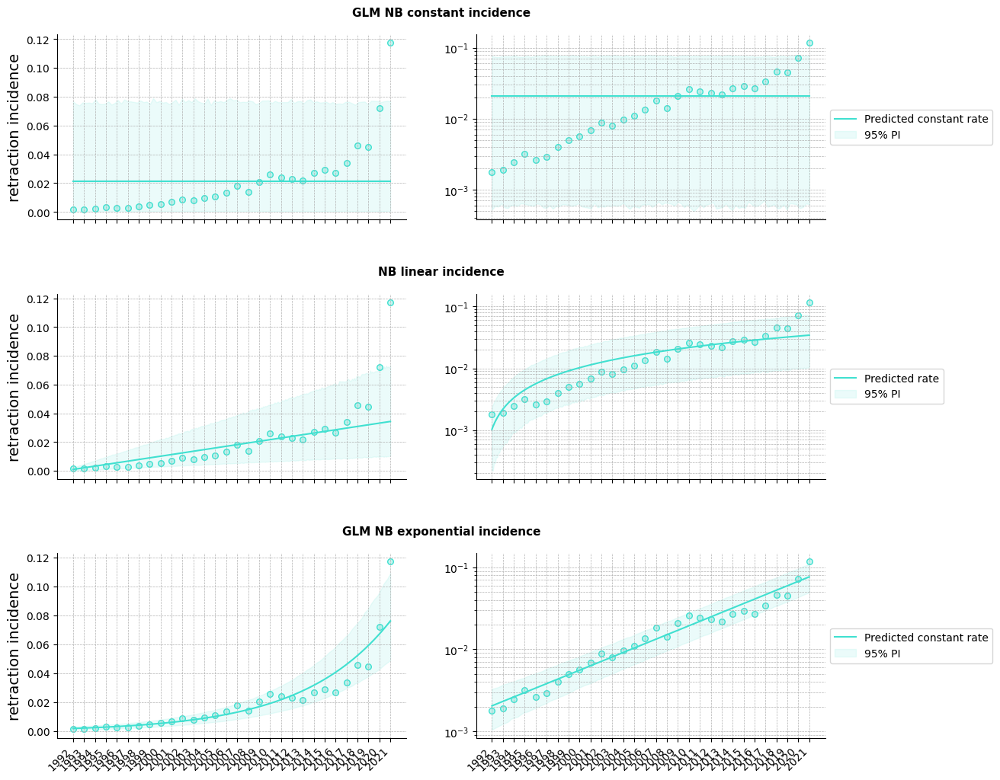

 25%|██▌       | 1/4 [00:00<00:02,  1.04it/s]

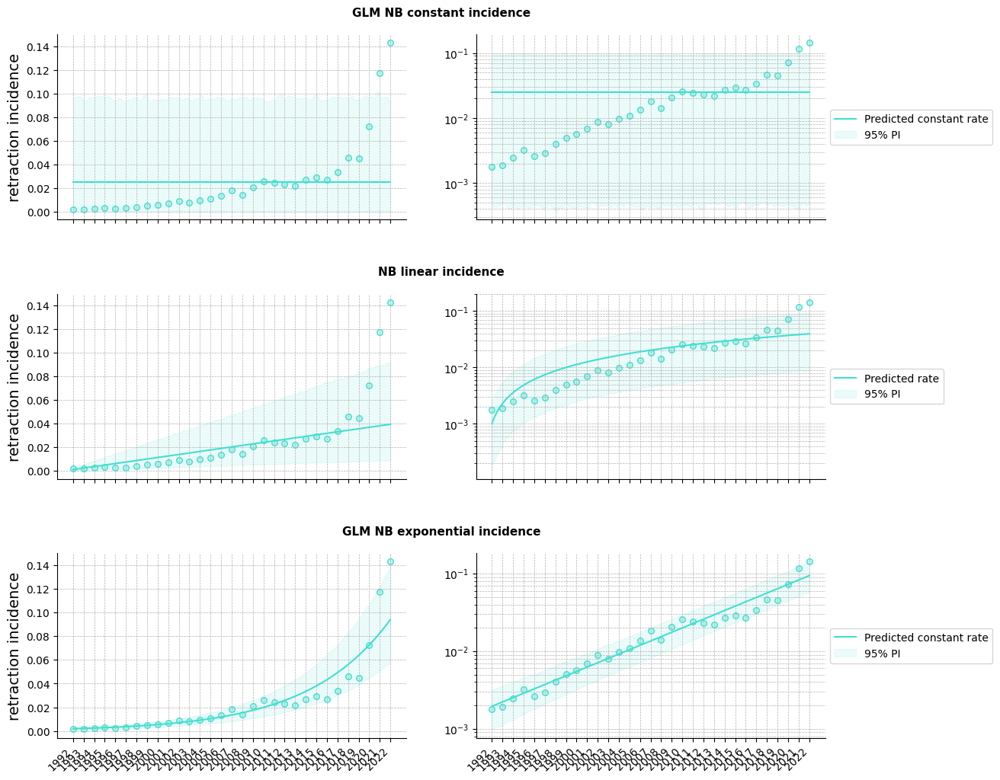

 50%|█████     | 2/4 [00:01<00:01,  1.03it/s]

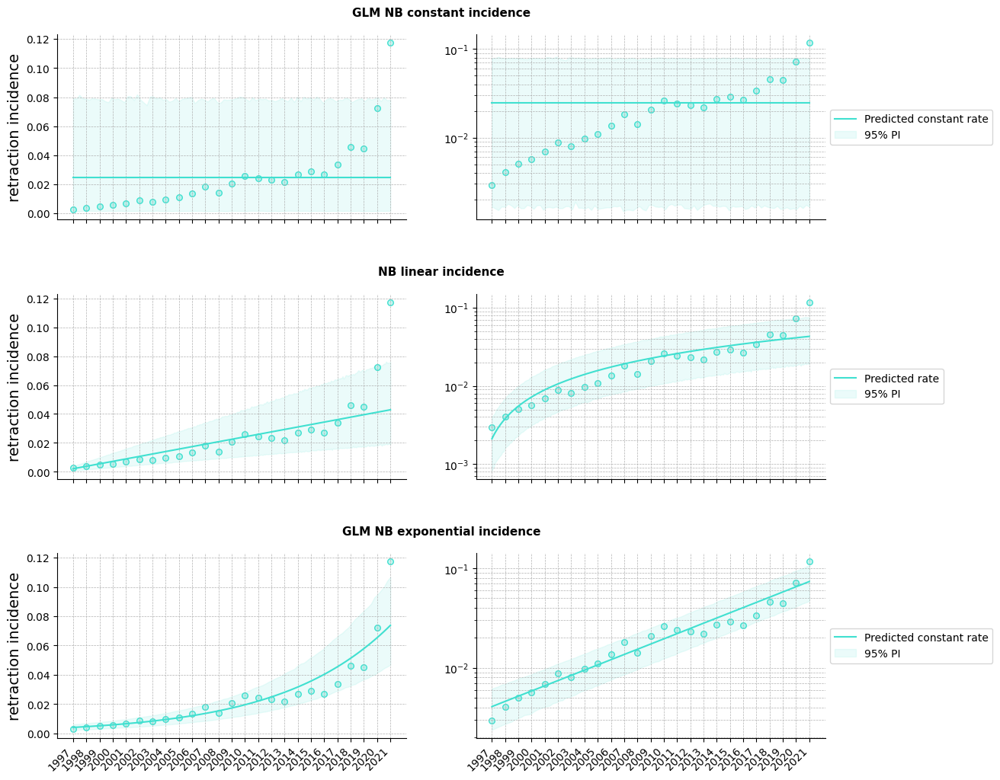

 75%|███████▌  | 3/4 [00:02<00:00,  1.00it/s]

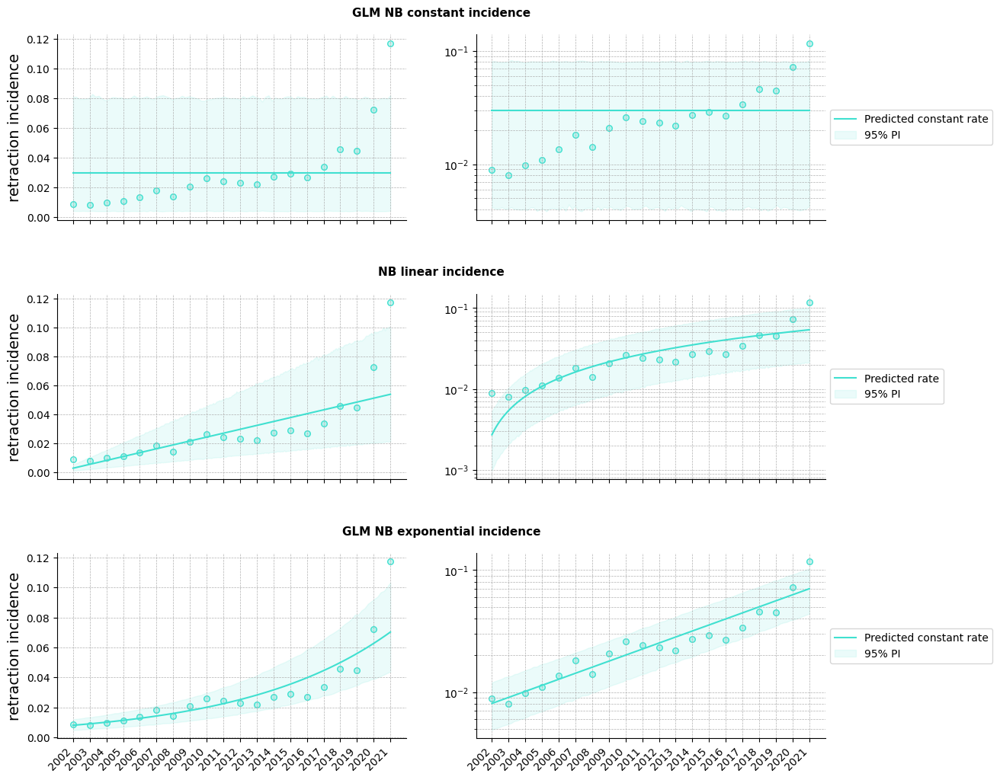

100%|██████████| 4/4 [00:03<00:00,  1.05it/s]


In [150]:
## fitting
ranges_list = [(1992,2021),(1992,2022),(1997,2021),(2002,2021)]
SCALE = 1e2
title = 'retraction incidence works'
results_ranges_df = pd.DataFrame()
for (start_year,end_year) in tqdm(ranges_list):
    df = works_retracted_count
    df = df[(df.year >= start_year) & (df.year <= end_year)]
    results_df_ = try_all_fit(SCALE,df,start_year,end_year,True,output_folder,title)
    results_ranges_df = pd.concat([results_ranges_df,results_df_])
results_ranges_df['range'] = results_ranges_df.apply(lambda x : (x['start year'], x['end year']), axis=1)

In [151]:
df = results_ranges_df
df = df[['range','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['range', 'model_order']).drop(columns='model_order')
df

,range,model,ΔBIC,ΔBIC_weighted
0,"(1992, 2021)",constant,97.797352,5.801963e-22
0,"(1992, 2021)",linear,51.135419,7.871994e-12
0,"(1992, 2021)",exponential,0.000000,1.000000e+00
0,"(1992, 2022)",constant,102.097626,6.757438e-23
0,"(1992, 2022)",linear,58.663217,1.825763e-13
0,"(1992, 2022)",exponential,0.000000,1.000000e+00
0,"(1997, 2021)",constant,70.693148,4.458372e-16
0,"(1997, 2021)",linear,25.037775,3.656912e-06
0,"(1997, 2021)",exponential,0.000000,9.999963e-01
0,"(2002, 2021)",constant,45.425607,1.367586e-10


In [152]:
results_ranges_df

,start year,end year,model,dof,parameters,BIC,a,b,alpha,p value a,p value b,doubling time,doubling time upper,doubling time lower,ΔBIC,best_model,ΔBIC_weighted,range
0,1992,2021,GLM NB constant incidence,28,2,458.012082,-8.462918,NaN,0.957081,0.000000,NaN,NaN,NaN,NaN,97.797352,0,5.801963e-22,"(1992, 2021)"
0,1992,2021,NB linear incidence,27,3,411.350150,0.000010,0.000012,0.222196,0.003388,5.095773e-25,NaN,NaN,NaN,51.135419,0,7.871994e-12,"(1992, 2021)"
0,1992,2021,GLM NB exponential incidence,27,3,360.214730,-10.797708,0.124799,0.040706,0.000000,9.886845e-149,5.554128,6.030523,5.147490,0.000000,1,1.000000e+00,"(1992, 2021)"
0,1992,2022,GLM NB constant incidence,29,2,484.498725,-8.292370,NaN,1.098608,0.000000,NaN,NaN,NaN,NaN,102.097626,0,6.757438e-23,"(1992, 2022)"
0,1992,2022,NB linear incidence,28,3,441.064315,0.000010,0.000013,0.305090,0.009479,5.263481e-20,NaN,NaN,NaN,58.663217,0,1.825763e-13,"(1992, 2022)"
0,1992,2022,GLM NB exponential incidence,28,3,382.401098,-10.846742,0.129210,0.048254,0.000000,7.280085e-158,5.364512,5.809016,4.983200,0.000000,1,1.000000e+00,"(1992, 2022)"
0,1997,2021,GLM NB constant incidence,23,2,396.312351,-8.299889,NaN,0.691510,0.000000,NaN,NaN,NaN,NaN,70.693148,0,4.458372e-16,"(1997, 2021)"
0,1997,2021,NB linear incidence,22,3,350.656979,0.000021,0.000017,0.116483,0.000085,2.433468e-32,NaN,NaN,NaN,25.037775,0,3.656912e-06,"(1997, 2021)"
0,1997,2021,GLM NB exponential incidence,22,3,325.619203,-10.110168,0.120737,0.042641,0.000000,3.387515e-89,5.740985,6.404263,5.202203,0.000000,1,9.999963e-01,"(1997, 2021)"
0,2002,2021,GLM NB constant incidence,18,2,327.131054,-8.117221,NaN,0.460907,0.000000,NaN,NaN,NaN,NaN,45.425607,0,1.367586e-10,"(2002, 2021)"


In [153]:
df = results_ranges_df[results_ranges_df.best_model==1][['range','alpha','b','p value b','doubling time','doubling time lower','doubling time upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'})
df.head()

,range,alpha,g,p-value,doubling time,doubling time lower,doubling time upper
0,"(1992, 2021)",0.040706,0.124799,9.886845e-149,5.554128,5.147490,6.030523
0,"(1992, 2022)",0.048254,0.129210,7.280085e-158,5.364512,4.983200,5.809016
0,"(1997, 2021)",0.042641,0.120737,3.387515e-89,5.740985,5.202203,6.404263
0,"(2002, 2021)",0.046331,0.113998,1.538389e-43,6.080338,5.275856,7.174302


### Overdispersion test
alpha = 1 / r

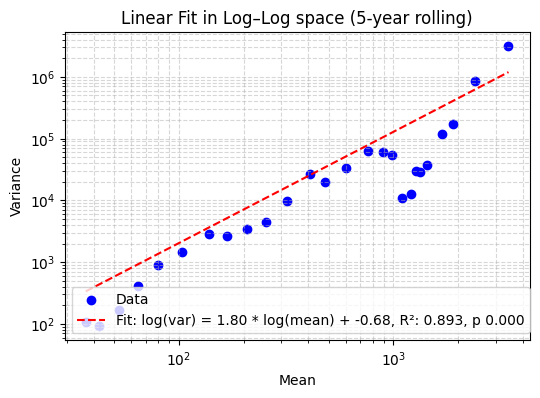

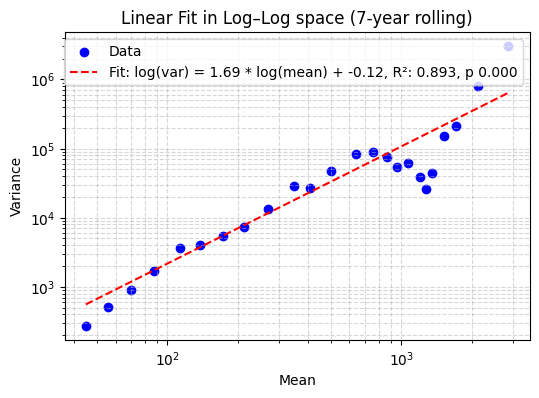

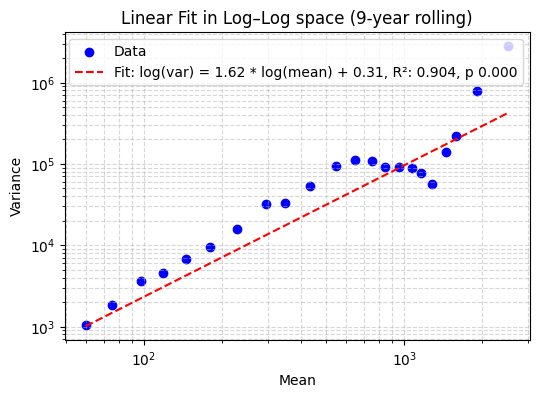

In [17]:
def objective(r):
    if r <= 0:
        return np.inf
    var_model = xdata + xdata**2 / r
    return np.sum((ydata - var_model)**2)
def power_law(x, a, b):
    return a * x**b

df = works_retracted_count.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)].reset_index(drop=True)   

for window_size in [5,7,9]:

    df_ = df.copy()
    df_['mean'] = df_.rolling(window=window_size).retracted.mean()
    df_['var'] = df_.rolling(window=window_size).retracted.var(ddof=0)
    df_clean = df_.dropna(subset=['mean', 'var'])
    xdata = df_clean['mean'].values
    ydata = df_clean['var'].values

    x = np.log10(xdata)
    y = np.log10(ydata)
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    x_fit = np.linspace(df_clean['mean'].min(), df_clean['mean'].max(), 200)
    y_fit = np.exp(intercept) * x_fit**slope

    popt, pcov = curve_fit(power_law, xdata, ydata, p0=[0.5, 1])  # initial guesses
    intercept2, slope2 = popt
    perr = np.sqrt(np.diag(pcov))
    n = len(ydata)
    tvals = popt / perr
    pvals = 2 * (1 - stats.t.cdf(np.abs(tvals), n - len(popt)))
    p_value2 = pvals[1]
    y_fit2 = intercept2 * x_fit**slope2

    plt.figure(figsize=(6,4))
    plt.scatter(xdata, ydata, label='Data', color='blue')
    plt.plot(x_fit, y_fit, color='red', linestyle='--', label=f'Fit: log(var) = {slope:.2f} * log(mean) + {intercept:.2f}, R²: {r_value**2:.3f}, p {p_value:.3f}')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel('Mean')
    plt.ylabel('Variance')
    plt.title(f'Linear Fit in Log–Log space ({window_size}-year rolling)')
    plt.legend()
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.show()

## Domains

Download OpenAlex topics hierarchy: https://docs.google.com/spreadsheets/d/1v-MAq64x4YjhO7RWcB-yrKV5D_2vOOsxl4u6GBKEXY8/edit?gid=983250122#gid=983250122

In [18]:
df_topics = pd.read_csv('OpenAlex_topic_mapping_table - final_topic_field_subfield_table.csv')
df_topics = df_topics.sort_values(by=['topic_id','subfield_id','field_id','domain_id']) #rescale topics
df_topics = df_topics.sort_values(by=['domain_id','field_id','subfield_id','topic_id']).reset_index(drop=True)
df_topics = df_topics.reset_index().rename(columns={'index':'topic_id_scaled'})
df_topics['subfield_id_scaled'] = pd.factorize(df_topics.subfield_id)[0]
df_topics['field_id_scaled'] = pd.factorize(df_topics.field_id)[0]
df_topics['domain_id_scaled'] = pd.factorize(df_topics.domain_id)[0]

topic_id_name_dict = df_topics[['topic_id','topic_name']].set_index('topic_id').to_dict()['topic_name']
domain_id_name_dict = df_topics[['domain_id','domain_name']].drop_duplicates().set_index('domain_id').to_dict()['domain_name']
field_id_name_dict = df_topics[['field_id','field_name']].drop_duplicates().set_index('field_id').to_dict()['field_name']
subfield_id_name_dict = df_topics[['subfield_id','subfield_name']].drop_duplicates().set_index('subfield_id').to_dict()['subfield_name']

set_topics = set(df_topics.topic_id)
set_subfields = set(df_topics.subfield_id)
set_fields = set(df_topics.field_id)
set_domains = set(df_topics.domain_id)

n_topics = len(set_topics)
n_subfields = len(set_subfields)
n_fields = len(set_fields)
n_domains = len(set_domains)
print(f'{n_topics} topics, {n_subfields} subfields, {n_fields} fields, {n_domains} domains')

topic_id_list = list(df_topics.topic_id_scaled)

dict_topics_id_scaled = df_topics[['topic_id','topic_id_scaled']].set_index('topic_id').to_dict()['topic_id_scaled']
dict_subfield_id_scaled = df_topics[['subfield_id','subfield_id_scaled']].set_index('subfield_id').to_dict()['subfield_id_scaled']
dict_field_id_scaled = df_topics[['field_id','field_id_scaled']].set_index('field_id').to_dict()['field_id_scaled']
dict_field_id_scaled2 = df_topics[['field_id','field_id_scaled']].set_index('field_id_scaled').to_dict()['field_id']
dict_domains_id_scaled = df_topics[['domain_id','domain_id_scaled']].set_index('domain_id').to_dict()['domain_id_scaled']
topic_id_scaled_name_dict = df_topics[['topic_id_scaled','topic_name']].set_index('topic_id_scaled').to_dict()['topic_name']
subfield_id_scaled_name_dict = df_topics[['subfield_id_scaled','subfield_name']].drop_duplicates().set_index('subfield_id_scaled').to_dict()['subfield_name']
field_id_scaled_name_dict = df_topics[['field_id_scaled','field_name']].drop_duplicates().set_index('field_id_scaled').to_dict()['field_name']
field_name_id_dict = df_topics[['field_id','field_name']].drop_duplicates().set_index('field_name').to_dict()['field_id']
domain_id_scaled_name_dict = df_topics[['domain_id_scaled','domain_name']].drop_duplicates().set_index('domain_id_scaled').to_dict()['domain_name']
field_name_domain_name_dict = df_topics[['field_name','domain_name']].drop_duplicates().set_index('field_name').to_dict()['domain_name']

field_topic_indices = df_topics[['topic_id_scaled','field_id_scaled']].groupby('field_id_scaled').topic_id_scaled.apply(set).to_dict()
subfield_topic_indices = df_topics[['topic_id_scaled','subfield_id_scaled']].groupby('subfield_id_scaled').topic_id_scaled.apply(set).to_dict()

4516 topics, 252 subfields, 26 fields, 4 domains


In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_retracted_count_byfield` AS

  WITH works_topics_filtered AS (
    SELECT
      publication_year,
      is_retracted,
      work_id,
      field_id
    FROM
      `project_name.dataset_name.works_topics`
    WHERE
      publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  ),

  -- Count number of fields per work (to weight each work by 1 / number_of_fields)
  fields_per_work AS (
    SELECT
      work_id,
      COUNT(DISTINCT field_id) AS num_fields
    FROM
      works_topics_filtered
    GROUP BY work_id
    HAVING COUNT(DISTINCT field_id) > 0 
  ),

  -- Join back to assign weight per work-field combination
  works_weighted AS (
    SELECT
      w.publication_year,
      w.field_id,
      w.is_retracted,
      1.0 / fpw.num_fields AS work_field_weight
    FROM
      works_topics_filtered w
    JOIN
      fields_per_work fpw
    ON
      w.work_id = fpw.work_id
  )

  -- Final aggregation by year and field
  SELECT
    publication_year,
    field_id,
    SUM(work_field_weight) AS total_weight,
    SUM(CASE WHEN is_retracted = 1 THEN work_field_weight ELSE 0 END) AS retracted_weight
  FROM
    works_weighted
  GROUP BY
    publication_year,
    field_id
  ORDER BY
    publication_year,
    field_id;
"""
##output info
new_table_name = "works_retracted_count_byfield"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Retracted/Plots/plots_domains'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_retracted_count_bydomain = pd.read_csv(f'./Retracted/Data/works_retracted_count_byfield.csv.gz', compression='gzip').rename(columns={'publication_year':'year'}).dropna()
works_retracted_count_bydomain['year'] = works_retracted_count_bydomain['year'].str[:4].astype(int)
works_retracted_count_bydomain = works_retracted_count_bydomain.merge(df_topics[['field_id','domain_id']].drop_duplicates(),on='field_id').drop(columns='field_id')
works_retracted_count_bydomain = works_retracted_count_bydomain.groupby(['domain_id','year']).sum().reset_index()
works_retracted_count_bydomain = works_retracted_count_bydomain.rename(columns={'total_weight':'total','retracted_weight':'retracted'})
works_retracted_count_bydomain = works_retracted_count_bydomain.merge(df_topics[['domain_id','domain_name']].drop_duplicates(),on='domain_id')
works_retracted_count_bydomain = works_retracted_count_bydomain[['domain_name','domain_id','year','total','retracted']].sort_values(by=['domain_name','year'])
works_retracted_count_bydomain = works_retracted_count_bydomain[(works_retracted_count_bydomain.year>=1980) & (works_retracted_count_bydomain.year<=2024)].reset_index(drop=True)

  0%|          | 0/4 [00:00<?, ?it/s]

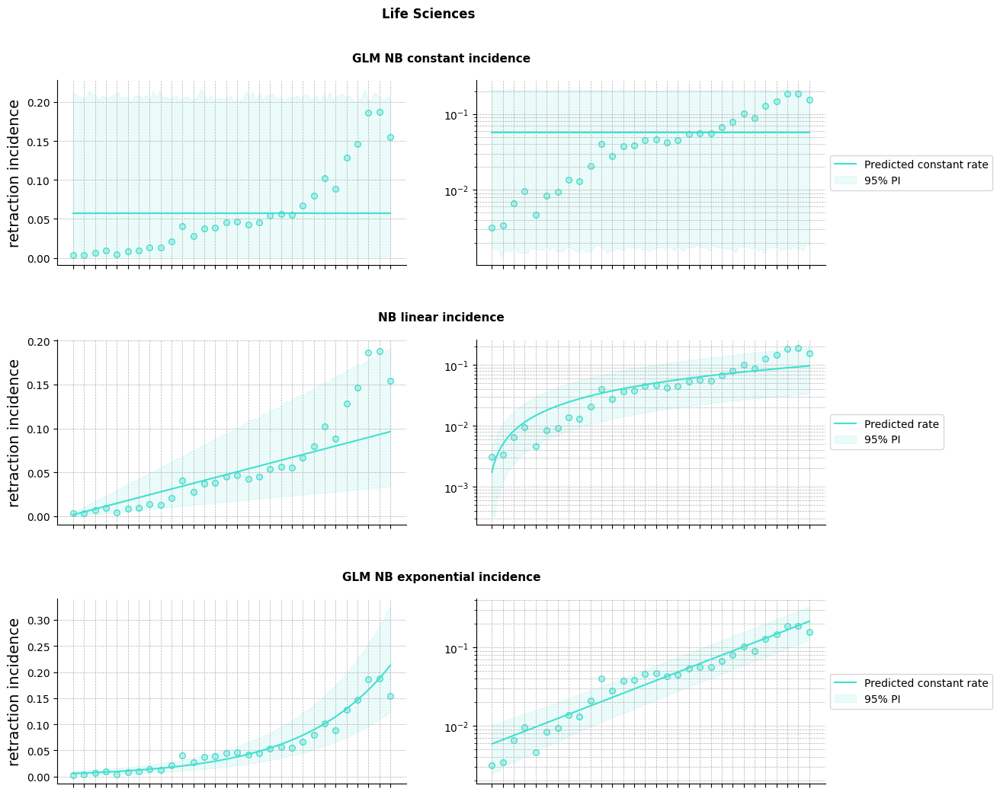

 25%|██▌       | 1/4 [00:00<00:02,  1.04it/s]

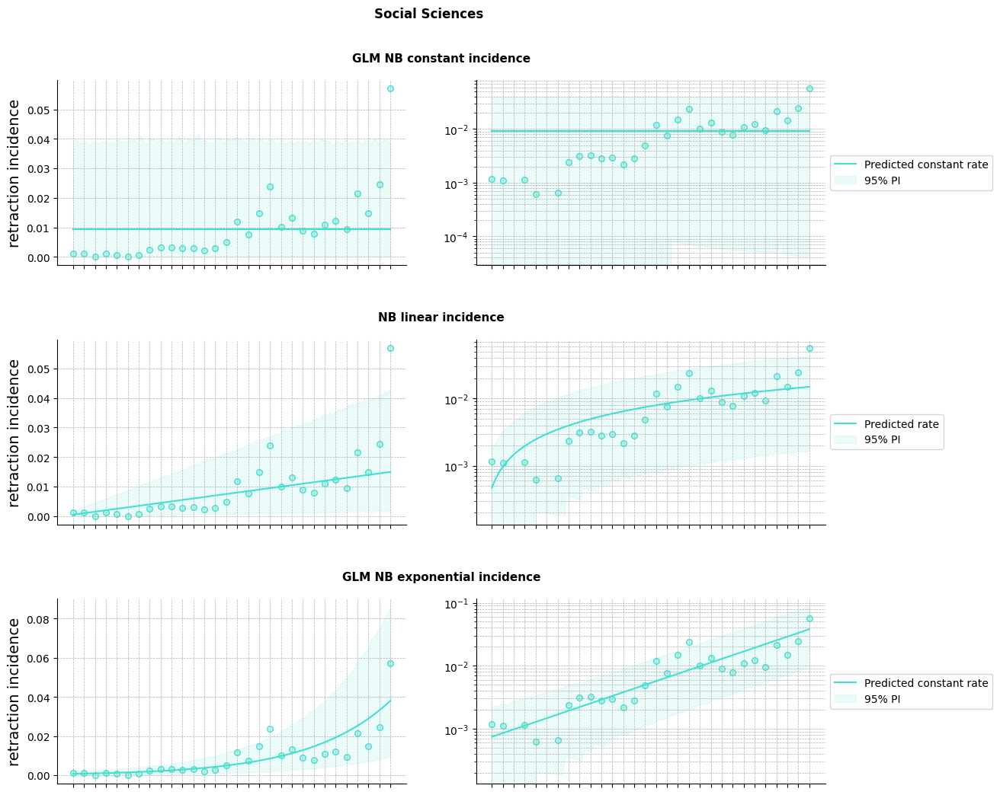

 50%|█████     | 2/4 [00:01<00:01,  1.03it/s]

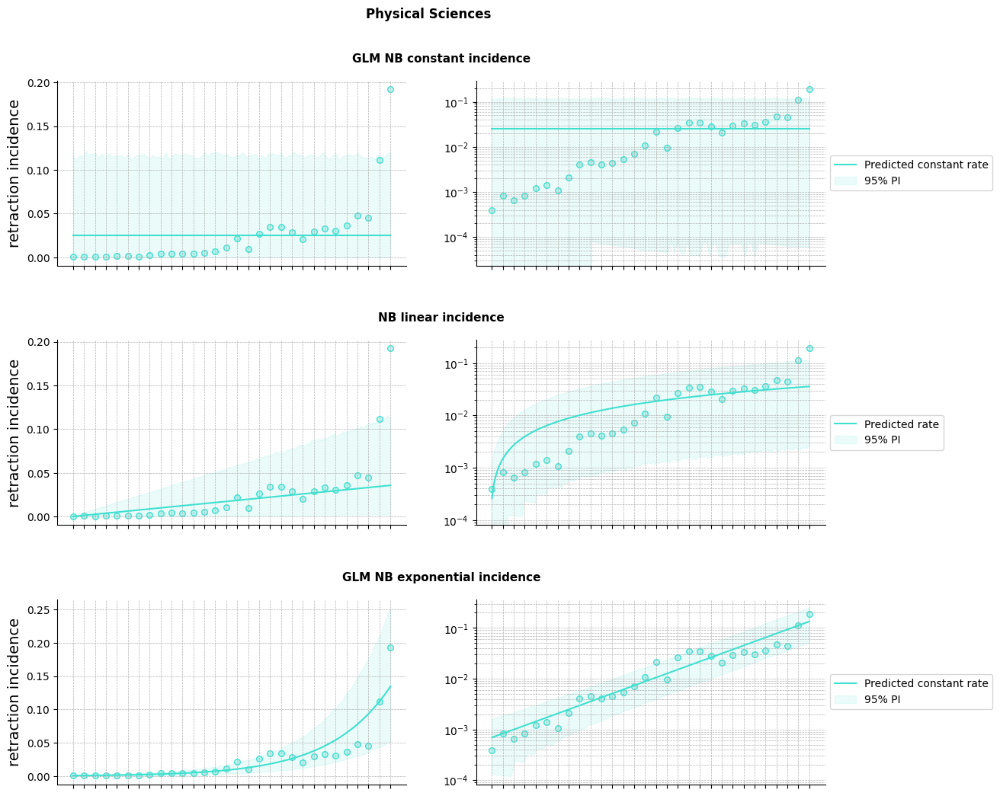

 75%|███████▌  | 3/4 [00:02<00:00,  1.03it/s]

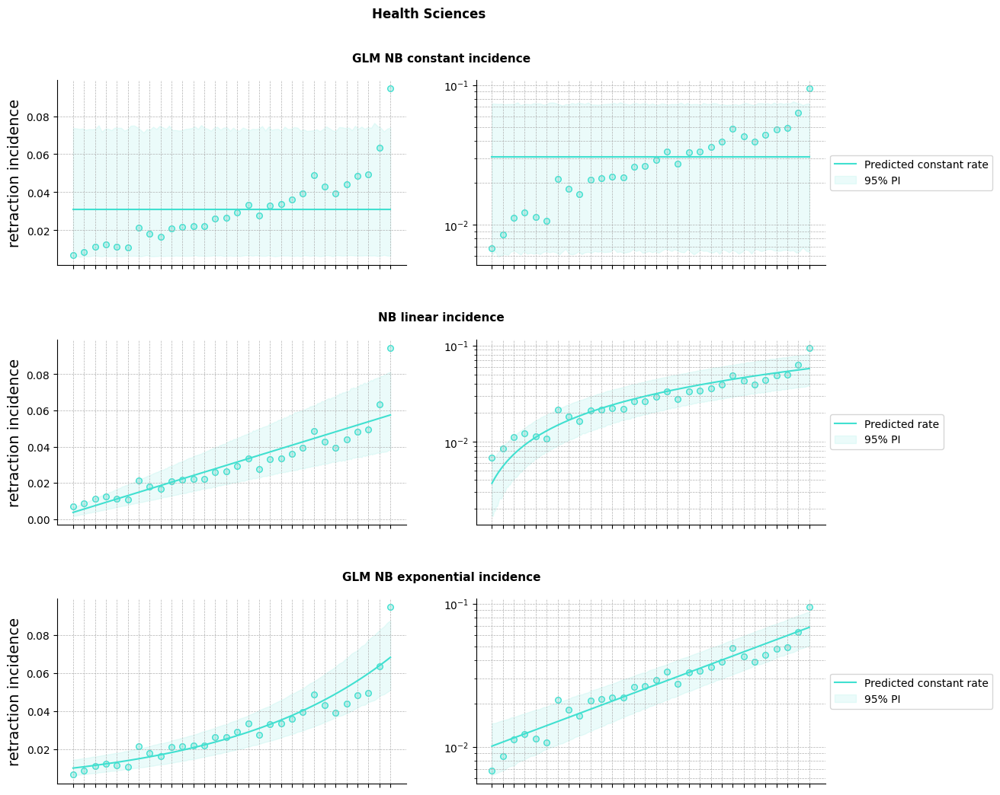

100%|██████████| 4/4 [00:03<00:00,  1.07it/s]


In [21]:
SCALE = 1e2
df = works_retracted_count_bydomain.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_domains_df = pd.DataFrame()
for i in tqdm(range(1,n_domains+1)):
    df_i = df[df.domain_id==i]
    results_df = try_all_fit(SCALE,df_i,start_year,end_year,True,output_folder,title,domain_id_name_dict,i)
    results_domains_df = pd.concat([results_domains_df,results_df])
results_domains_df = results_domains_df.rename(columns={'field_id_scaled':'domain_id','field_name':'domain_name'})

In [22]:
results_domains_df

,domain_id,domain_name,start year,end year,model,dof,parameters,BIC,a,b,alpha,p value a,p value b,doubling time,doubling time upper,doubling time lower,ΔBIC,best_model,ΔBIC_weighted
0,1,Life Sciences,1992,2021,GLM NB constant incidence,28,2,419.141092,-7.461954,NaN,0.939339,0.000000e+00,NaN,NaN,NaN,NaN,80.043329,0,4.157303e-18
0,1,Life Sciences,1992,2021,NB linear incidence,27,3,367.189658,0.000018,0.000033,0.175526,1.260073e-02,1.126128e-32,NaN,NaN,NaN,28.091895,0,7.941860e-07
0,1,Life Sciences,1992,2021,GLM NB exponential incidence,27,3,339.097763,-9.739684,0.123730,0.058621,0.000000e+00,6.565184e-92,5.602108,6.230873,5.088609,0.000000,1,9.999992e-01
0,2,Social Sciences,1992,2021,GLM NB constant incidence,28,2,338.640378,-9.283818,NaN,1.347438,0.000000e+00,NaN,NaN,NaN,NaN,41.893088,0,7.998922e-10
0,2,Social Sciences,1992,2021,GLM NB exponential incidence,27,3,296.747290,-11.810593,0.135692,0.276843,0.000000e+00,2.639045e-23,5.108236,6.436042,4.234603,0.000000,1,1.000000e+00
0,3,Physical Sciences,1992,2021,GLM NB constant incidence,28,2,425.638278,-8.293409,NaN,1.697347,4.029628e-266,NaN,NaN,NaN,NaN,79.799649,0,4.695981e-18
0,3,Physical Sciences,1992,2021,GLM NB exponential incidence,27,3,345.838629,-11.878841,0.181583,0.151035,0.000000e+00,9.283227e-75,3.817237,4.299467,3.432273,0.000000,1,1.000000e+00
0,4,Health Sciences,1992,2021,GLM NB constant incidence,28,2,399.699994,-8.087523,NaN,0.323300,0.000000e+00,NaN,NaN,NaN,NaN,77.524593,0,1.464570e-17
0,4,Health Sciences,1992,2021,NB linear incidence,27,3,340.845456,0.000037,0.000019,0.036015,6.232871e-09,1.054984e-73,NaN,NaN,NaN,18.670054,0,8.826954e-05
0,4,Health Sciences,1992,2021,GLM NB exponential incidence,27,3,322.175401,-9.201001,0.065868,0.018506,0.000000e+00,1.277121e-82,10.523281,11.778385,9.509907,0.000000,1,9.999117e-01


In [23]:
df = results_domains_df
df = df[['domain_name','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['domain_name', 'model_order']).drop(columns='model_order')
df

,domain_name,model,ΔBIC,ΔBIC_weighted
0,Health Sciences,constant,77.524593,1.464570e-17
0,Health Sciences,linear,18.670054,8.826954e-05
0,Health Sciences,exponential,0.000000,9.999117e-01
0,Life Sciences,constant,80.043329,4.157303e-18
0,Life Sciences,linear,28.091895,7.941860e-07
0,Life Sciences,exponential,0.000000,9.999992e-01
0,Physical Sciences,constant,79.799649,4.695981e-18
0,Physical Sciences,exponential,0.000000,1.000000e+00
0,Social Sciences,constant,41.893088,7.998922e-10
0,Social Sciences,exponential,0.000000,1.000000e+00


In [24]:
df = results_domains_df[results_domains_df.best_model==1][['domain_name','alpha','b','p value b','doubling time','doubling time lower','doubling time upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'}).sort_values(by='domain_name')
df

,domain_name,alpha,g,p-value,doubling time,doubling time lower,doubling time upper
0,Health Sciences,0.018506,0.065868,1.277121e-82,10.523281,9.509907,11.778385
0,Life Sciences,0.058621,0.123730,6.565184e-92,5.602108,5.088609,6.230873
0,Physical Sciences,0.151035,0.181583,9.283227e-75,3.817237,3.432273,4.299467
0,Social Sciences,0.276843,0.135692,2.639045e-23,5.108236,4.234603,6.436042


## Fields

Look at Domains for BigQuery query.

In [ ]:
output_folder = './Retracted/Plots/plots_fields'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
#weighted or unweighted?
works_retracted_count_byfield = pd.read_csv(f'./Retracted/Data/works_retracted_count_byfield.csv.gz', compression='gzip').rename(columns={'publication_year':'year'}).dropna()
works_retracted_count_byfield['year'] = works_retracted_count_byfield['year'].str[:4].astype(int)
works_retracted_count_byfield['field_id'] = works_retracted_count_byfield['field_id'].astype(int)
works_retracted_count_byfield['field_id_scaled'] = works_retracted_count_byfield['field_id'].map(dict_field_id_scaled)
works_retracted_count_byfield = works_retracted_count_byfield.rename(columns={'total_weight':'total','retracted_weight':'retracted'})

  0%|          | 0/26 [00:00<?, ?it/s]

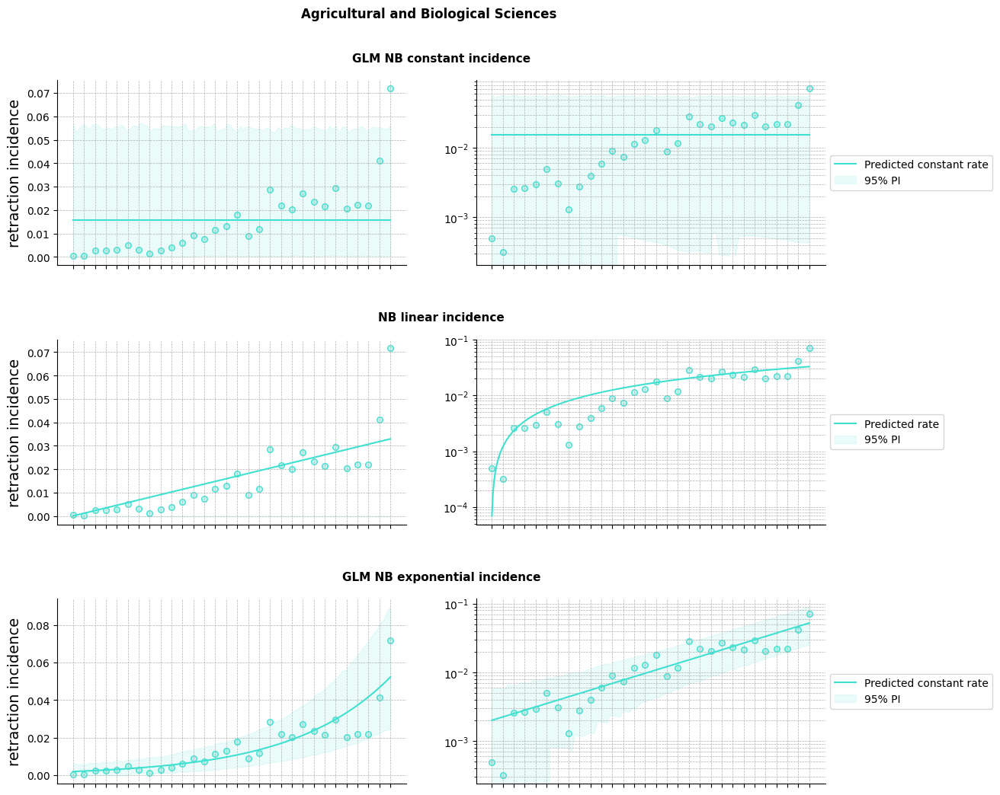

  4%|▍         | 1/26 [00:00<00:22,  1.12it/s]

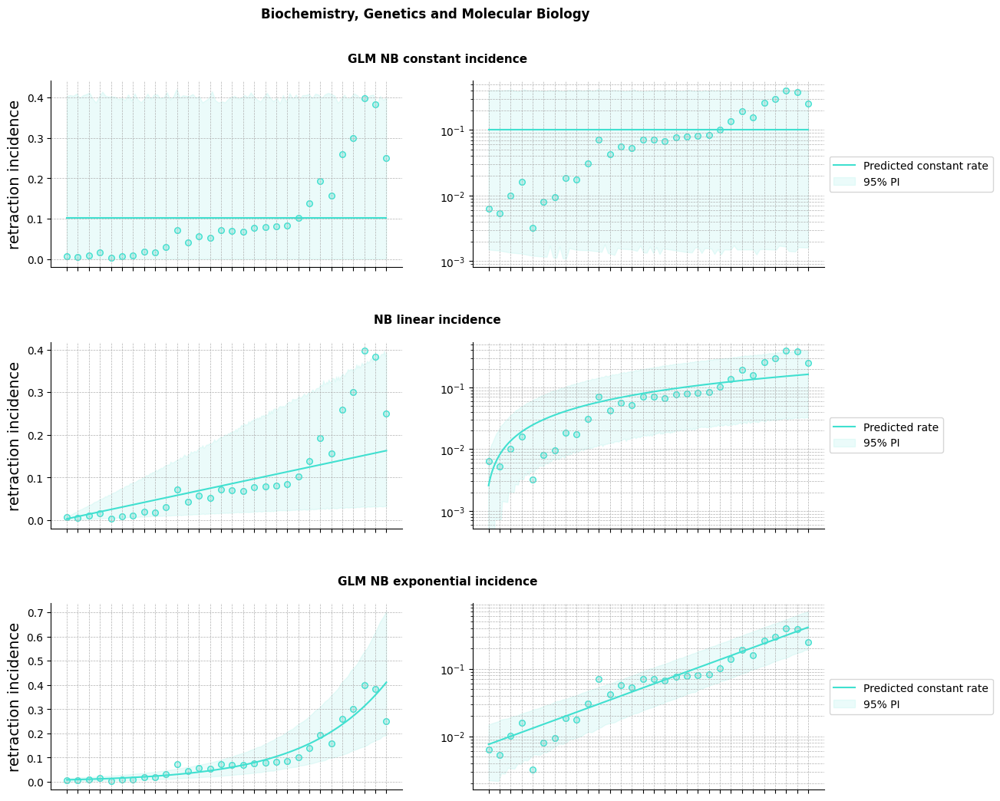

  8%|▊         | 2/26 [00:01<00:21,  1.12it/s]

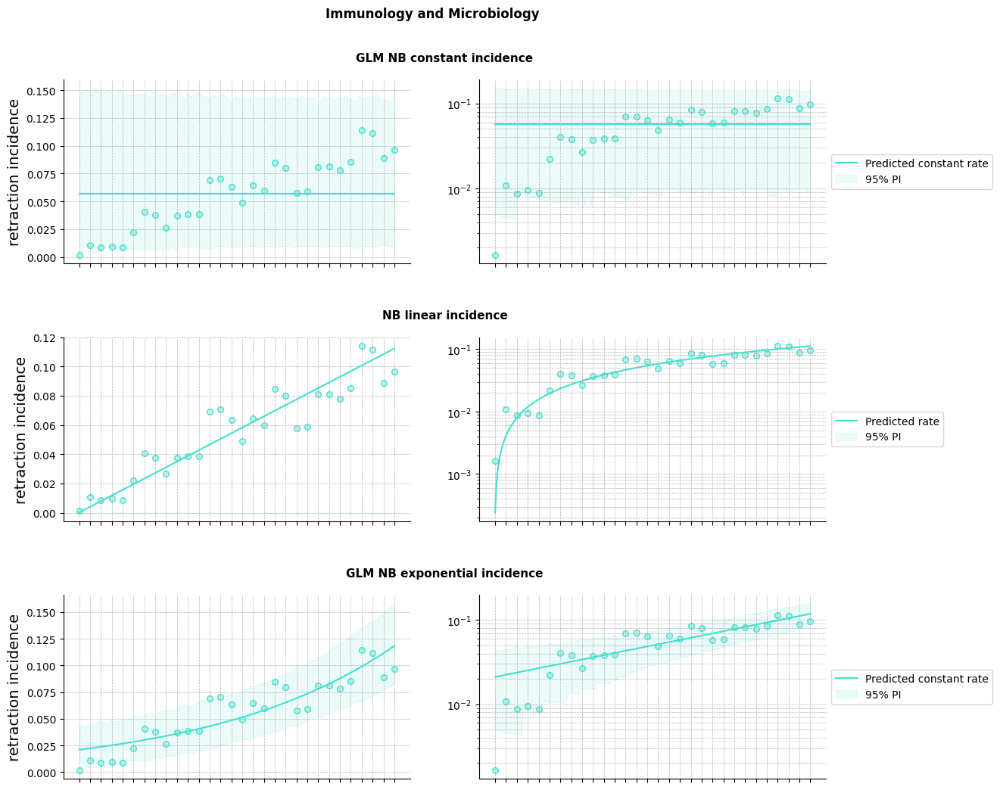

 12%|█▏        | 3/26 [00:02<00:20,  1.15it/s]

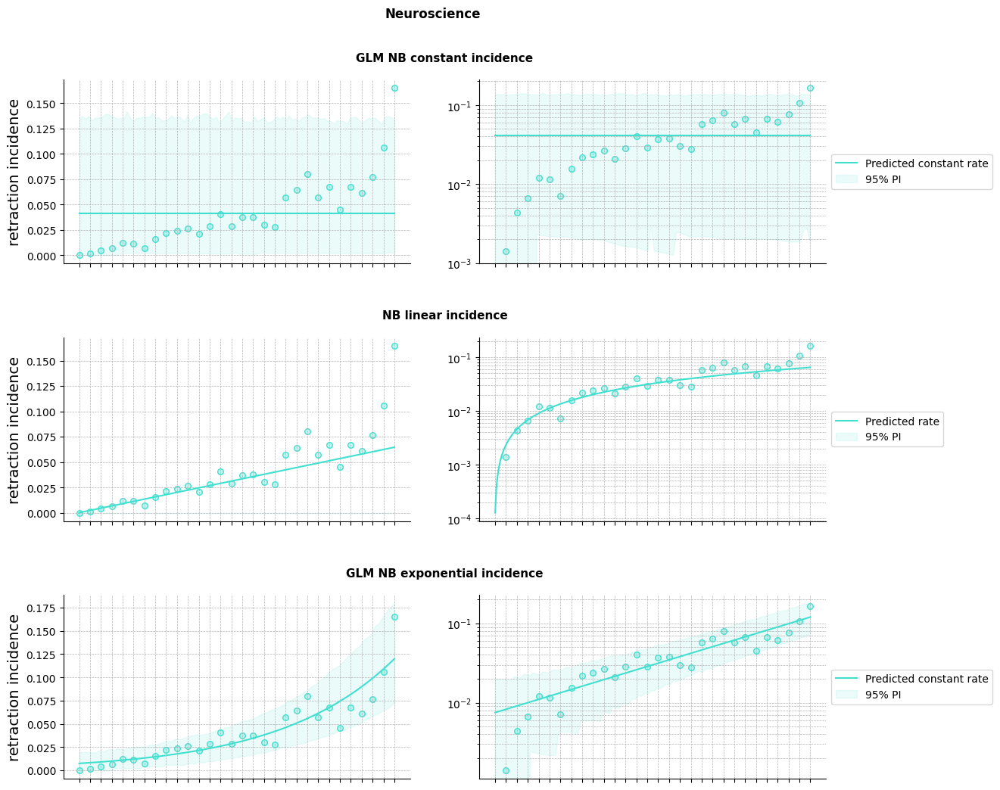

 15%|█▌        | 4/26 [00:03<00:19,  1.15it/s]

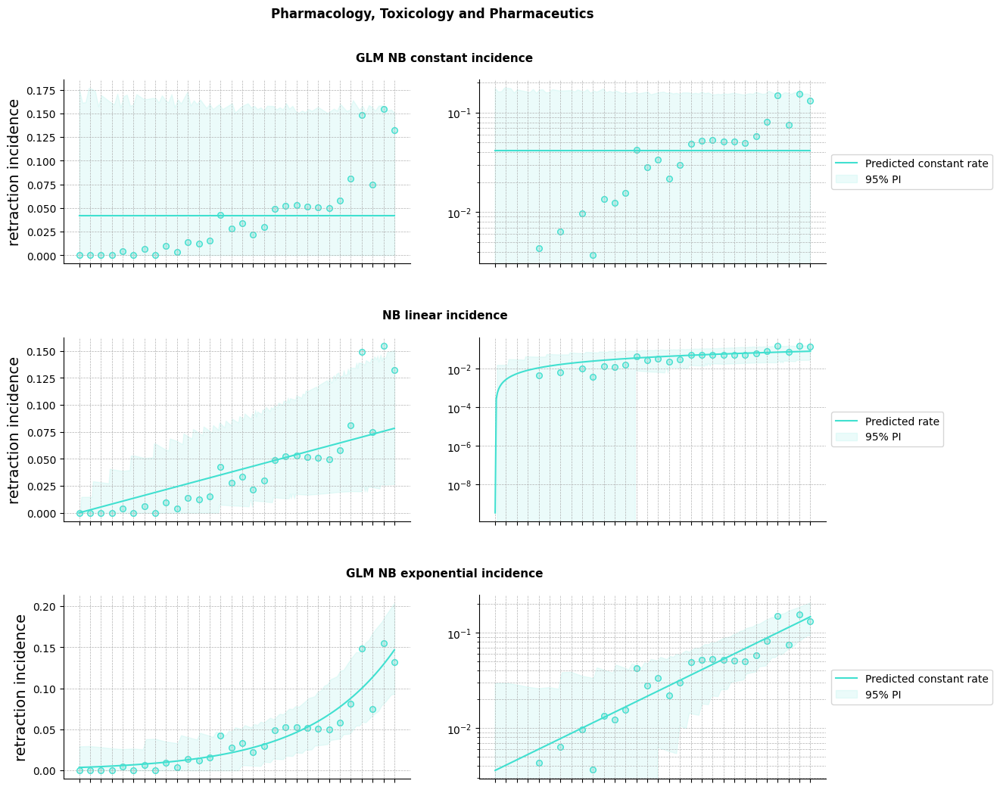

 19%|█▉        | 5/26 [00:04<00:18,  1.12it/s]

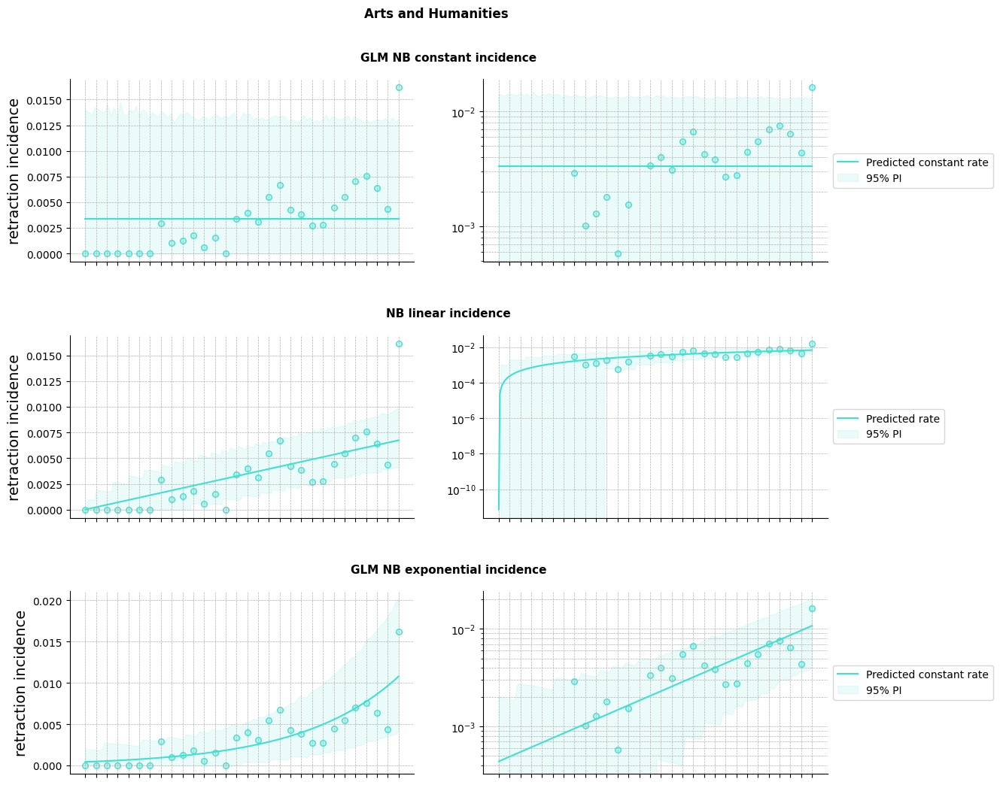

 23%|██▎       | 6/26 [00:05<00:18,  1.07it/s]

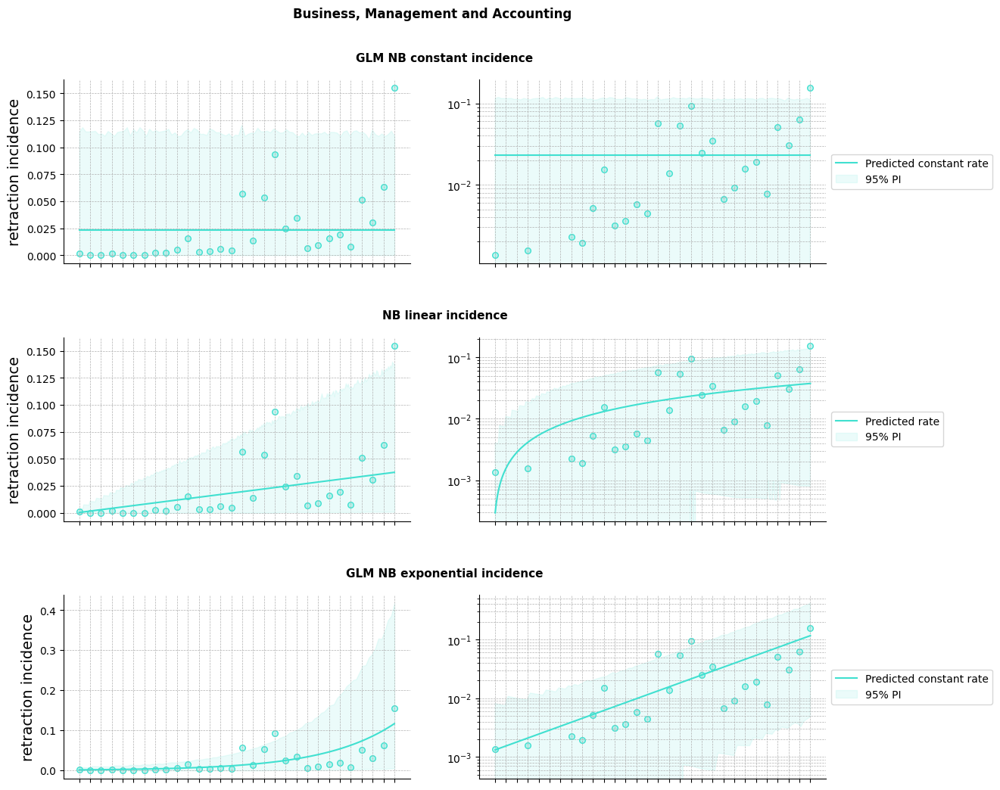

 27%|██▋       | 7/26 [00:06<00:18,  1.04it/s]

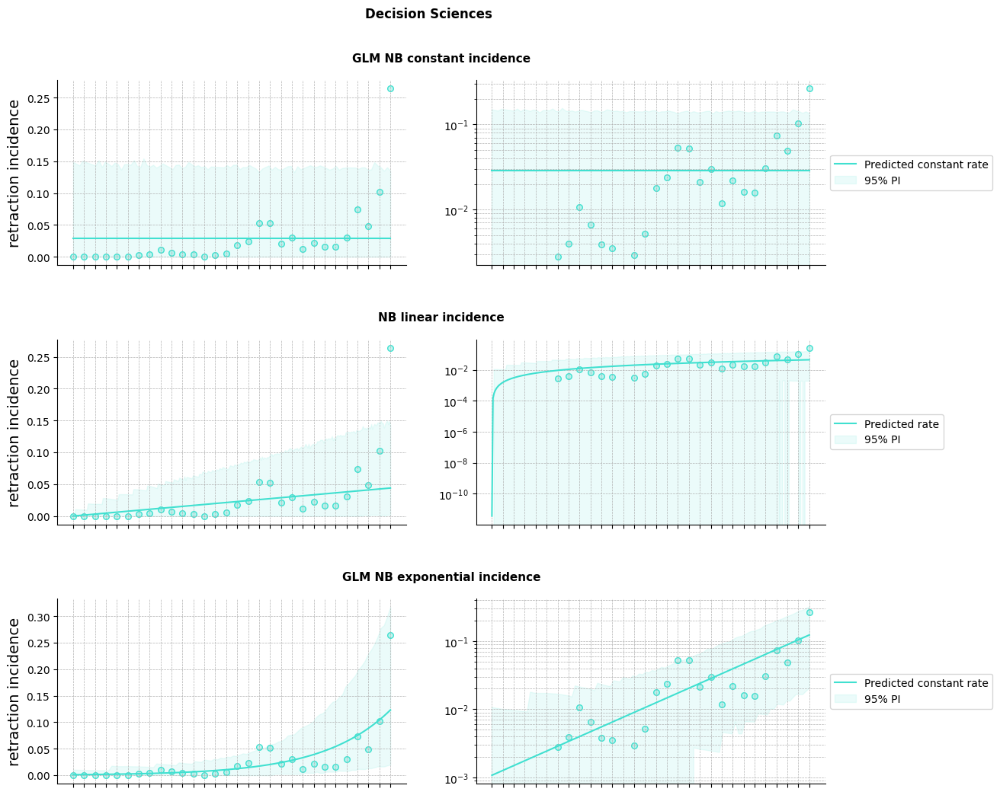

 31%|███       | 8/26 [00:07<00:17,  1.04it/s]

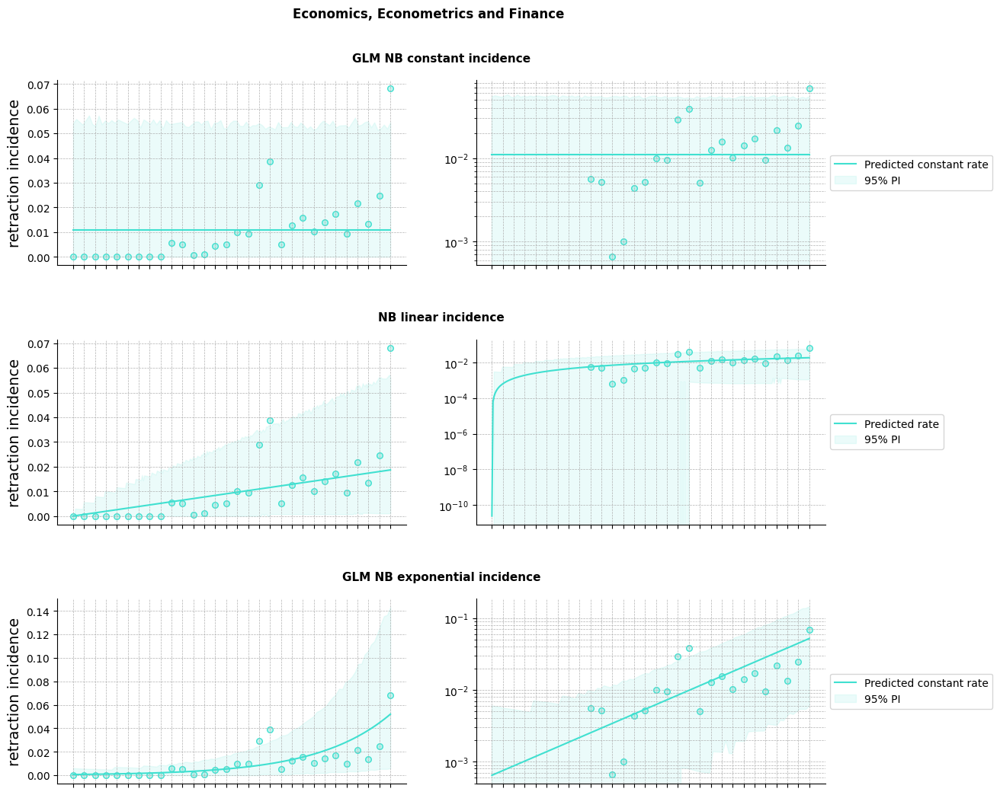

 35%|███▍      | 9/26 [00:08<00:16,  1.02it/s]

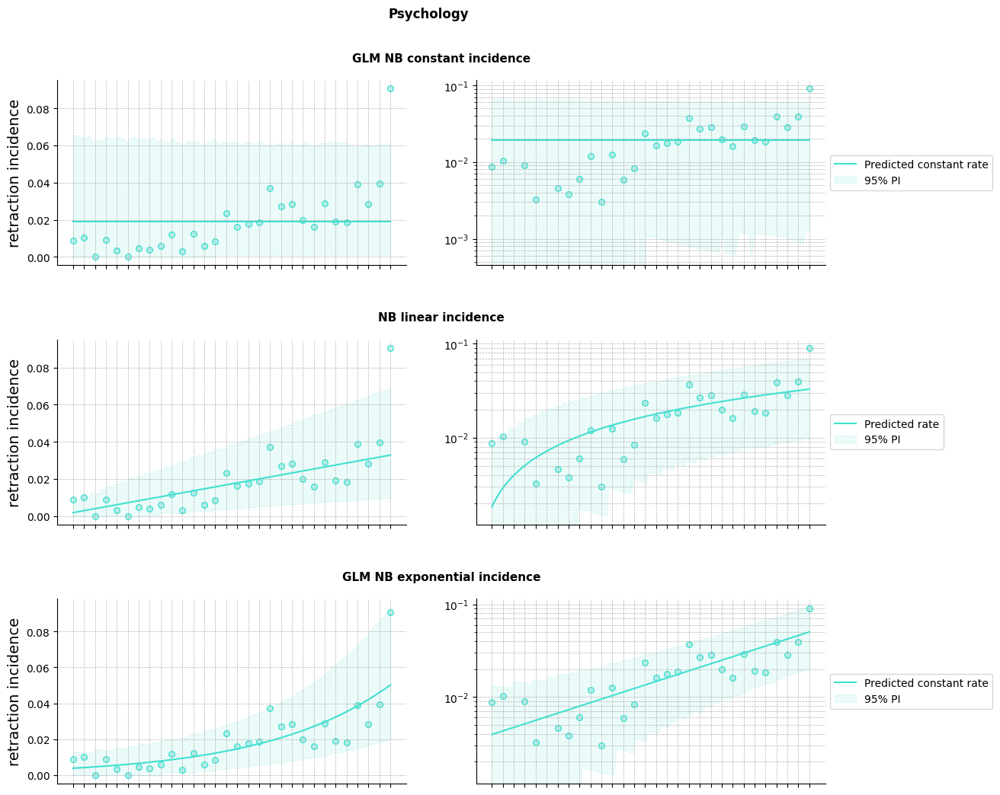

 38%|███▊      | 10/26 [00:09<00:15,  1.04it/s]

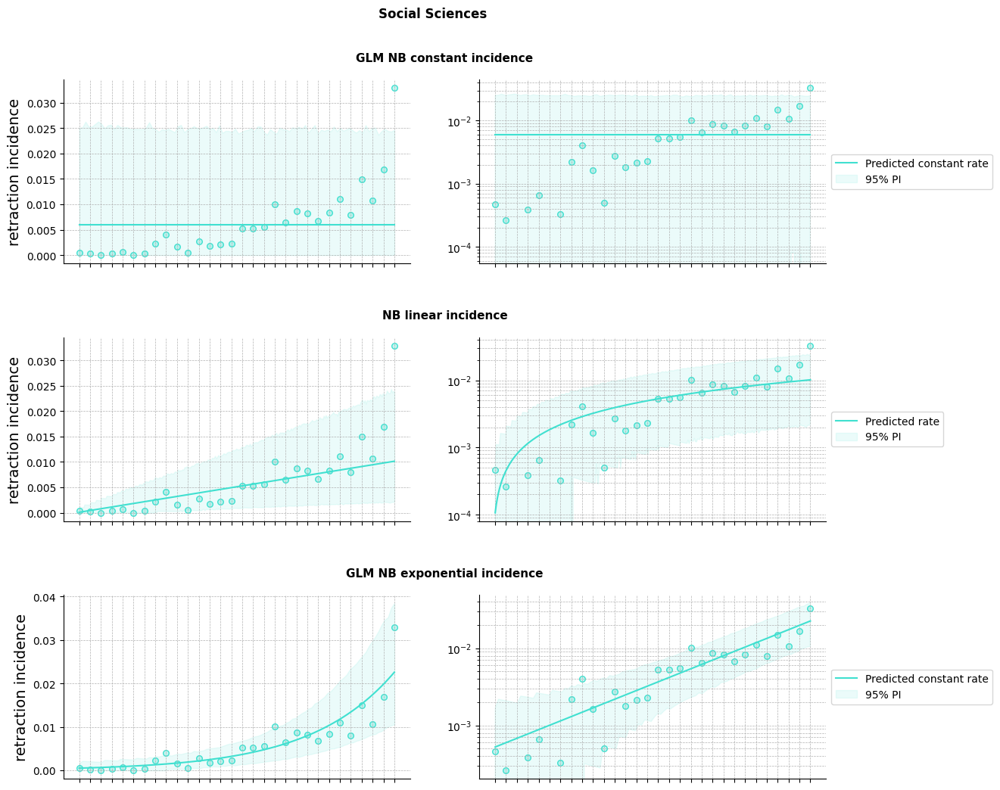

 42%|████▏     | 11/26 [00:10<00:14,  1.02it/s]

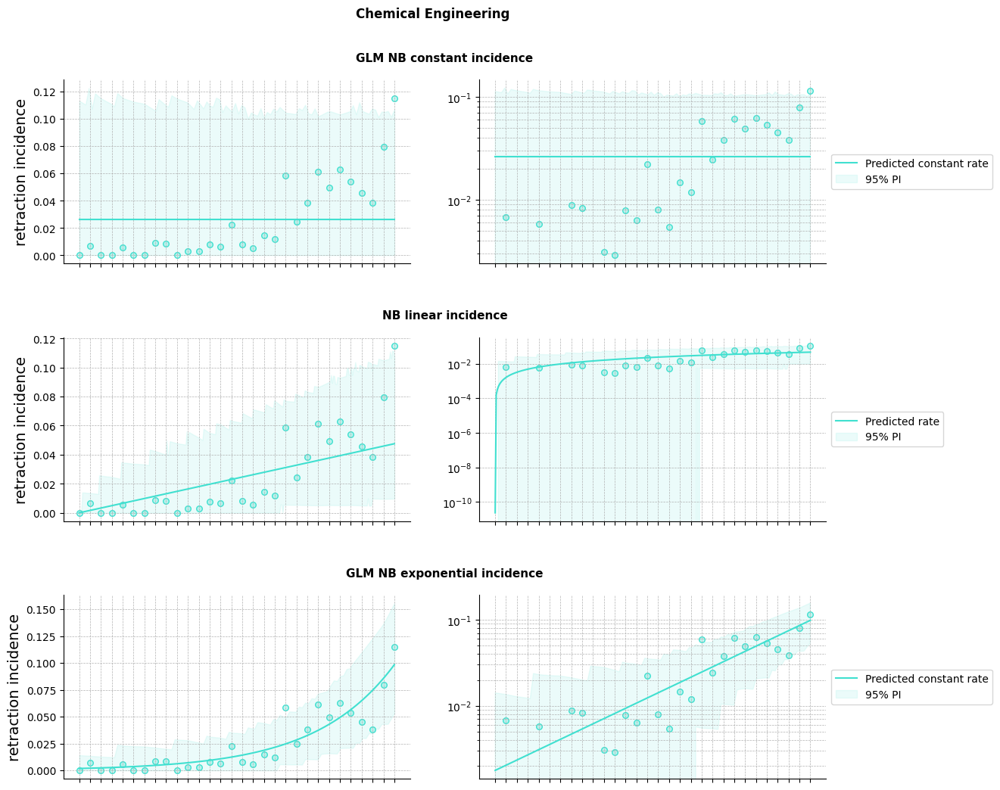

 46%|████▌     | 12/26 [00:11<00:13,  1.02it/s]

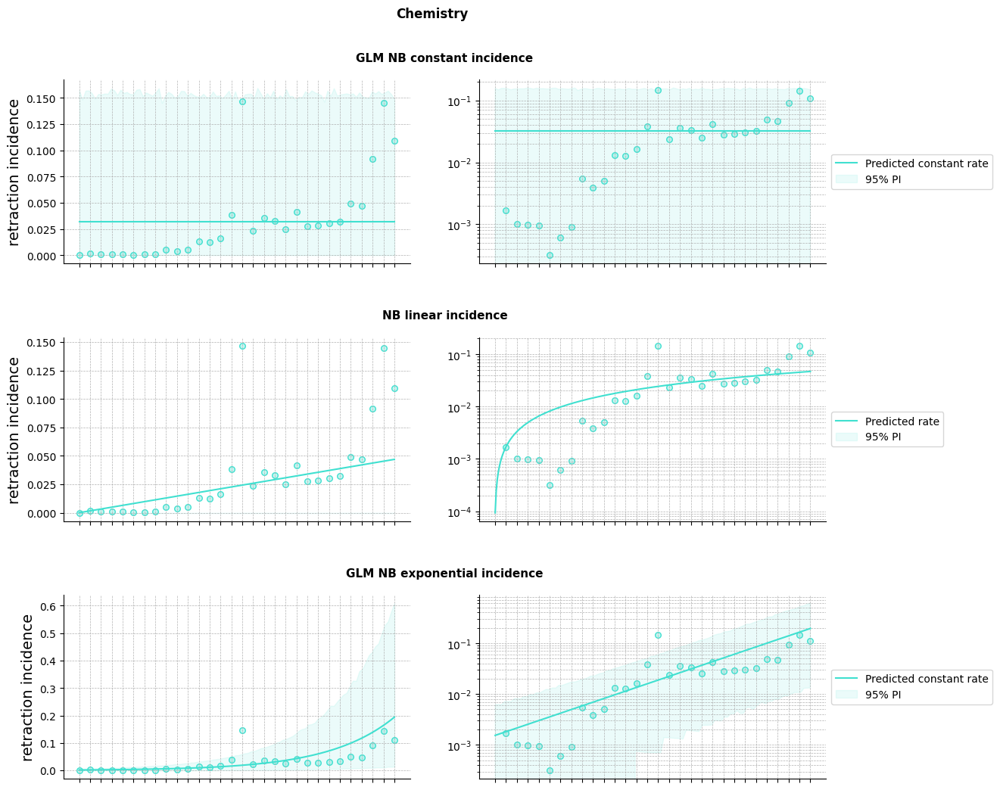

 50%|█████     | 13/26 [00:12<00:12,  1.07it/s]

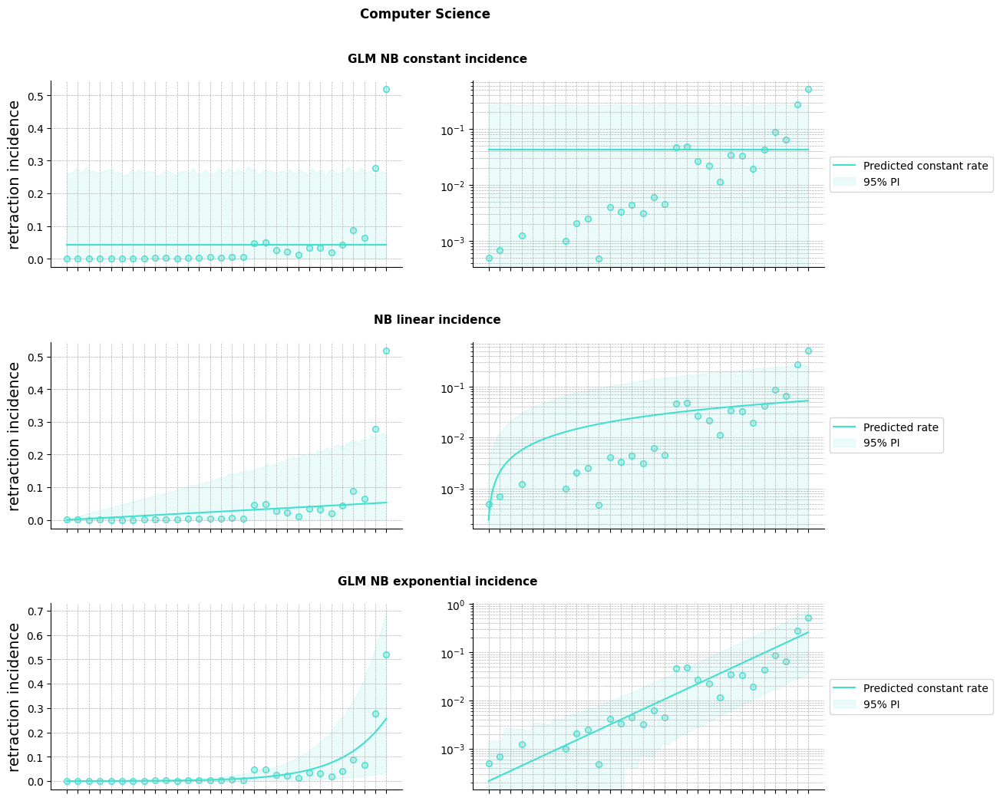

 54%|█████▍    | 14/26 [00:13<00:11,  1.02it/s]

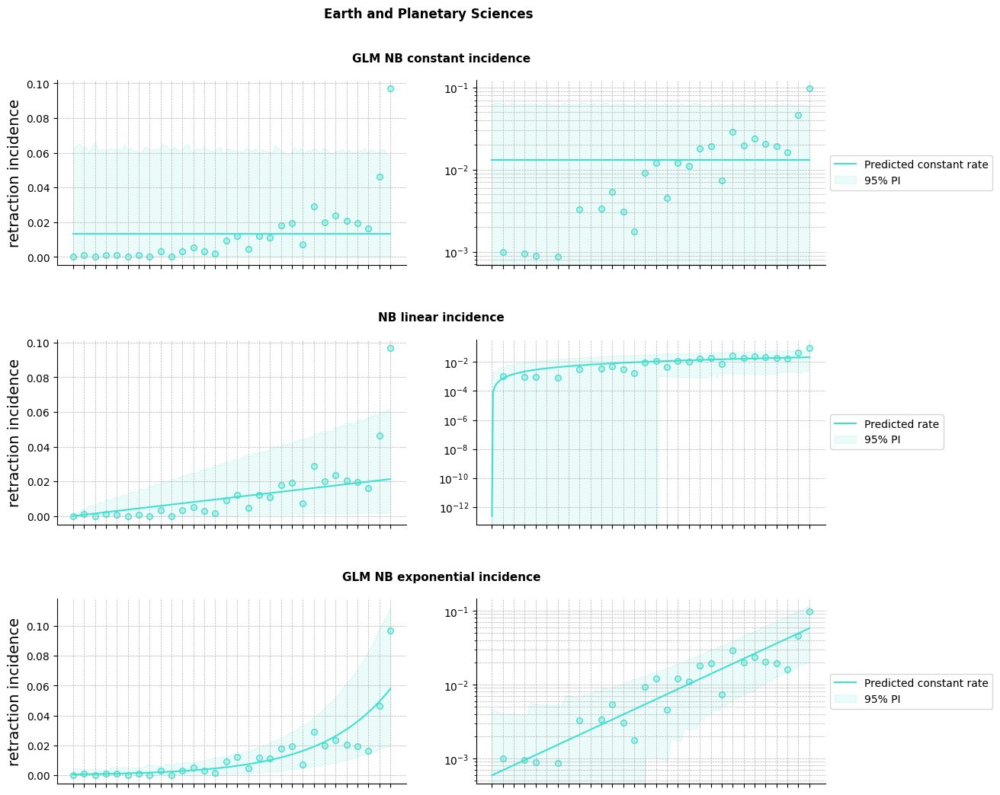

 58%|█████▊    | 15/26 [00:14<00:10,  1.01it/s]

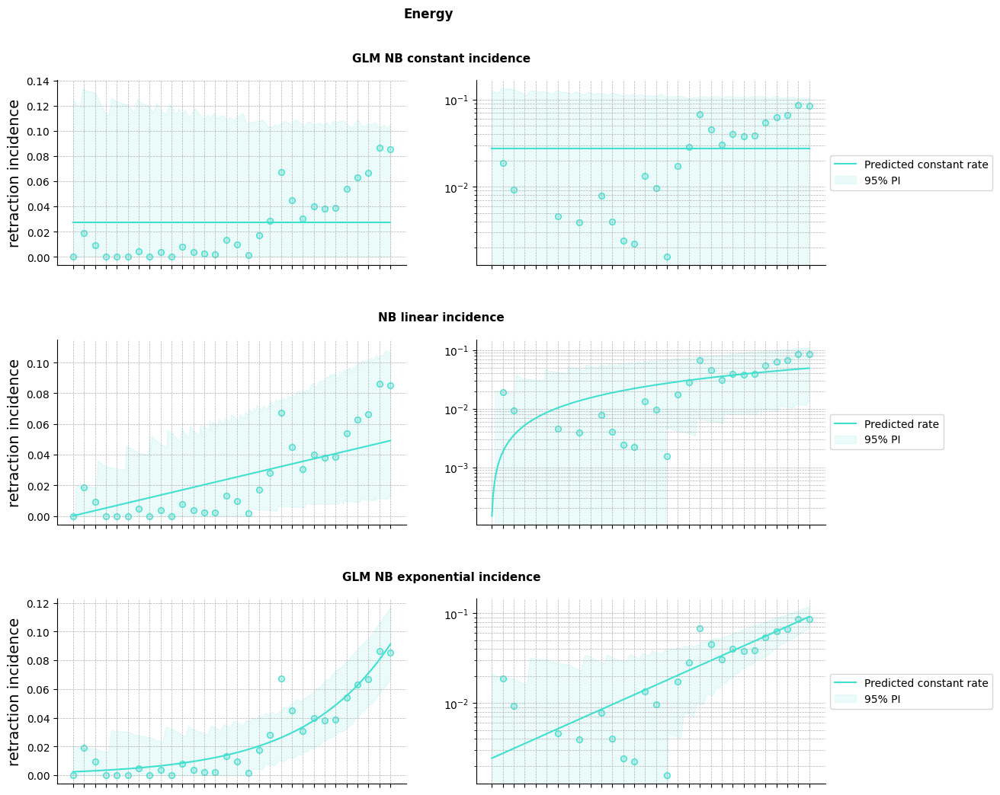

 62%|██████▏   | 16/26 [00:15<00:09,  1.02it/s]

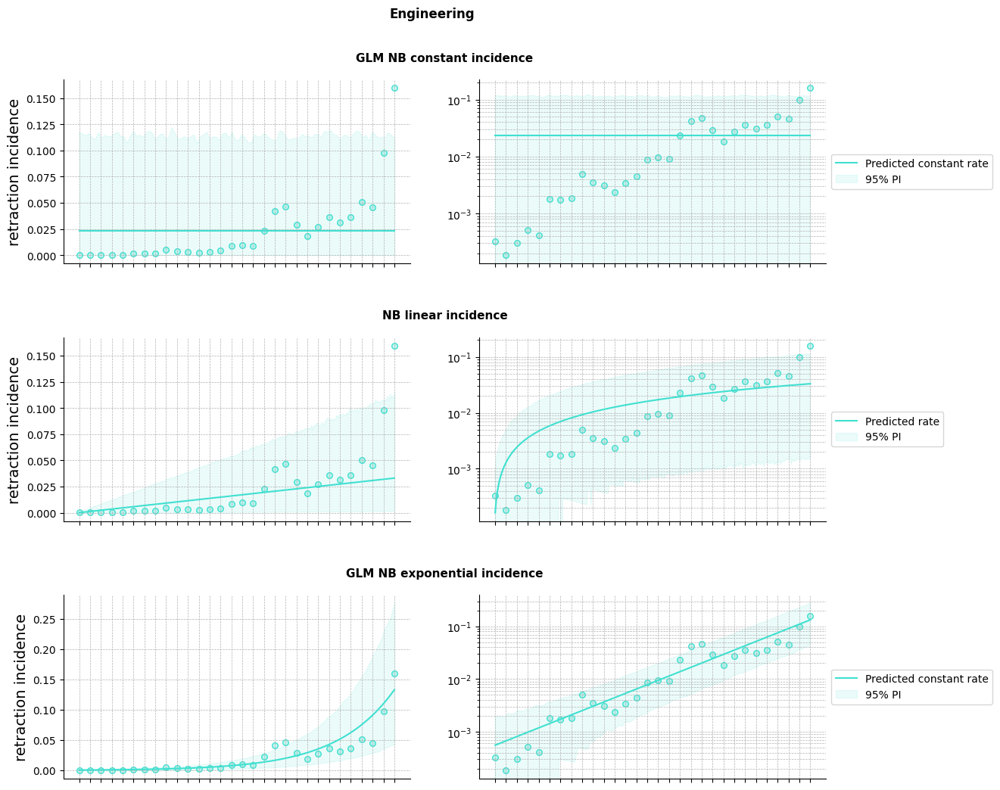

 65%|██████▌   | 17/26 [00:16<00:08,  1.01it/s]

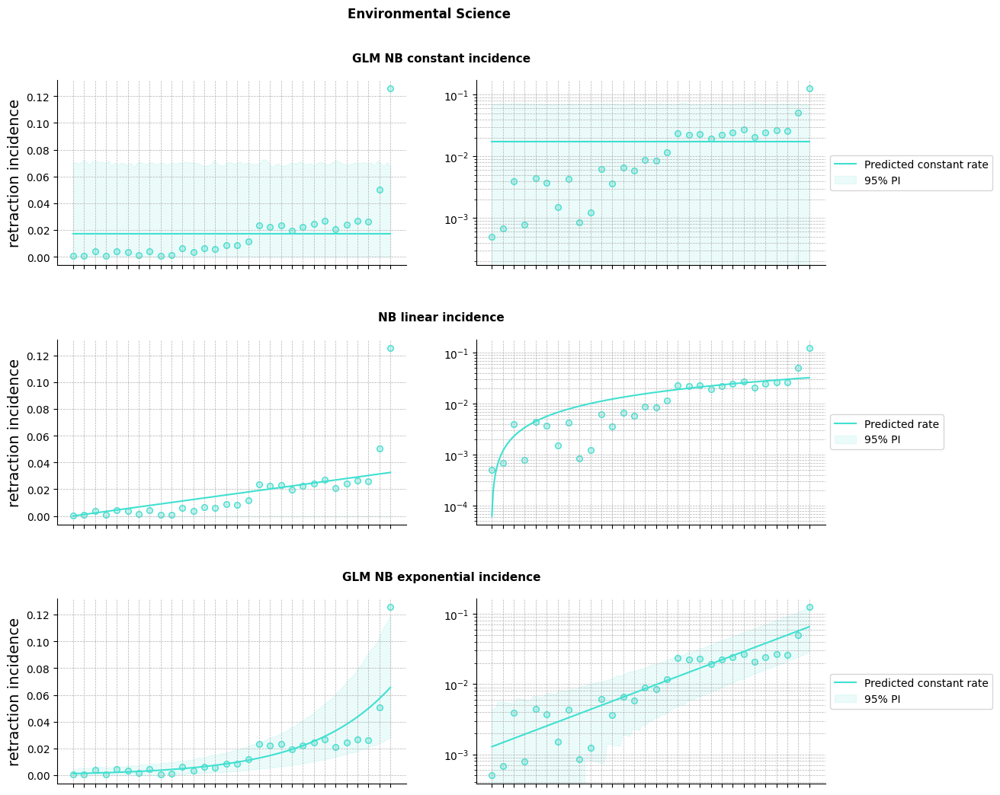

 69%|██████▉   | 18/26 [00:17<00:07,  1.04it/s]

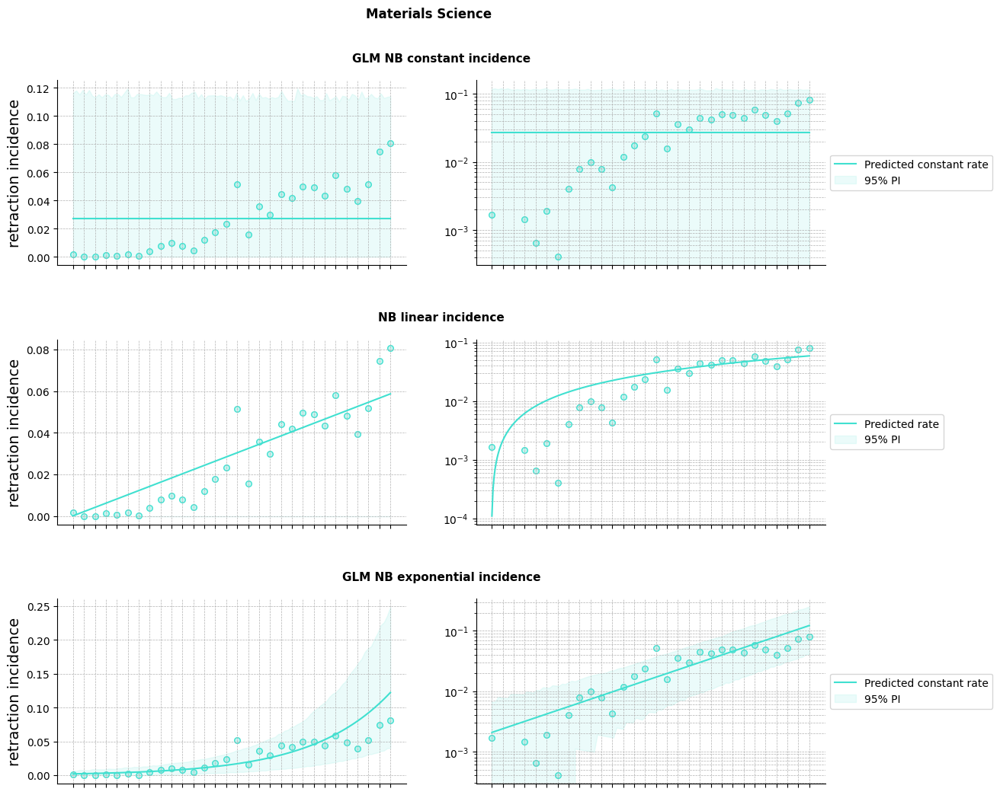

 73%|███████▎  | 19/26 [00:17<00:06,  1.08it/s]

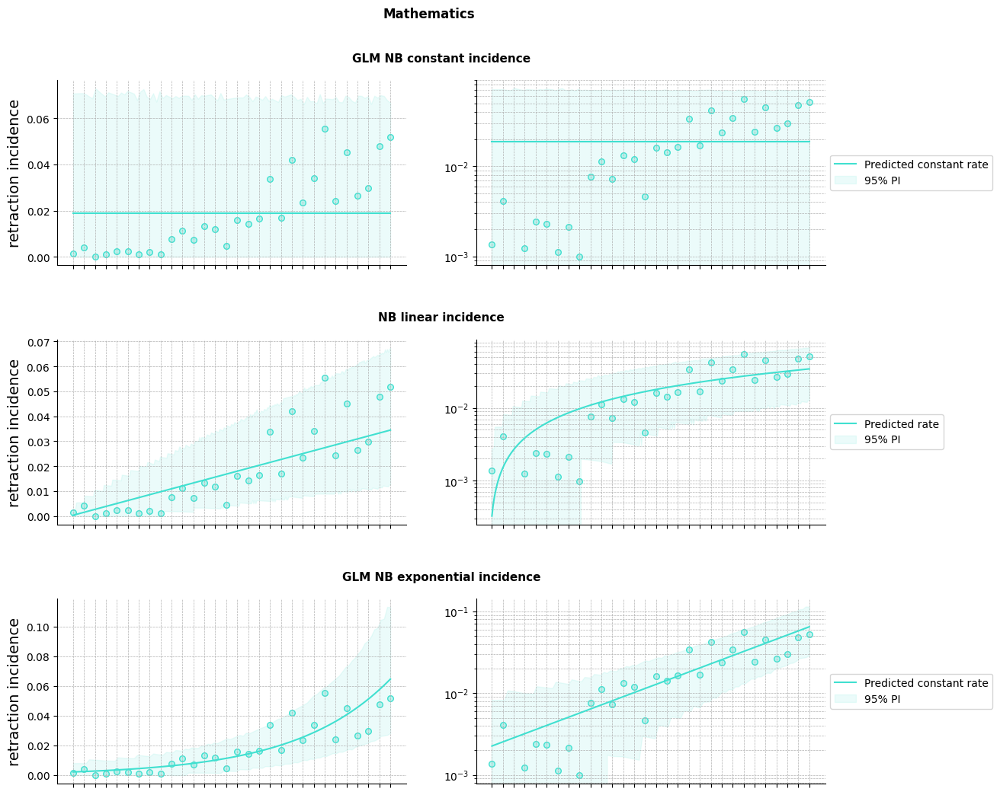

 77%|███████▋  | 20/26 [00:19<00:05,  1.05it/s]

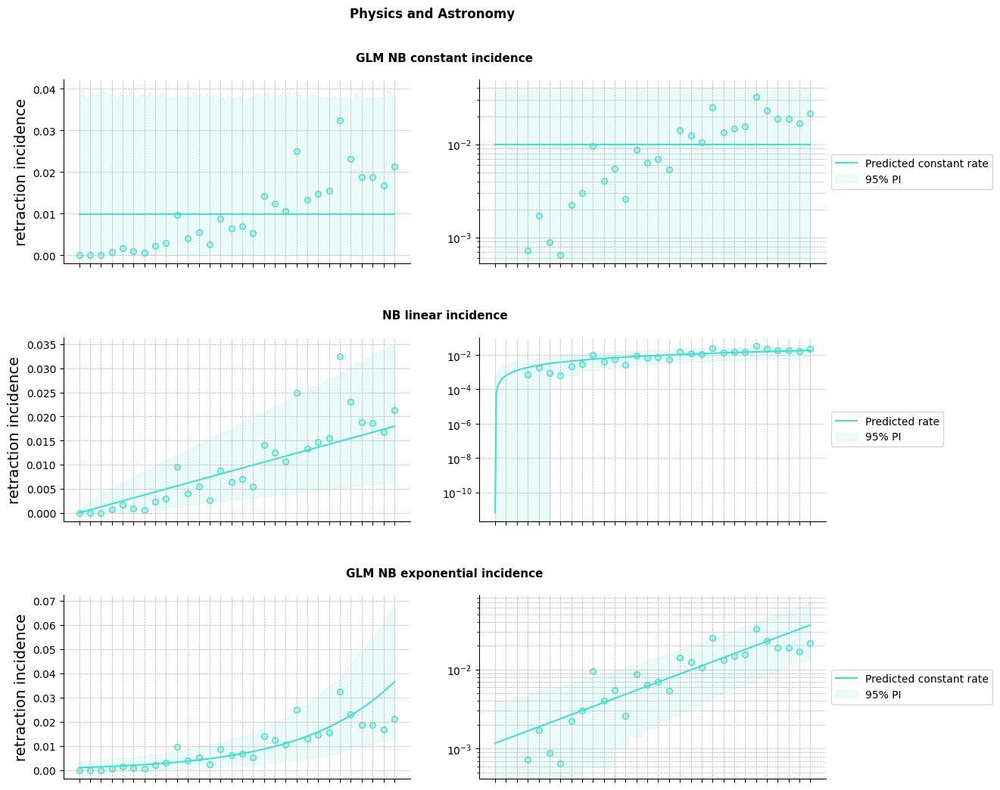

 81%|████████  | 21/26 [00:20<00:04,  1.03it/s]

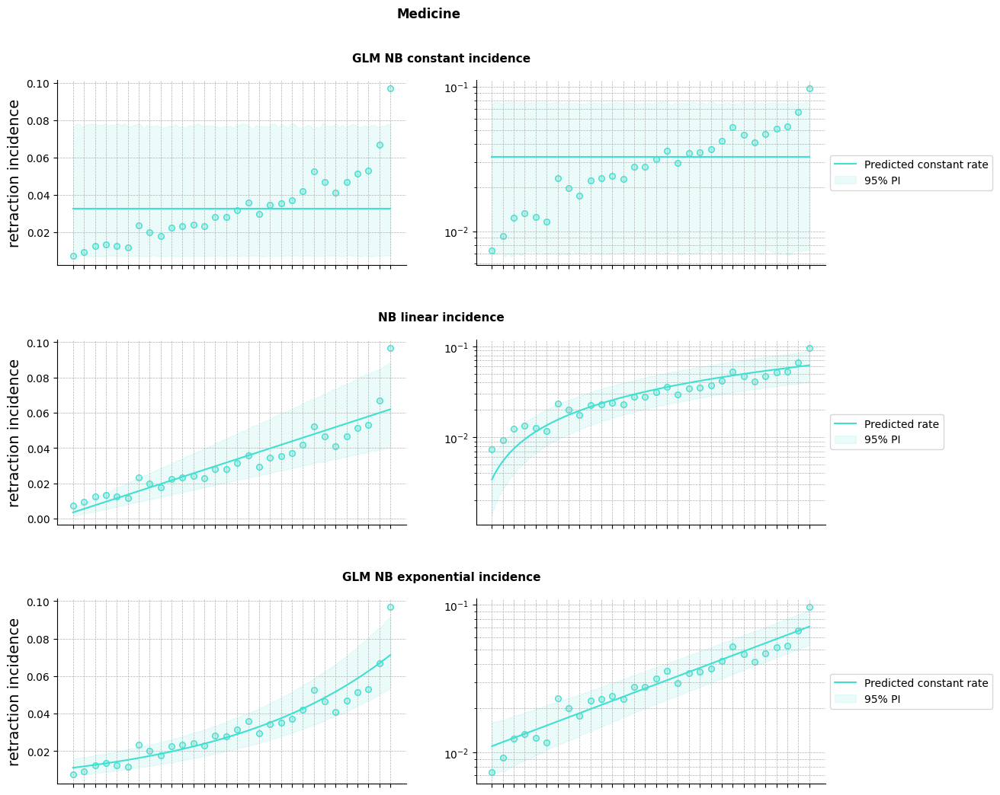

 85%|████████▍ | 22/26 [00:20<00:03,  1.07it/s]

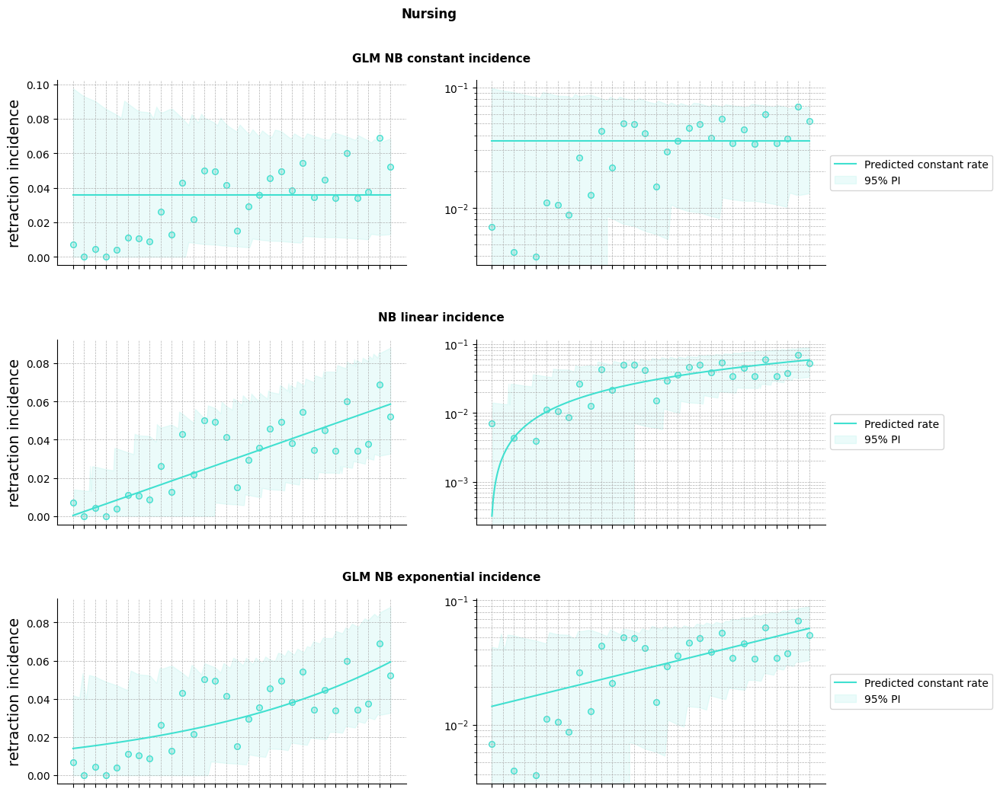

 88%|████████▊ | 23/26 [00:21<00:02,  1.04it/s]

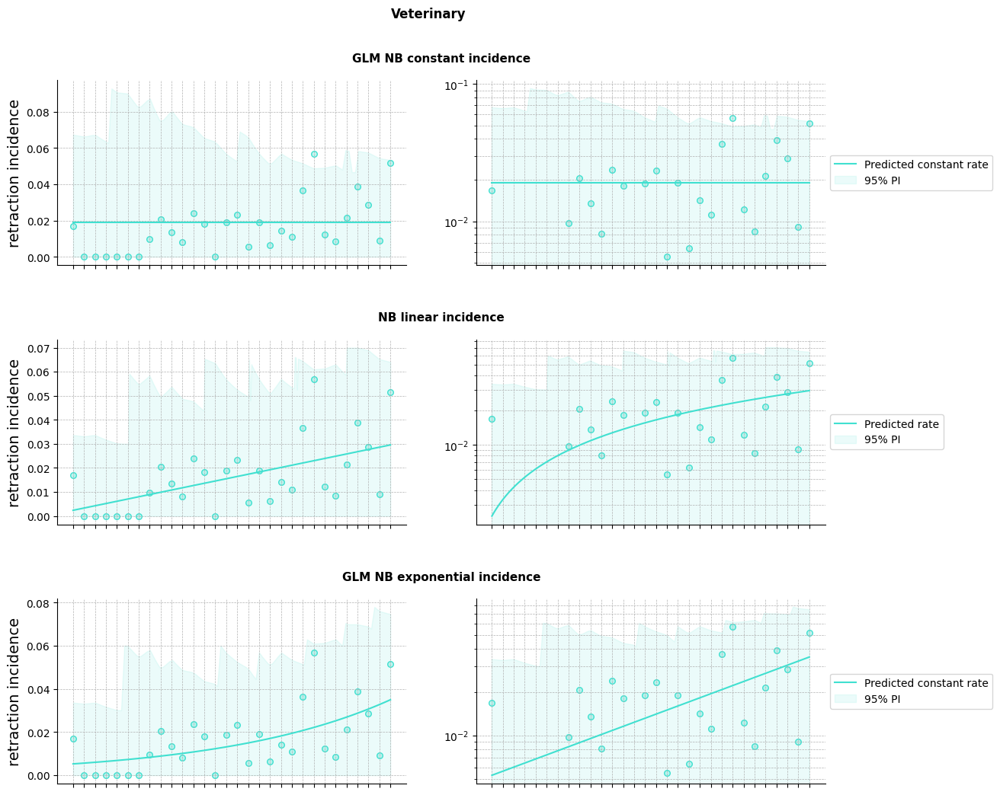

 92%|█████████▏| 24/26 [00:22<00:01,  1.07it/s]

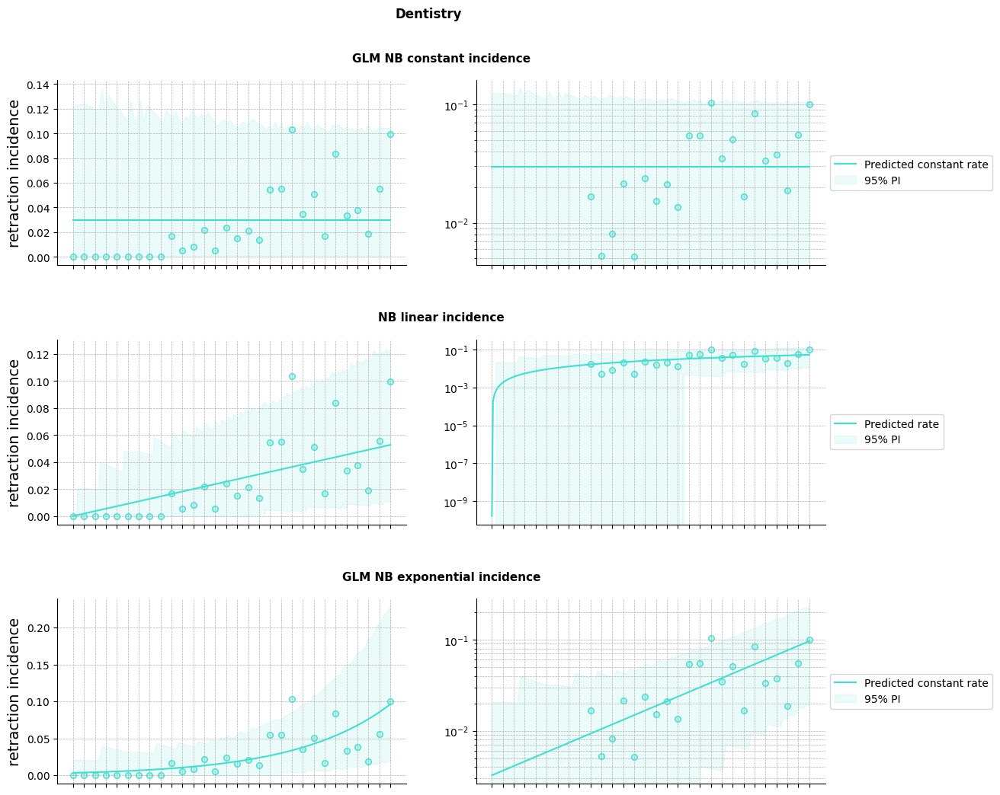

 96%|█████████▌| 25/26 [00:23<00:00,  1.05it/s]

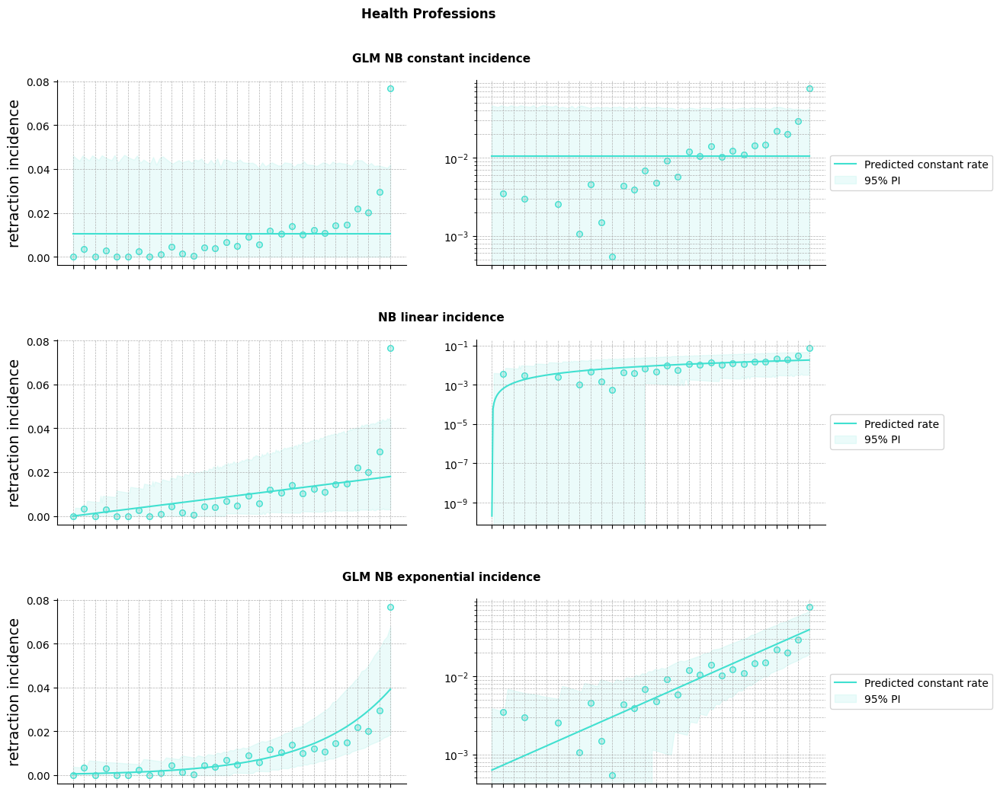

100%|██████████| 26/26 [00:24<00:00,  1.05it/s]


In [27]:
SCALE = 1e2
df = works_retracted_count_byfield.copy()
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_fields_df = pd.DataFrame()
for i in tqdm(range(n_fields)):
    df_i = df[df.field_id_scaled==i]
    results_df = try_all_fit(SCALE,df_i,start_year,end_year,True,output_folder,title,field_id_scaled_name_dict,i)
    results_fields_df = pd.concat([results_fields_df,results_df])

In [28]:
results_fields_df[results_fields_df.field_name=='Health Professions']

,field_id_scaled,field_name,start year,end year,model,dof,parameters,BIC,a,b,alpha,p value a,p value b,doubling time,doubling time upper,doubling time lower,ΔBIC,best_model,ΔBIC_weighted
0,25,Health Professions,1992,2021,GLM NB constant incidence,28,2,197.232912,-9.159526,NaN,1.157134,0.000000e+00,NaN,NaN,NaN,NaN,50.534447,0,1.063125e-11
0,25,Health Professions,1992,2021,GLM NB exponential incidence,27,3,146.698465,-11.976311,0.142492,0.086345,9.176865e-274,1.876062e-21,4.864469,6.20244,4.001317,0.000000,1,1.000000e+00


In [29]:
results_fields_df[results_fields_df.best_model==1]

,field_id_scaled,field_name,start year,end year,model,dof,parameters,BIC,a,b,alpha,p value a,p value b,doubling time,doubling time upper,doubling time lower,ΔBIC,best_model,ΔBIC_weighted
0,0,Agricultural and Biological Sciences,1992,2021,GLM NB exponential incidence,27,3,224.471221,-10.815831,0.112413,9.700447e-02,0.000000e+00,3.103278e-29,6.166103,7.545447,5.213119,0.0,1,1.000000
0,1,"Biochemistry, Genetics and Molecular Biology",1992,2021,GLM NB exponential incidence,27,3,331.933045,-9.483966,0.137541,1.021456e-01,0.000000e+00,2.699518e-69,5.039569,5.704843,4.513253,0.0,1,1.000000
0,2,Immunology and Microbiology,1992,2021,GLM NB exponential incidence,27,3,202.019083,-8.463744,0.059446,1.419258e-02,0.000000e+00,2.595901e-20,11.660106,14.990997,9.540316,0.0,1,1.000000
0,3,Neuroscience,1992,2021,GLM NB exponential incidence,27,3,207.634967,-9.495637,0.095525,4.776360e-02,0.000000e+00,7.583380e-35,7.256220,8.706989,6.219859,0.0,1,1.000000
0,4,"Pharmacology, Toxicology and Pharmaceutics",1992,2021,GLM NB exponential incidence,27,3,117.983013,-10.232625,0.127849,7.120381e-03,8.627968e-248,2.260604e-23,5.421620,6.828142,4.495580,0.0,1,1.000000
0,5,Arts and Humanities,1992,2021,GLM NB exponential incidence,27,3,151.997870,-12.335202,0.110359,1.237045e-01,2.055313e-320,8.678849e-13,6.280852,8.808678,4.880341,0.0,1,1.000000
0,6,"Business, Management and Accounting",1992,2021,GLM NB exponential incidence,27,3,223.547711,-11.233496,0.154431,8.477414e-01,1.833380e-104,1.488546e-07,4.488388,7.364405,3.227826,0.0,1,0.999984
0,7,Decision Sciences,1992,2021,GLM NB exponential incidence,27,3,148.957458,-11.440730,0.163478,3.884698e-01,2.845470e-112,1.488180e-11,4.239991,6.092096,3.251483,0.0,1,1.000000
0,8,"Economics, Econometrics and Finance",1992,2021,GLM NB exponential incidence,27,3,174.999707,-11.949641,0.151304,4.879185e-01,2.036995e-129,6.100094e-09,4.581152,7.079650,3.386140,0.0,1,0.999999
0,9,Psychology,1992,2021,GLM NB exponential incidence,27,3,205.705855,-10.144697,0.087907,1.334323e-01,0.000000e+00,1.062814e-14,7.885049,10.733589,6.231341,0.0,1,0.996458


In [30]:
df = results_fields_df
df = df[['field_name','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['field_name', 'model_order']).drop(columns='model_order')
df.head()

,field_name,model,ΔBIC,ΔBIC_weighted
0,Agricultural and Biological Sciences,constant,55.200671,1.031161e-12
0,Agricultural and Biological Sciences,exponential,0.000000,1.000000e+00
0,Arts and Humanities,constant,33.563770,5.148965e-08
0,Arts and Humanities,linear,NaN,NaN
0,Arts and Humanities,exponential,0.000000,9.999999e-01


In [31]:
df = results_fields_df[results_fields_df.best_model==1][['field_name','alpha','b','p value b','doubling time','doubling time lower','doubling time upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'})
df

,field_name,alpha,g,p-value,doubling time,doubling time lower,doubling time upper
0,Agricultural and Biological Sciences,9.700447e-02,0.112413,3.103278e-29,6.166103,5.213119,7.545447
0,"Biochemistry, Genetics and Molecular Biology",1.021456e-01,0.137541,2.699518e-69,5.039569,4.513253,5.704843
0,Immunology and Microbiology,1.419258e-02,0.059446,2.595901e-20,11.660106,9.540316,14.990997
0,Neuroscience,4.776360e-02,0.095525,7.583380e-35,7.256220,6.219859,8.706989
0,"Pharmacology, Toxicology and Pharmaceutics",7.120381e-03,0.127849,2.260604e-23,5.421620,4.495580,6.828142
0,Arts and Humanities,1.237045e-01,0.110359,8.678849e-13,6.280852,4.880341,8.808678
0,"Business, Management and Accounting",8.477414e-01,0.154431,1.488546e-07,4.488388,3.227826,7.364405
0,Decision Sciences,3.884698e-01,0.163478,1.488180e-11,4.239991,3.251483,6.092096
0,"Economics, Econometrics and Finance",4.879185e-01,0.151304,6.100094e-09,4.581152,3.386140,7.079650
0,Psychology,1.334323e-01,0.087907,1.062814e-14,7.885049,6.231341,10.733589


## Countries

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_retracted_count_bycountry`
  AS 
  WITH
  -- Step 1: Deduplicate and prepare core authorship data
  deduped_authorships AS (
    SELECT DISTINCT
      work_id,
      is_retracted,
      publication_year,
      author_id,
      country_code
    FROM project_name.dataset_name.works_authorships
    WHERE country_code IS NOT NULL
      AND publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  ),

  -- Step 2: Count unique authors per work
  unique_authors_per_work AS (
    SELECT
      work_id,
      COUNT(DISTINCT author_id) AS num_authors
    FROM deduped_authorships
    GROUP BY work_id
  ),

  -- Step 3: Count unique countries per author per work
  unique_countries_per_author_work AS (
    SELECT 
      work_id,
      author_id,
      COUNT(DISTINCT country_code) AS num_countries_per_author
    FROM deduped_authorships
    GROUP BY work_id, author_id
  ),

  -- Step 4: Compute weights
  author_country_weights AS (
    SELECT
      d.work_id,
      d.is_retracted,
      d.publication_year,
      d.author_id,
      d.country_code,
      1.0 / (uapw.num_authors * uipaw.num_countries_per_author) AS author_country_weight
    FROM deduped_authorships d
    JOIN unique_authors_per_work uapw
      ON d.work_id = uapw.work_id
    JOIN unique_countries_per_author_work uipaw
      ON d.work_id = uipaw.work_id AND d.author_id = uipaw.author_id
  ),

  -- Step 5: Aggregate total and retracted weights
  final_country_year_weights AS (
    SELECT
      publication_year,
      country_code,
      SUM(author_country_weight) AS total_weight,
      SUM(CASE WHEN is_retracted = 1 THEN author_country_weight ELSE 0 END) AS retracted_weight
    FROM author_country_weights
    GROUP BY publication_year, country_code
  )

  -- Final output
  SELECT *
  FROM final_country_year_weights
  ORDER BY publication_year, country_code;
"""
##output info
new_table_name = "works_retracted_count_bycountry"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Retracted/Plots/plots_countries'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_retracted_count_bycountry = pd.read_csv(f'./Retracted/Data/works_retracted_count_bycountry.csv.gz', compression='gzip', keep_default_na=False).rename(columns={'publication_year':'year'})
works_retracted_count_bycountry['year'] = works_retracted_count_bycountry['year'].str[:4].astype(int)
works_retracted_count_bycountry = works_retracted_count_bycountry.rename(columns={'total_weight':'total','retracted_weight':'retracted'})
works_retracted_count_bycountry = works_retracted_count_bycountry.dropna()
def country_code_to_name(code):
    try:
        country = pycountry.countries.get(alpha_2=code.upper())
        return country.name if country else None
    except:
        return None
works_retracted_count_bycountry['country_name'] = works_retracted_count_bycountry['country_code'].apply(country_code_to_name)
country_code_name_dict = works_retracted_count_bycountry[['country_code','country_name']].drop_duplicates().set_index('country_code').to_dict()['country_name']
country_code_name_dict['XK'] = 'Kosovo'
works_retracted_count_bycountry['country_name'] = works_retracted_count_bycountry['country_code'].map(country_code_name_dict)
works_retracted_count_bycountry['country_name'] = (works_retracted_count_bycountry['country_name'].replace({'Iran, Islamic Republic of': 'Islamic Republic of Iran','Korea, Republic of': 'Republic of Korea'}))
print(f'{len(set(works_retracted_count_bycountry.country_code))} countries')

227 countries


In [34]:
## retracted map 2021
works_retracted_count_bycountry_2021 = works_retracted_count_bycountry[works_retracted_count_bycountry.year==2021]
works_retracted_count_bycountry_2021.head()

,Unnamed: 0,year,country_code,total,retracted,country_name
6330,8725,2021,AD,13.703019,0.000000,Andorra
6331,8726,2021,AE,5601.582824,10.785714,United Arab Emirates
6332,8727,2021,AF,478.816578,0.783333,Afghanistan
6333,8728,2021,AG,103.433618,0.000000,Antigua and Barbuda
6334,8729,2021,AL,832.775387,1.500000,Albania


In [35]:
## total publications map 1992, 2000, 2010, 2021
works_retracted_count_bycountry[works_retracted_count_bycountry.year.isin({1992,2000,2010,2021})].head()

,Unnamed: 0,year,country_code,total,retracted,country_name
0,2395,1992,AE,86.556519,0.0,United Arab Emirates
1,2396,1992,AF,2.166667,0.0,Afghanistan
2,2397,1992,AG,3.000000,0.0,Antigua and Barbuda
3,2398,1992,AL,26.671429,0.0,Albania
4,2399,1992,AM,131.097438,0.0,Armenia


In [36]:
## countries coverage

# --- Define years of interest ---
years_of_interest = [1992, 1997, 2002, 2007, 2012, 2017, 2021]


def countries_coverage(col):
    df_year_country = (
        works_retracted_count_bycountry[works_retracted_count_bycountry['year'].isin(years_of_interest)]
        .groupby(['year', 'country_code'], as_index=False)[col]
        .sum()
    )
    # Function: count number of countries to reach 80%
    def count_countries_covering_X(group, l=0.8):
        group = group.sort_values(col, ascending=False)
        group['cum_share'] = group[col].cumsum() / group[col].sum()
        n_countries = (group['cum_share'] <= l).sum()
        return pd.Series({'n_countries': n_countries})
    # Compute per-year metric
    df_50 = (
        df_year_country.groupby('year')
        .apply(lambda x: count_countries_covering_X(x, 0.5))
        .reset_index()
        .sort_values('year')
    )
    df_50.insert(0,'coverage',50)
    df_80 = (
        df_year_country.groupby('year')
        .apply(lambda x: count_countries_covering_X(x, 0.8))
        .reset_index()
        .sort_values('year')
    )
    df_80.insert(0,'coverage',80)
    df_90 = (
        df_year_country.groupby('year')
        .apply(lambda x: count_countries_covering_X(x, 0.9))
        .reset_index()
        .sort_values('year')
    )   
    df_90.insert(0,'coverage',90)

    return pd.concat([df_50,df_80,df_90]).sort_values(by=['year','coverage'])

In [37]:
df_coverage_retracted = countries_coverage('retracted')
df_coverage_total = countries_coverage('total')
display(df_coverage_retracted)
display(df_coverage_total)

,coverage,year,n_countries
0,50,1992,2
0,80,1992,4
0,90,1992,6
1,50,1997,1
1,80,1997,6
1,90,1997,11
2,50,2002,2
2,80,2002,7
2,90,2002,12
3,50,2007,1


,coverage,year,n_countries
0,50,1992,2
0,80,1992,10
0,90,1992,19
1,50,1997,2
1,80,1997,12
1,90,1997,22
2,50,2002,3
2,80,2002,14
2,90,2002,24
3,50,2007,3


In [38]:
#Correlation
from scipy.stats import pearsonr
df_corr = works_retracted_count_bycountry_2021[['country_code', 'total', 'retracted']].copy()
df_corr = df_corr[(df_corr['total'] > 0.0012) & (df_corr['retracted'] > 0.0012)]
correlation, p_value = pearsonr(np.log10(df_corr['total']), np.log10(df_corr['retracted']))

x = np.log10(df_corr['total'])
y = np.log10(df_corr['retracted'])
n = len(x)

m, b = np.polyfit(x, y, 1)
y_pred = m * x + b

resid = y - y_pred
s_err = np.sqrt(np.sum(resid**2) / (n - 2))

alpha = 0.10
t_val = stats.t.ppf(1 - alpha/2, df=n - 2)

x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = m * x_fit + b

s_xx = np.sum((x - np.mean(x))**2)
se_fit = s_err * np.sqrt(1/n + (x_fit - np.mean(x))**2 / s_xx)

ci_upper = y_fit + t_val * se_fit
ci_lower = y_fit - t_val * se_fit

#R squared
ss_total = np.sum((y - np.mean(y))**2)
ss_residual = np.sum(resid**2)
r_squared = 1 - (ss_residual / ss_total)

print(f"P-value: {p_value:.3e}")
print(f"R^2: {r_squared:.2f}")

P-value: 1.249e-24
R^2: 0.59


In [39]:
## country selection: 
col = 'total'
df_year_country = (
    works_retracted_count_bycountry[works_retracted_count_bycountry['year']==2021]
    .groupby(['year', 'country_code'], as_index=False)[col]
    .sum()
)
def countries_covering_X(group, l=0.8):
    group = group.sort_values(col, ascending=False)
    group['cum_share'] = group[col].cumsum() / group[col].sum()
    selected = group[group['cum_share'] <= l]['country_code'].tolist()
    return pd.Series({
        'n_countries': len(selected),
        'countries': selected
    })
df_80 = (
    df_year_country.groupby('year')
    .apply(lambda x: countries_covering_X(x, 0.8))
    .reset_index()
    .sort_values('year')
)
country_selected_set = df_80.loc[0].countries

In [40]:
works_retracted_count_bycountry = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(country_selected_set)].reset_index(drop=True)
print(f'{len(set(works_retracted_count_bycountry.country_code))} countries')

21 countries


  0%|          | 0/21 [00:00<?, ?it/s]

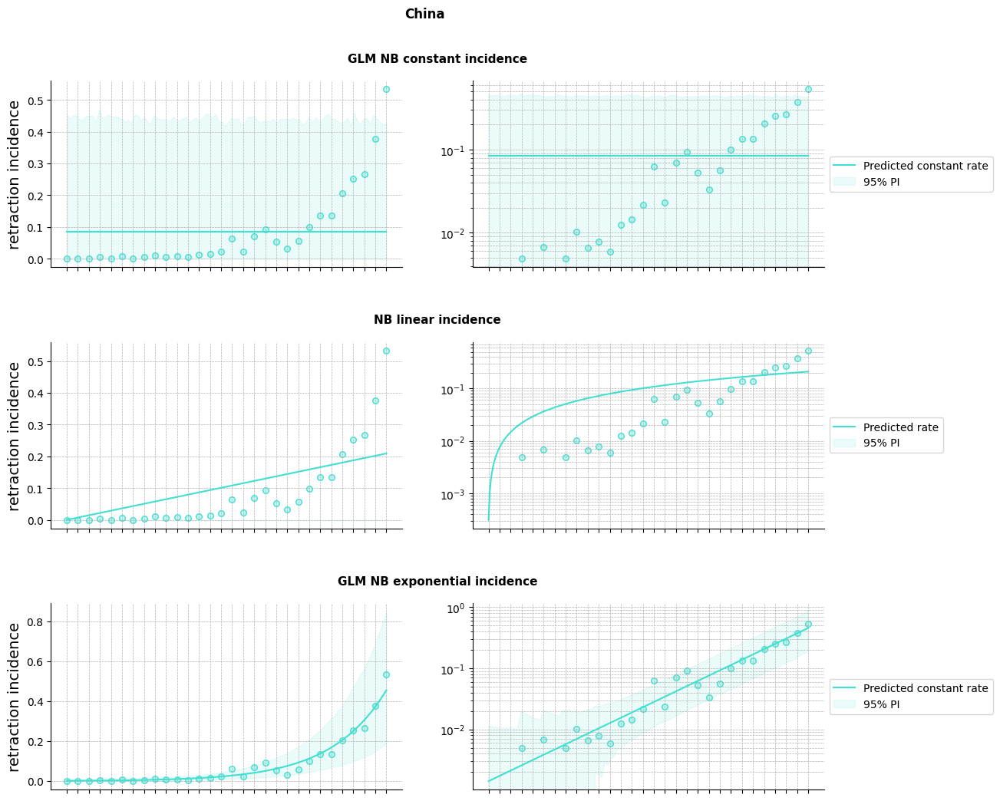

  5%|▍         | 1/21 [00:00<00:16,  1.20it/s]

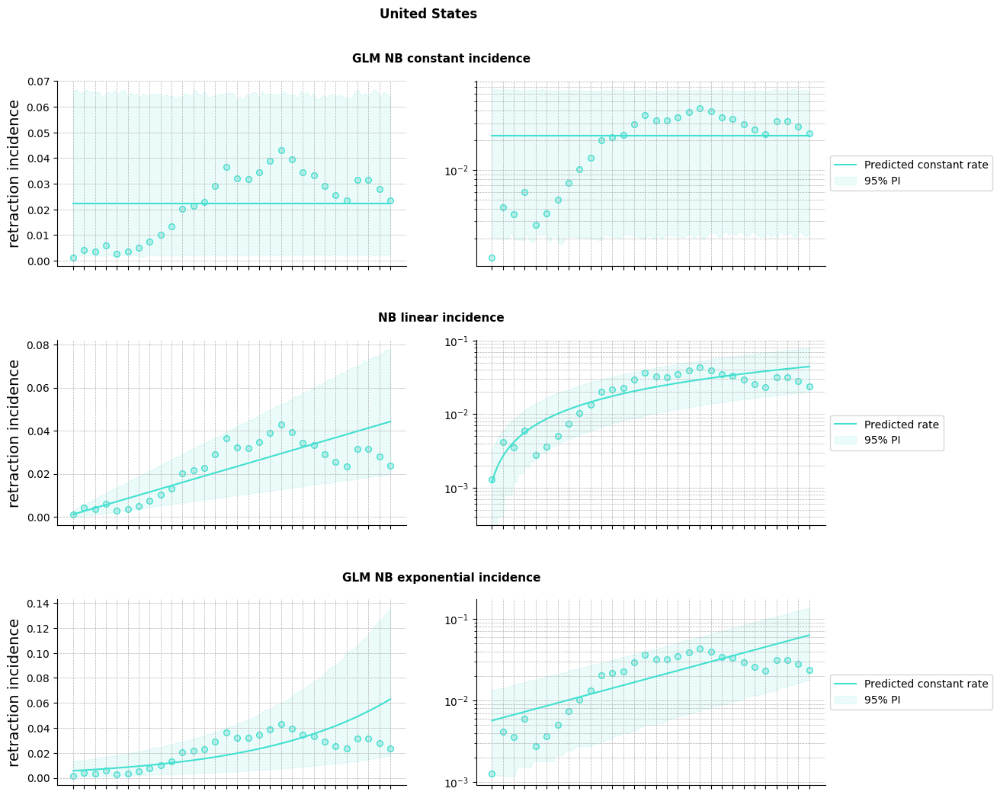

 10%|▉         | 2/21 [00:01<00:17,  1.10it/s]

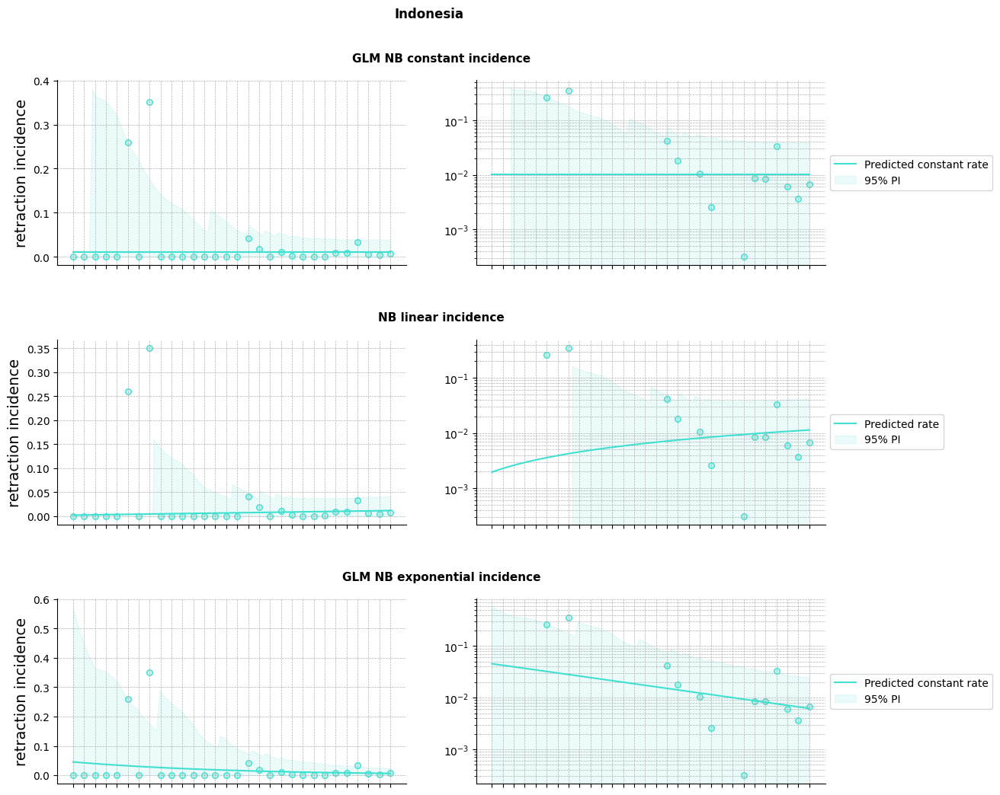

 14%|█▍        | 3/21 [00:02<00:16,  1.09it/s]

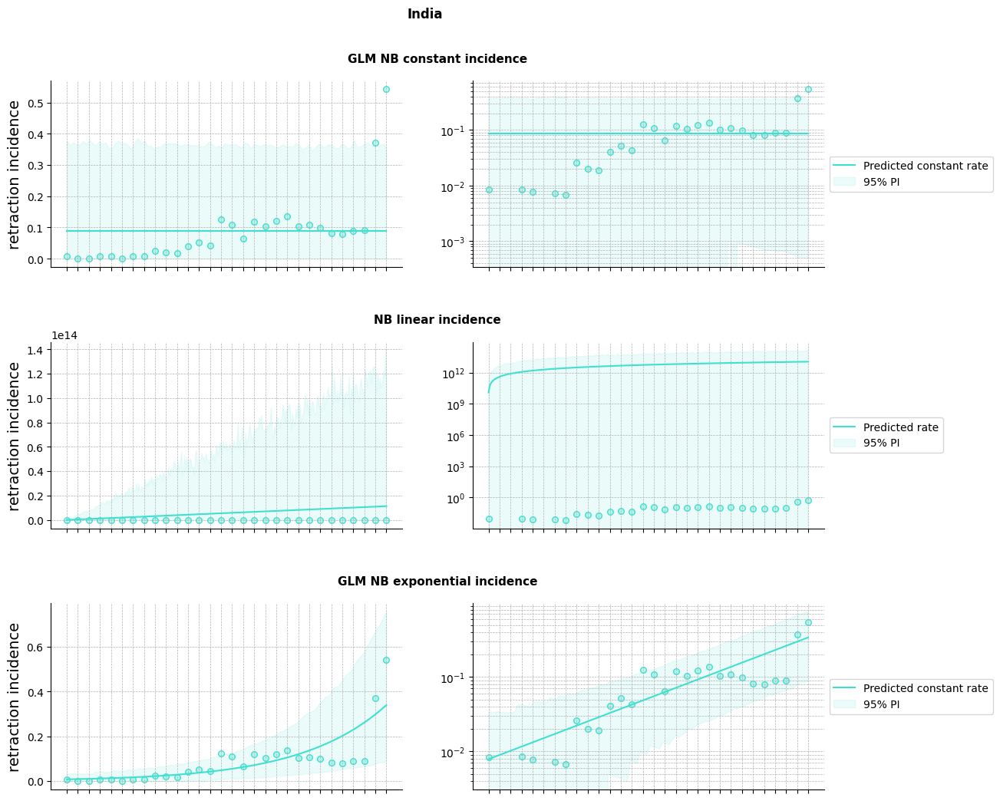

 19%|█▉        | 4/21 [00:03<00:16,  1.05it/s]

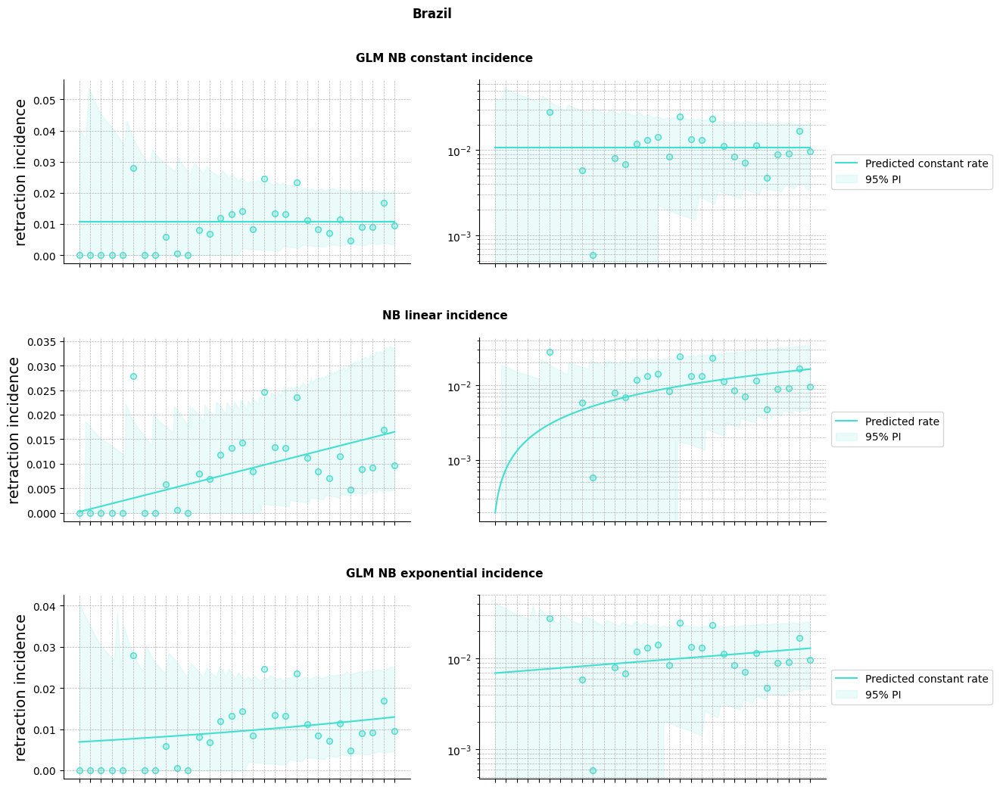

 24%|██▍       | 5/21 [00:04<00:15,  1.04it/s]

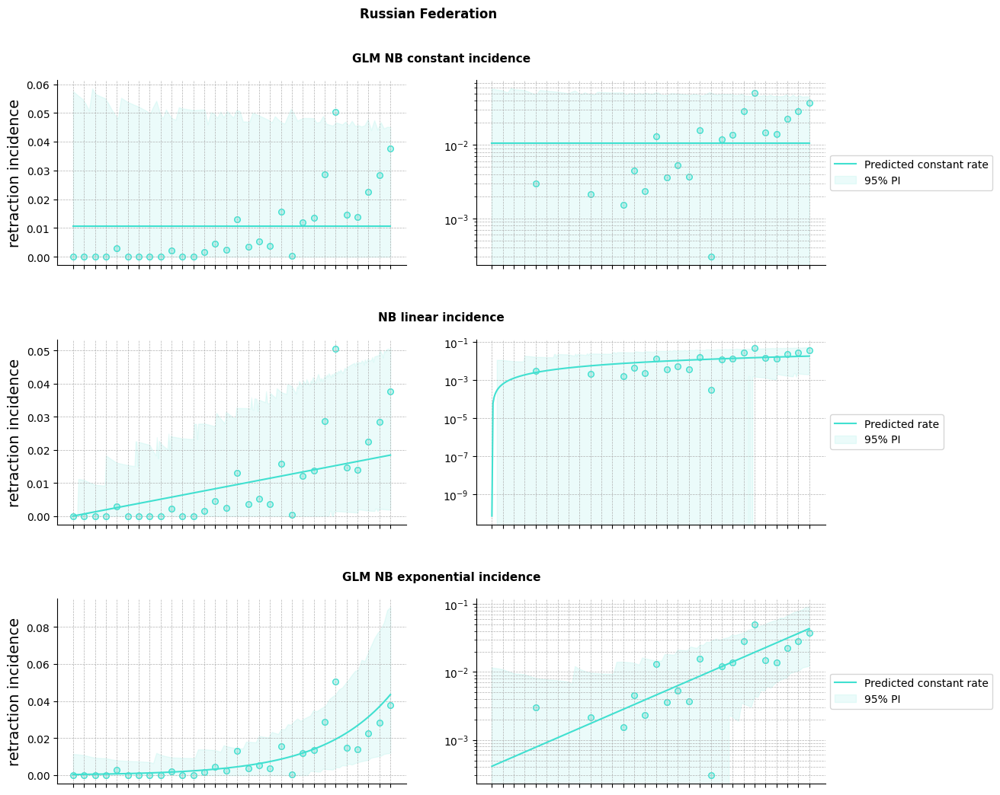

 29%|██▊       | 6/21 [00:05<00:14,  1.05it/s]

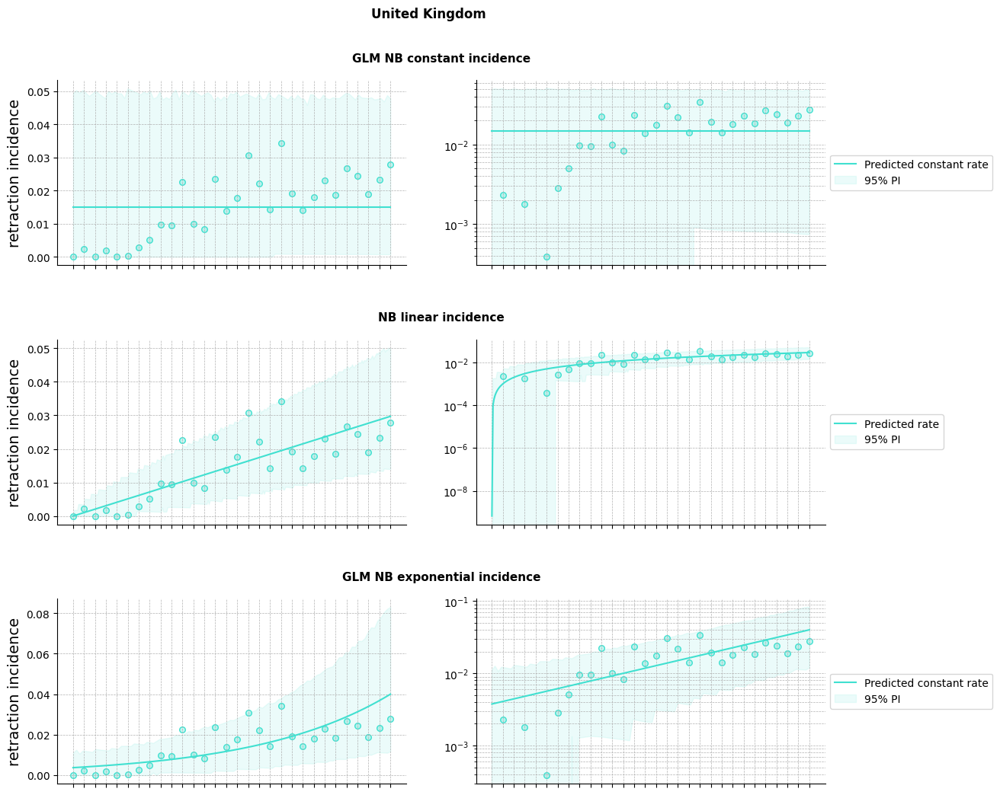

 33%|███▎      | 7/21 [00:06<00:13,  1.03it/s]

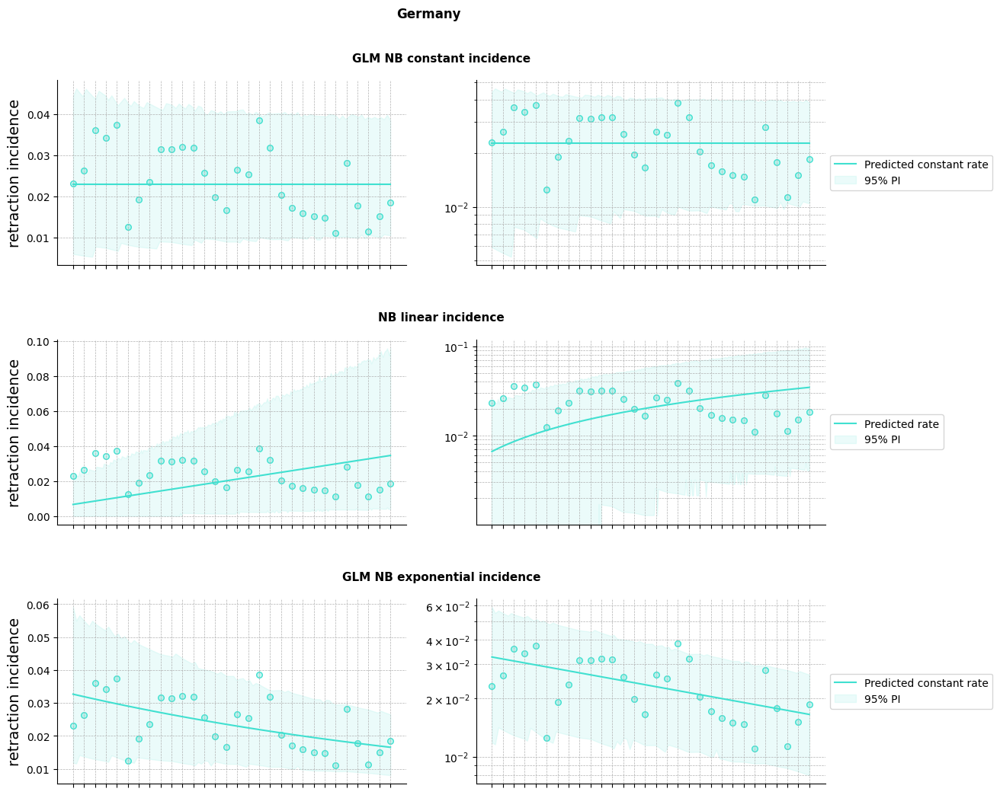

 38%|███▊      | 8/21 [00:07<00:12,  1.03it/s]

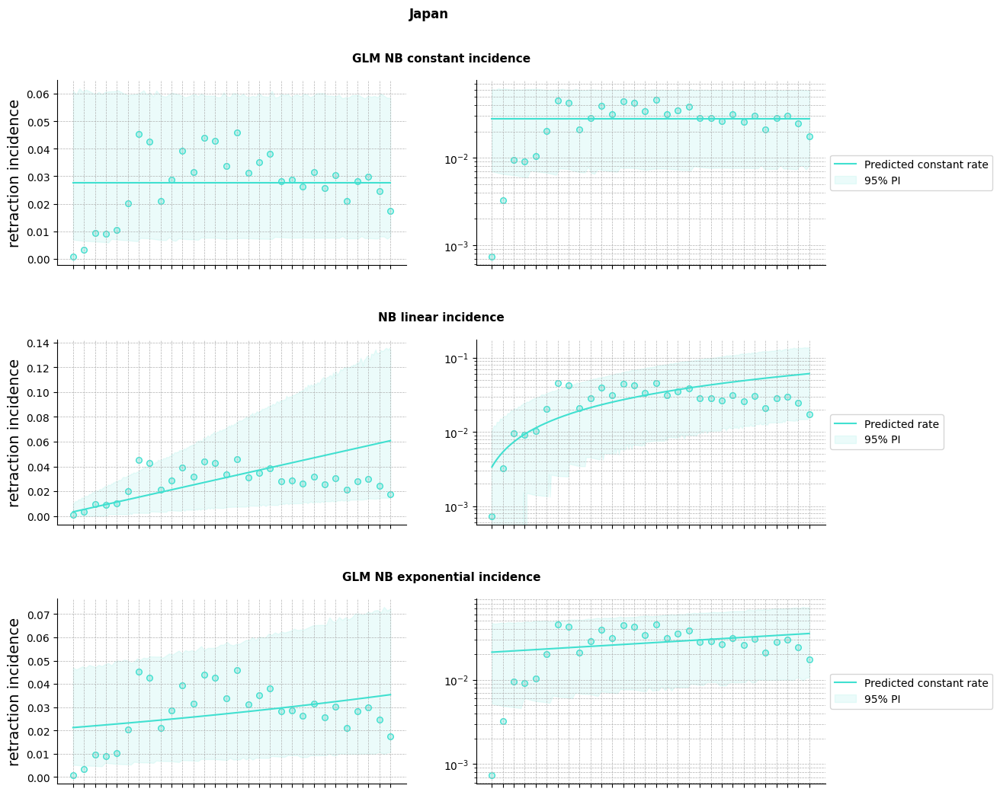

 43%|████▎     | 9/21 [00:08<00:11,  1.02it/s]

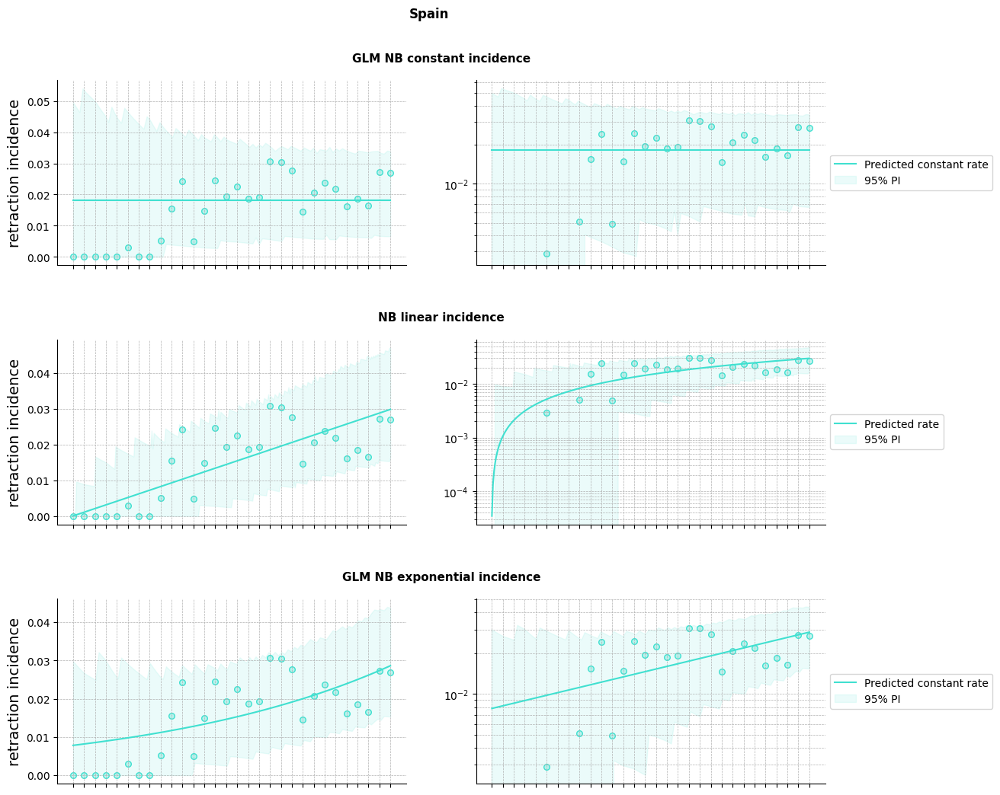

 48%|████▊     | 10/21 [00:09<00:10,  1.01it/s]

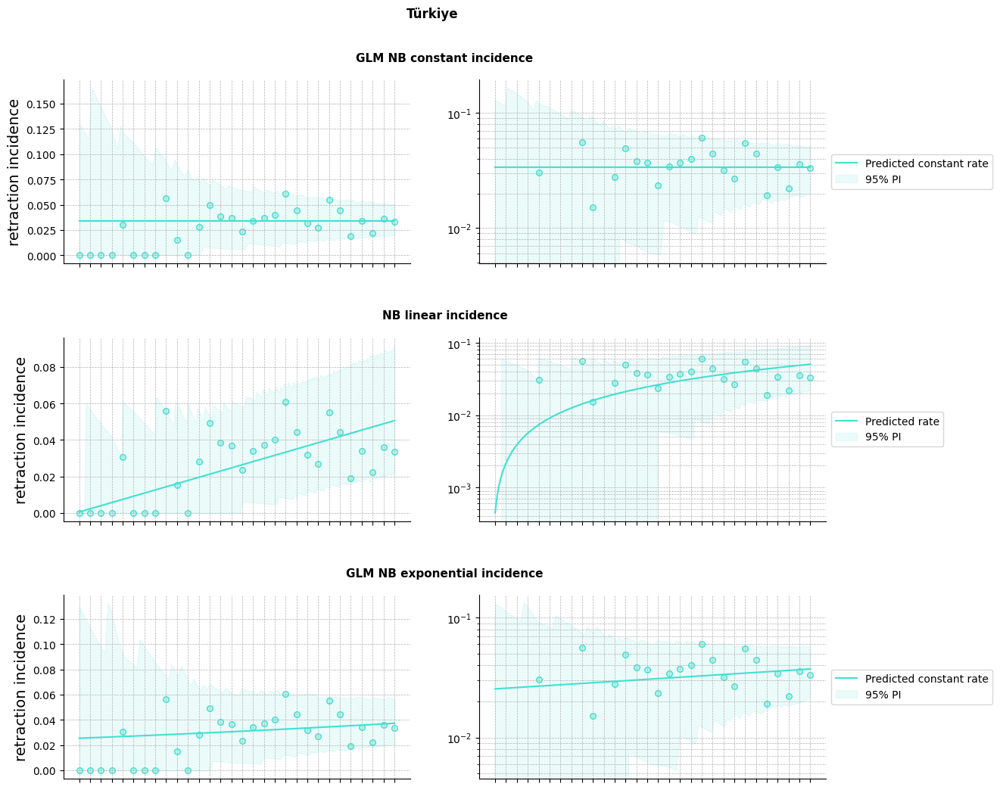

 52%|█████▏    | 11/21 [00:10<00:09,  1.03it/s]

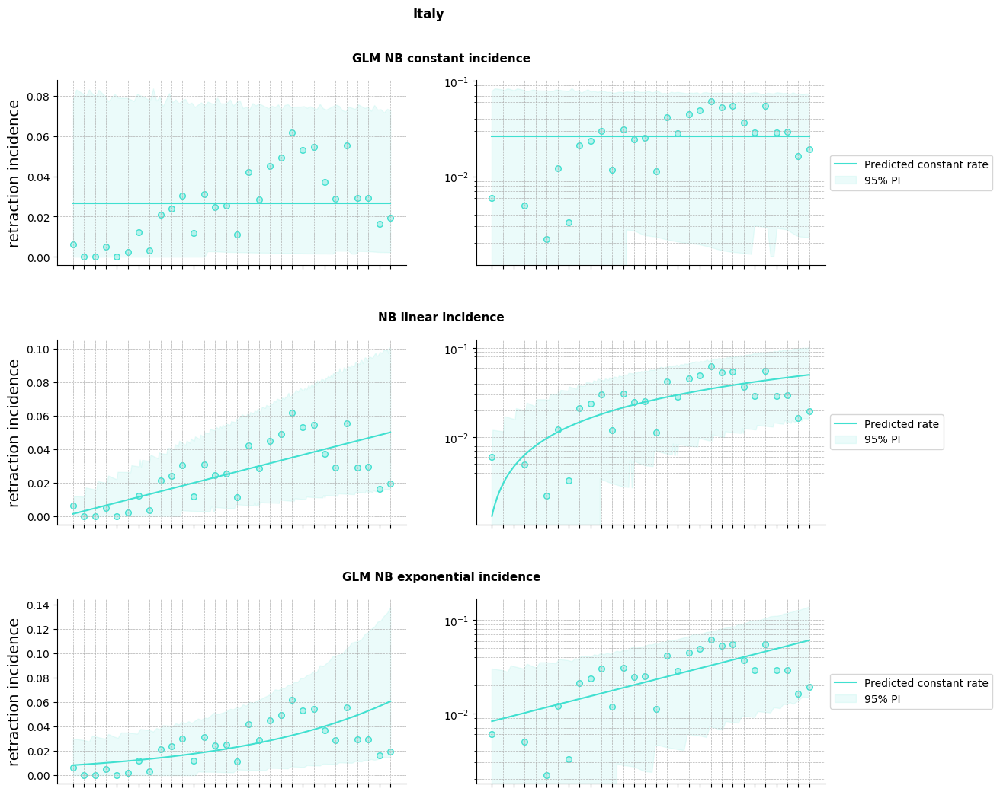

 57%|█████▋    | 12/21 [00:11<00:08,  1.01it/s]

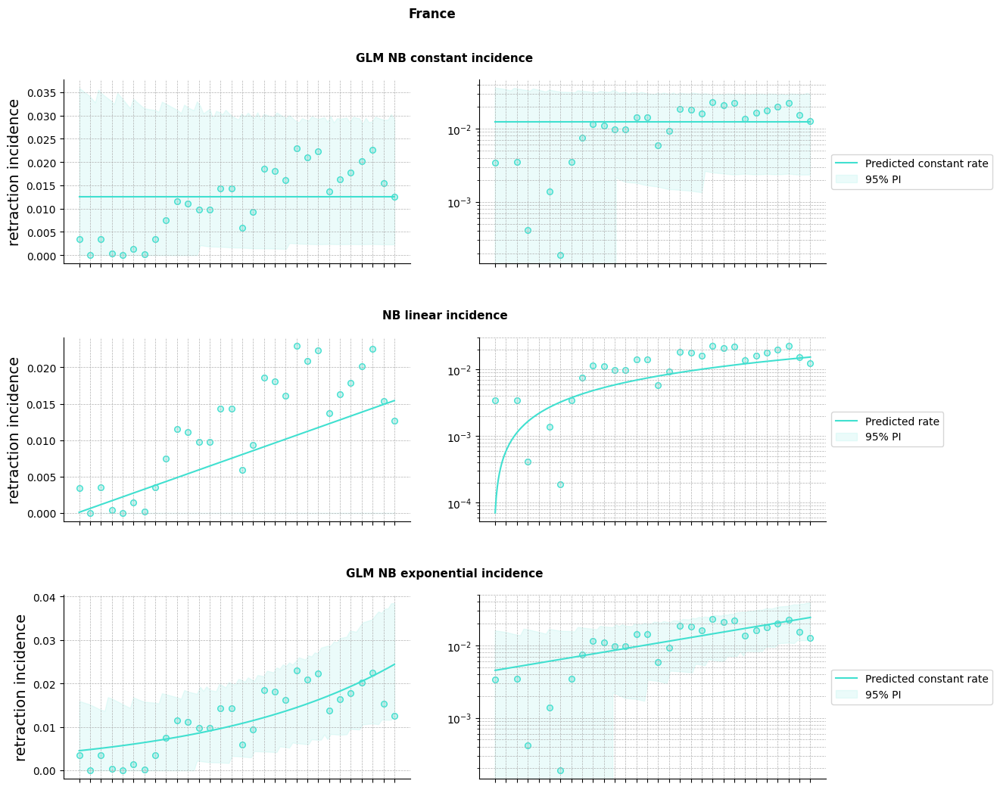

 62%|██████▏   | 13/21 [00:12<00:07,  1.05it/s]

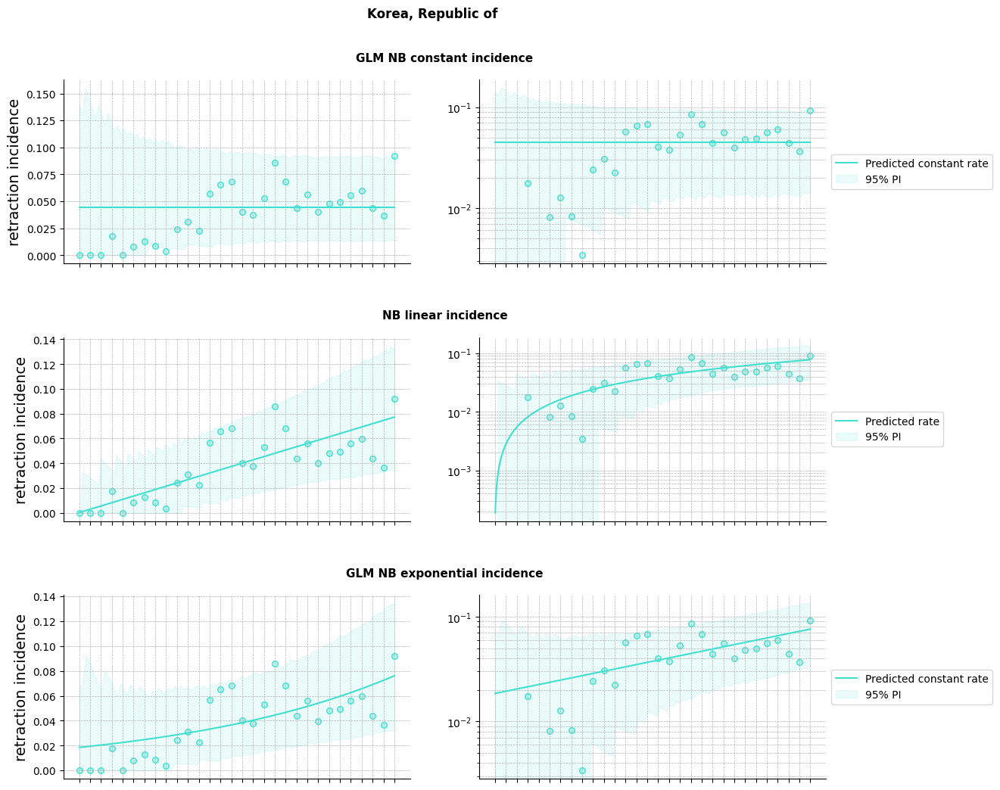

 67%|██████▋   | 14/21 [00:13<00:06,  1.05it/s]

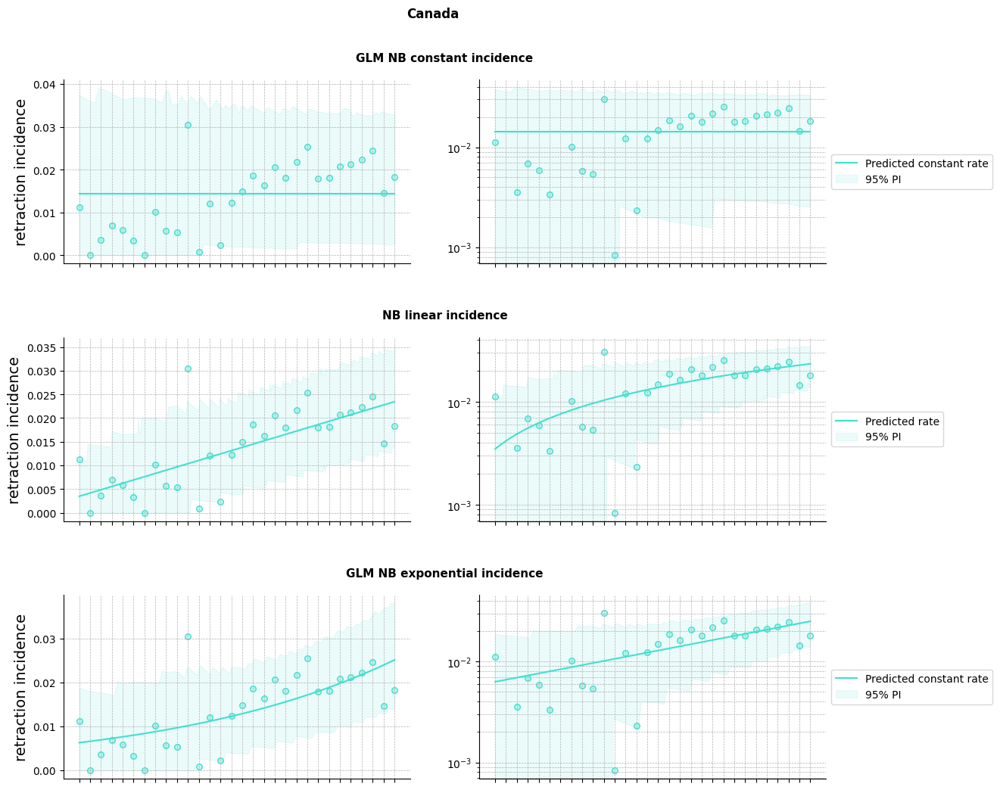

 71%|███████▏  | 15/21 [00:14<00:05,  1.03it/s]

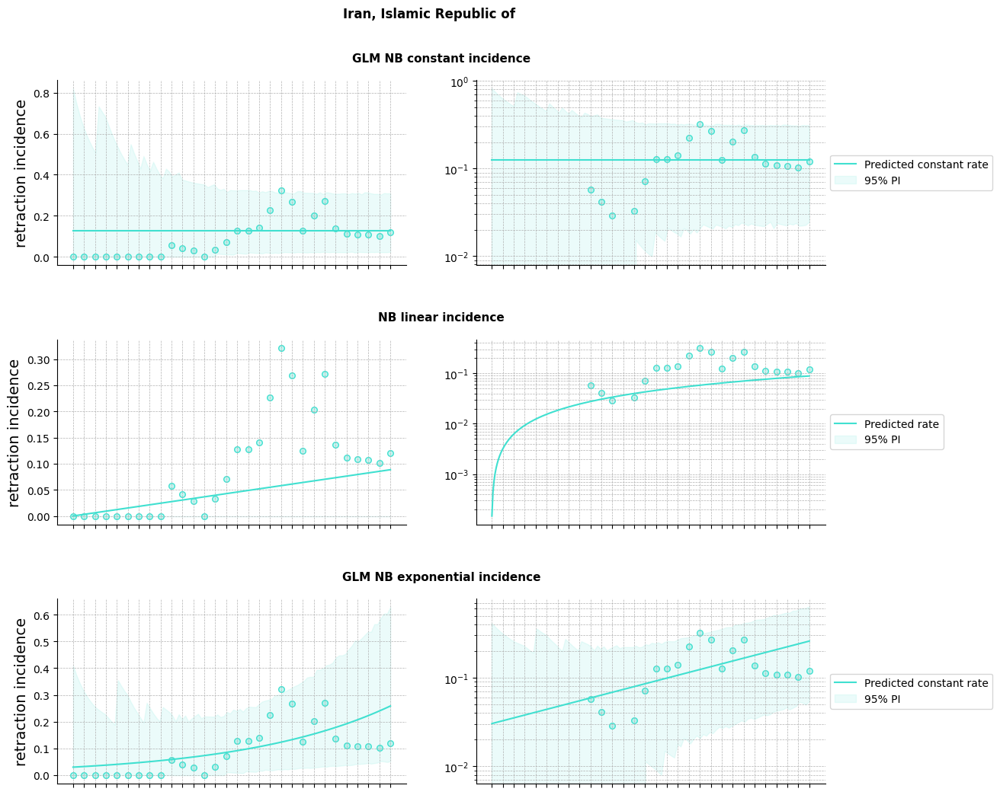

 76%|███████▌  | 16/21 [00:15<00:04,  1.09it/s]

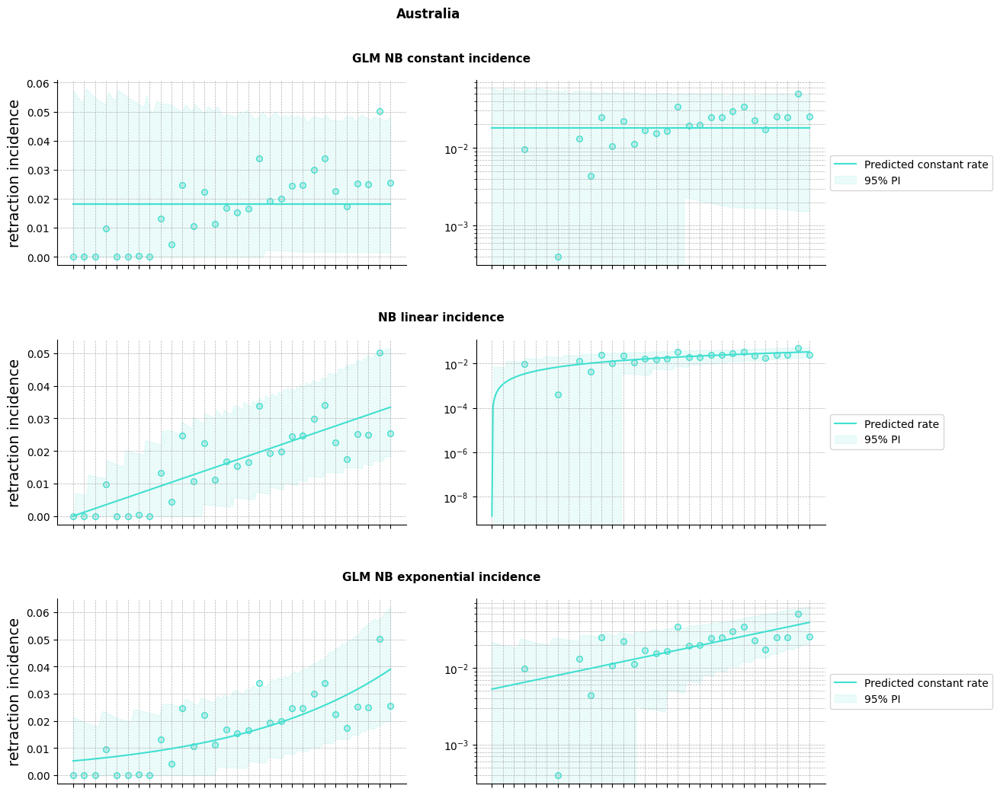

 81%|████████  | 17/21 [00:16<00:03,  1.06it/s]

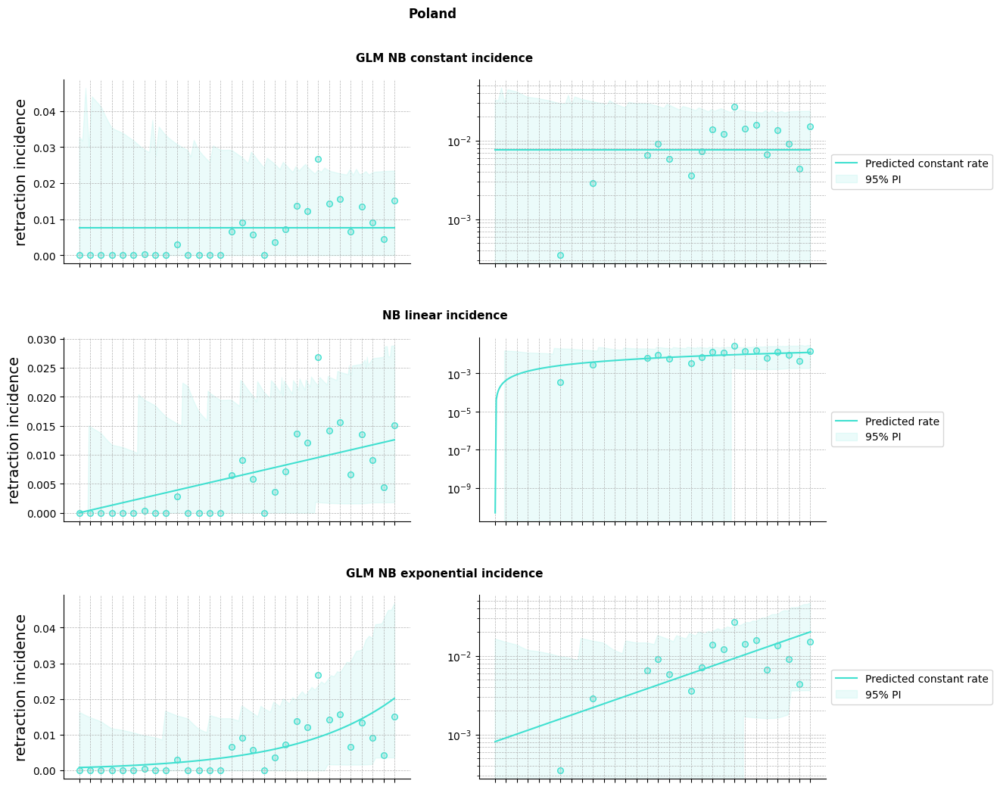

 86%|████████▌ | 18/21 [00:17<00:02,  1.06it/s]

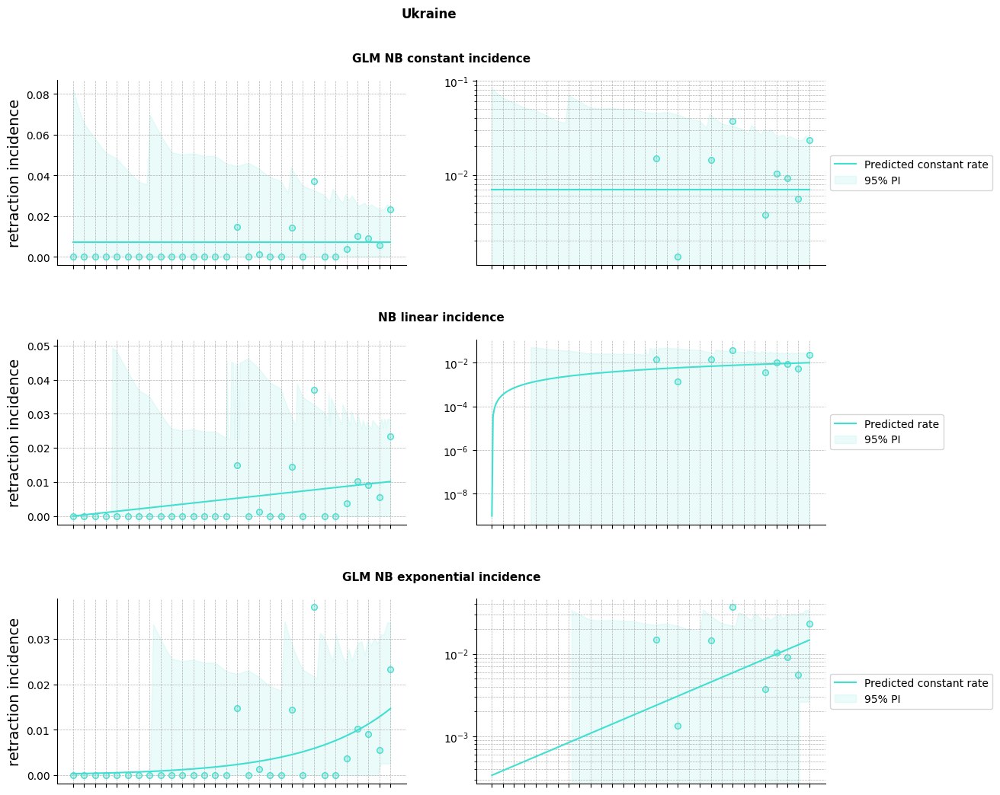

 90%|█████████ | 19/21 [00:17<00:01,  1.11it/s]

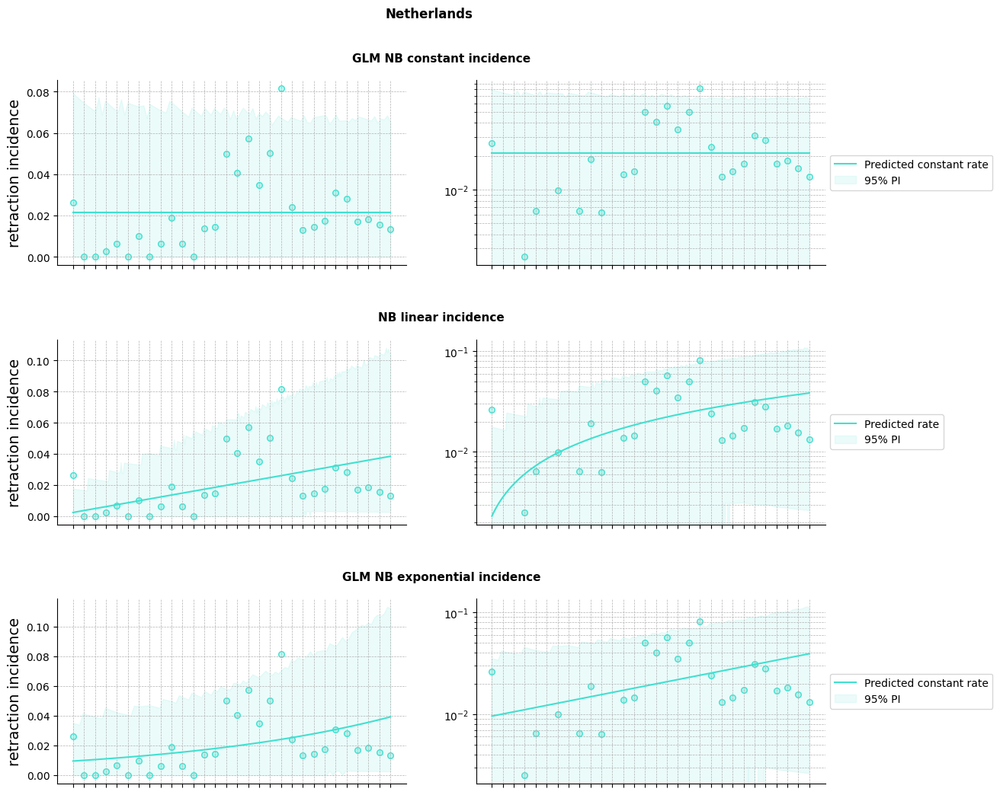

 95%|█████████▌| 20/21 [00:18<00:00,  1.07it/s]

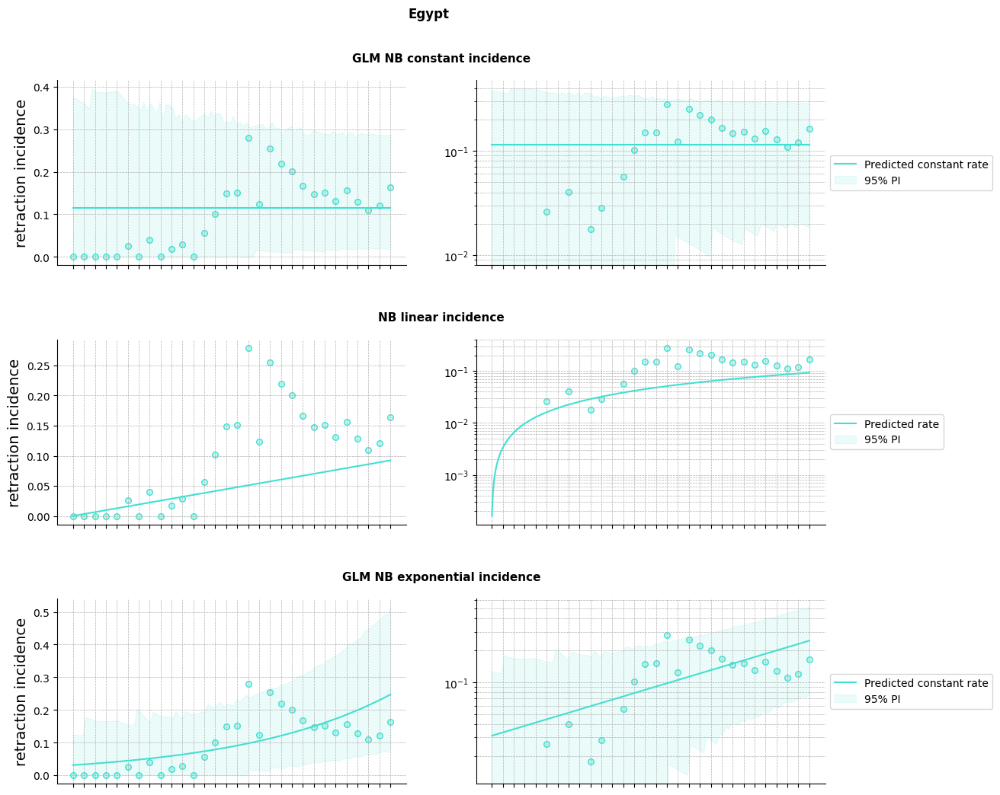

100%|██████████| 21/21 [00:19<00:00,  1.06it/s]


In [41]:
SCALE = 1e2
df = works_retracted_count_bycountry
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_country_df = pd.DataFrame()
for i in tqdm(country_selected_set):
    df_i = df[df.country_code==i]
    results_df = try_all_fit(SCALE,df_i,start_year,end_year,True,output_folder,title,country_code_name_dict,i)
    results_country_df = pd.concat([results_country_df,results_df])
results_country_df = results_country_df.rename(columns={'field_id_scaled':'country_code','field_name':'country_name'})

In [42]:
results_country_df[results_country_df.best_model==1]

,country_code,country_name,start year,end year,model,dof,parameters,BIC,a,b,alpha,p value a,p value b,doubling time,doubling time upper,doubling time lower,ΔBIC,best_model,ΔBIC_weighted
0,CN,China,1992,2021,GLM NB exponential incidence,27,3,261.655050,-11.161494,0.198992,1.405765e-01,0.000000e+00,2.047330e-45,3.483292,4.074369,3.041985,0.0,1,1.000000
0,US,United States,1992,2021,NB linear incidence,27,3,285.081187,0.000012,0.000015,1.110137e-01,4.540097e-02,1.912232e-36,NaN,NaN,NaN,0.0,1,0.999977
0,ID,Indonesia,1992,2021,GLM NB constant incidence,28,2,96.393597,-9.189517,NaN,9.940706e-01,3.058997e-173,NaN,NaN,NaN,NaN,0.0,1,1.000000
0,IN,India,1992,2021,GLM NB exponential incidence,27,3,237.611162,-9.450166,0.129787,2.612831e-01,7.911732e-219,4.693761e-16,5.340655,7.146738,4.263267,0.0,1,1.000000
0,BR,Brazil,1992,2021,GLM NB constant incidence,28,2,139.080030,-9.148753,NaN,1.105552e-01,0.000000e+00,NaN,NaN,NaN,NaN,0.0,1,1.000000
0,RU,Russian Federation,1992,2021,GLM NB exponential incidence,27,3,112.243959,-12.405147,0.160881,2.092650e-01,3.713461e-78,2.620073e-08,4.308438,6.824668,3.147841,0.0,1,1.000000
0,GB,United Kingdom,1992,2021,GLM NB exponential incidence,27,3,202.654383,-10.188988,0.081543,1.922433e-01,0.000000e+00,1.880566e-08,8.500348,13.384745,6.227714,0.0,1,0.999984
0,DE,Germany,1992,2021,GLM NB exponential incidence,27,3,191.394461,-8.027330,-0.023480,3.208560e-02,0.000000e+00,3.607592e-04,-29.520557,-18.740987,-69.490695,0.0,1,0.971000
0,JP,Japan,1992,2021,GLM NB constant incidence,28,2,245.888624,-8.190126,NaN,2.023082e-01,0.000000e+00,NaN,NaN,NaN,NaN,0.0,1,1.000000
0,ES,Spain,1992,2021,GLM NB exponential incidence,27,3,150.469047,-9.457127,0.044745,2.880645e-02,4.504523e-276,4.496080e-04,15.491062,37.302267,9.775297,0.0,1,0.999420


  0%|          | 0/21 [00:00<?, ?it/s]

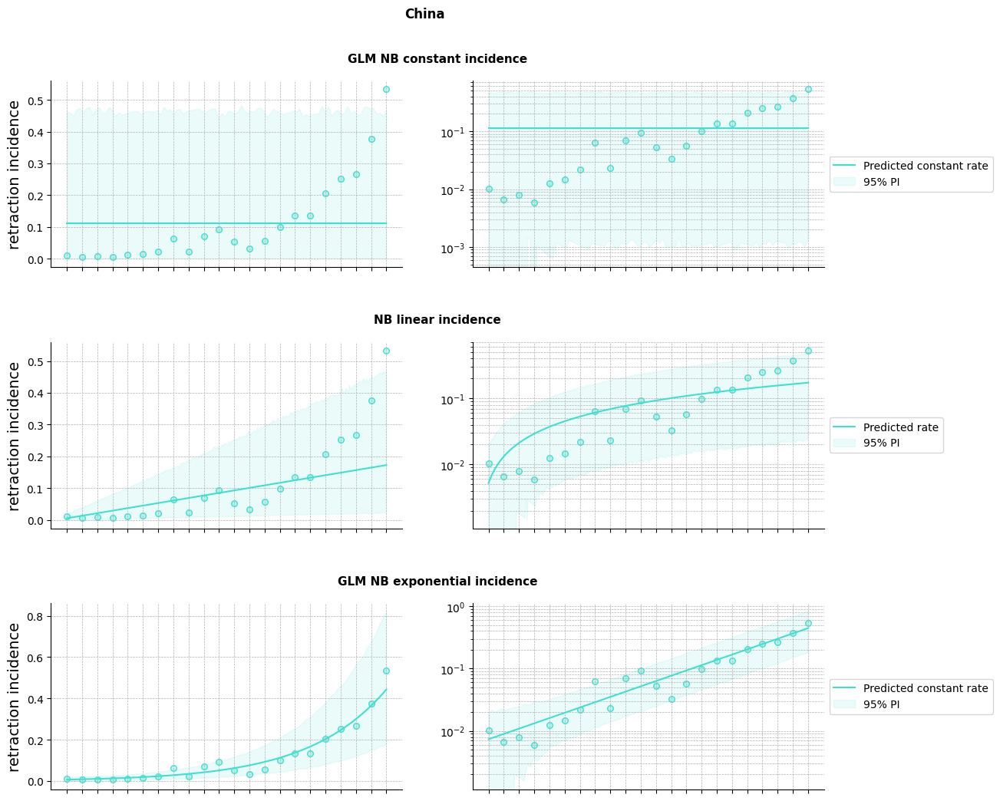

  5%|▍         | 1/21 [00:00<00:19,  1.05it/s]

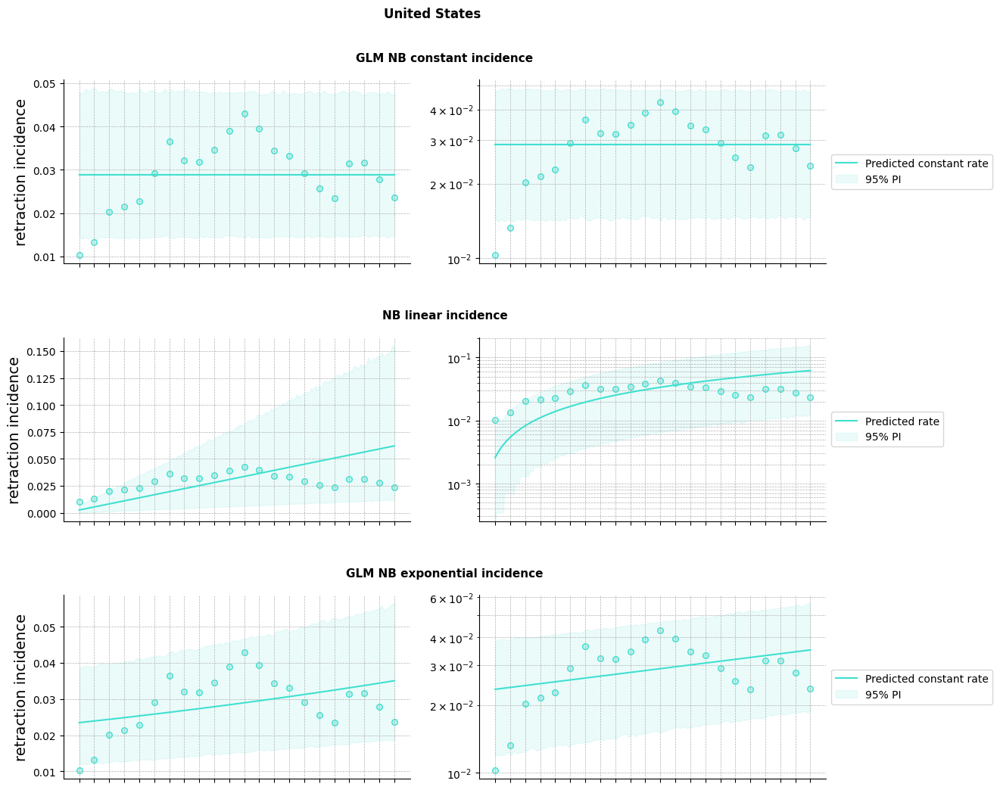

 10%|▉         | 2/21 [00:01<00:17,  1.10it/s]

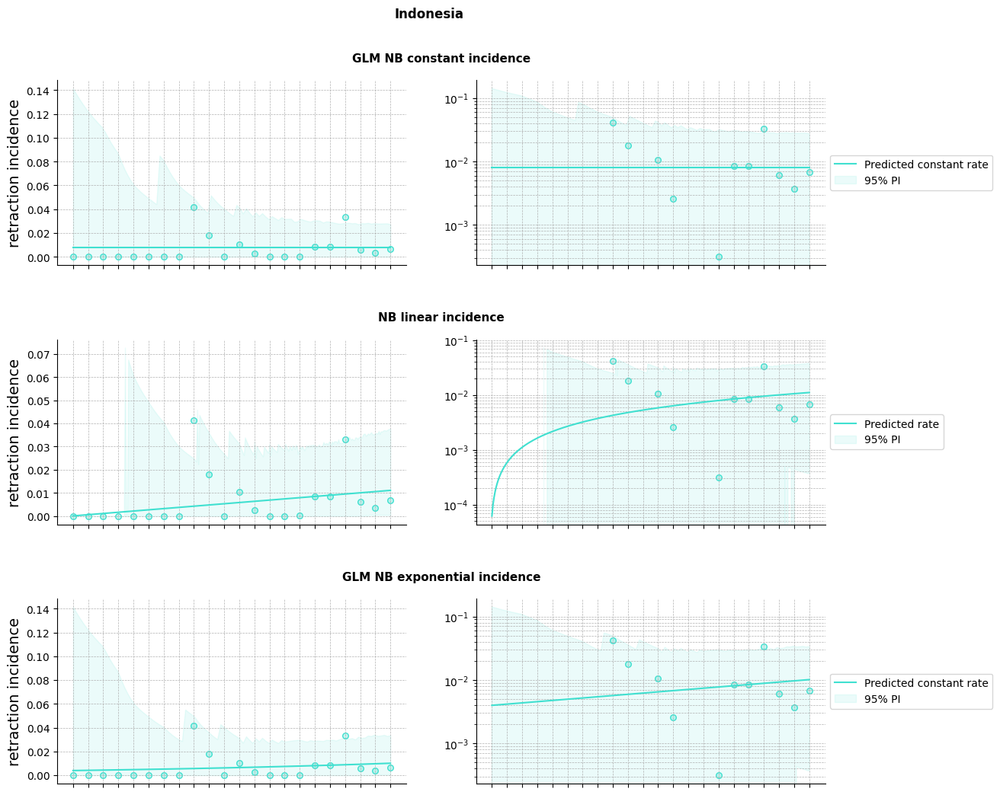

 14%|█▍        | 3/21 [00:02<00:16,  1.09it/s]

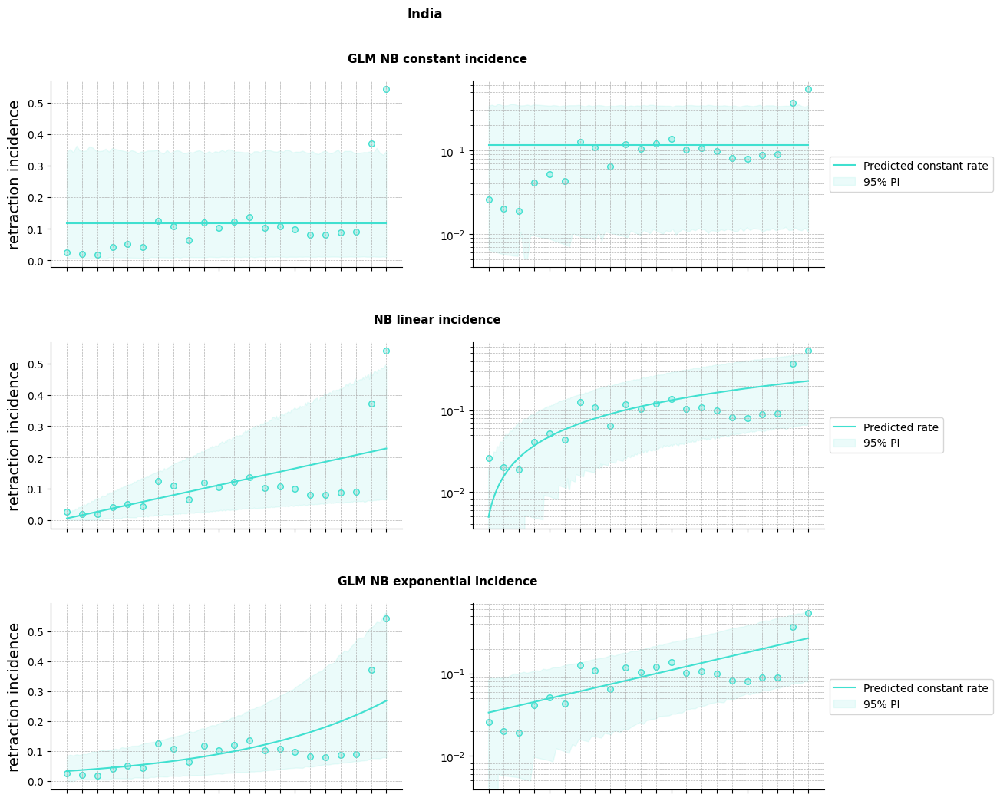

 19%|█▉        | 4/21 [00:03<00:15,  1.08it/s]

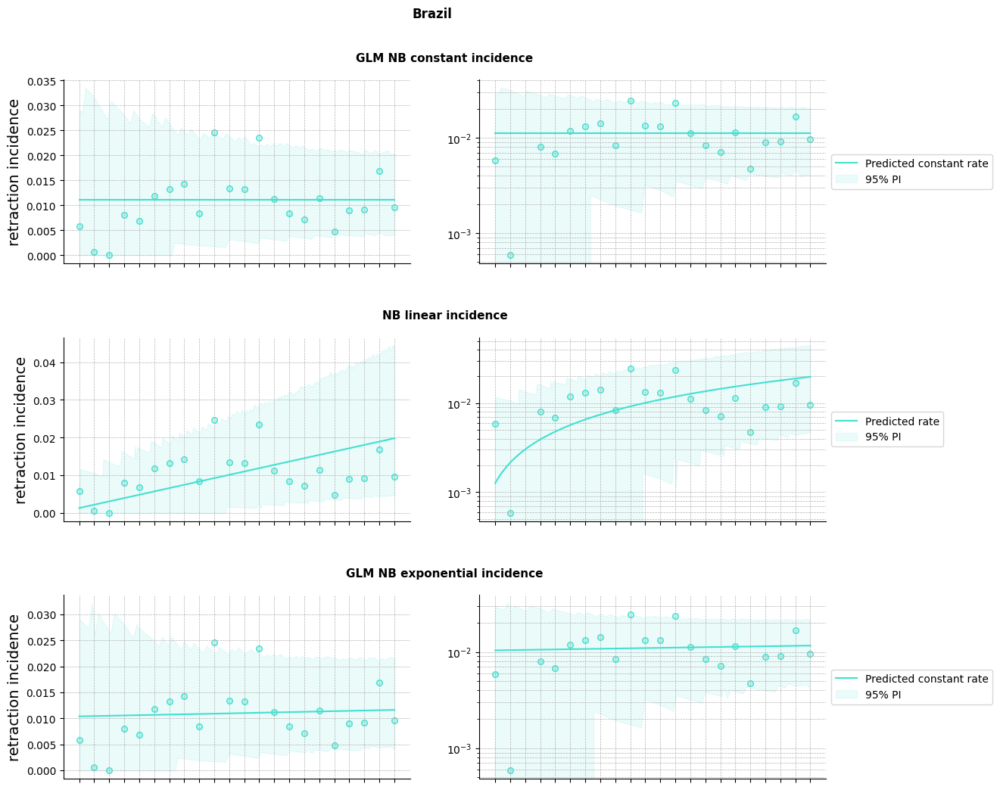

 24%|██▍       | 5/21 [00:04<00:14,  1.08it/s]

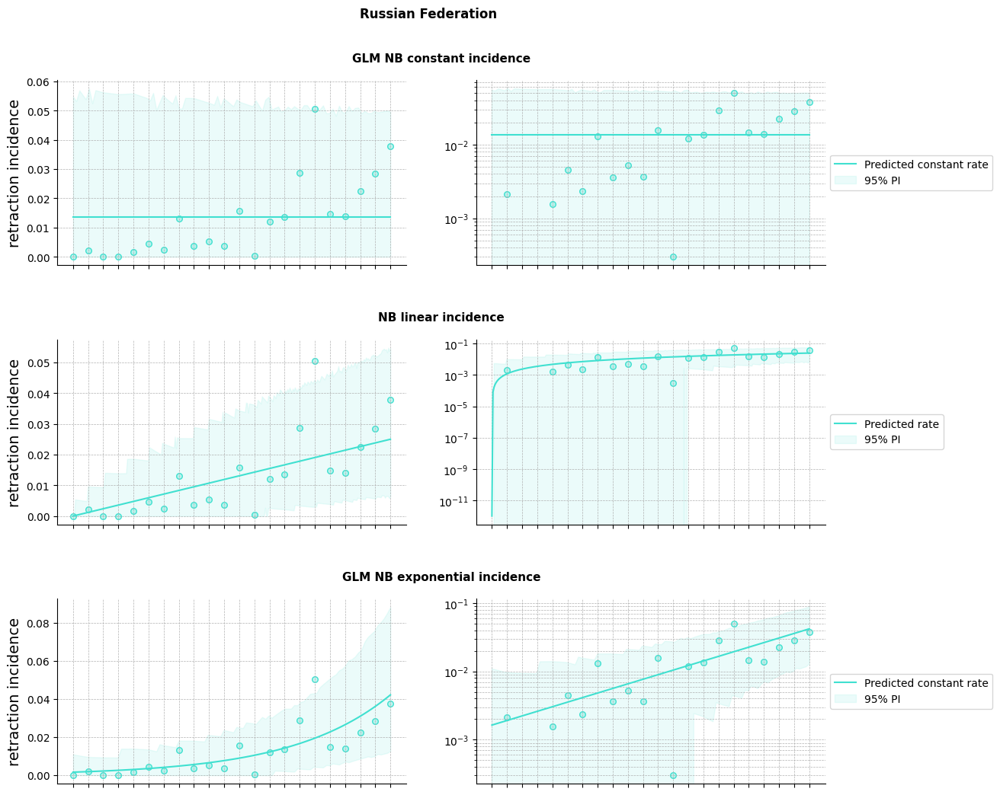

 29%|██▊       | 6/21 [00:05<00:14,  1.06it/s]

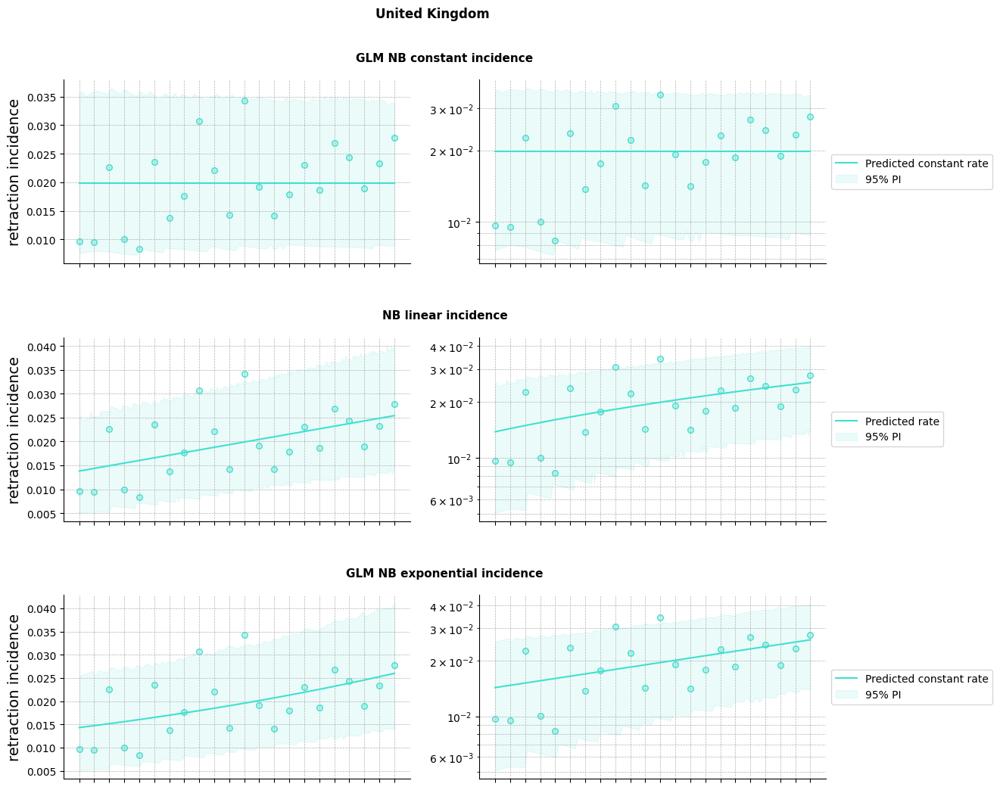

 33%|███▎      | 7/21 [00:06<00:13,  1.07it/s]

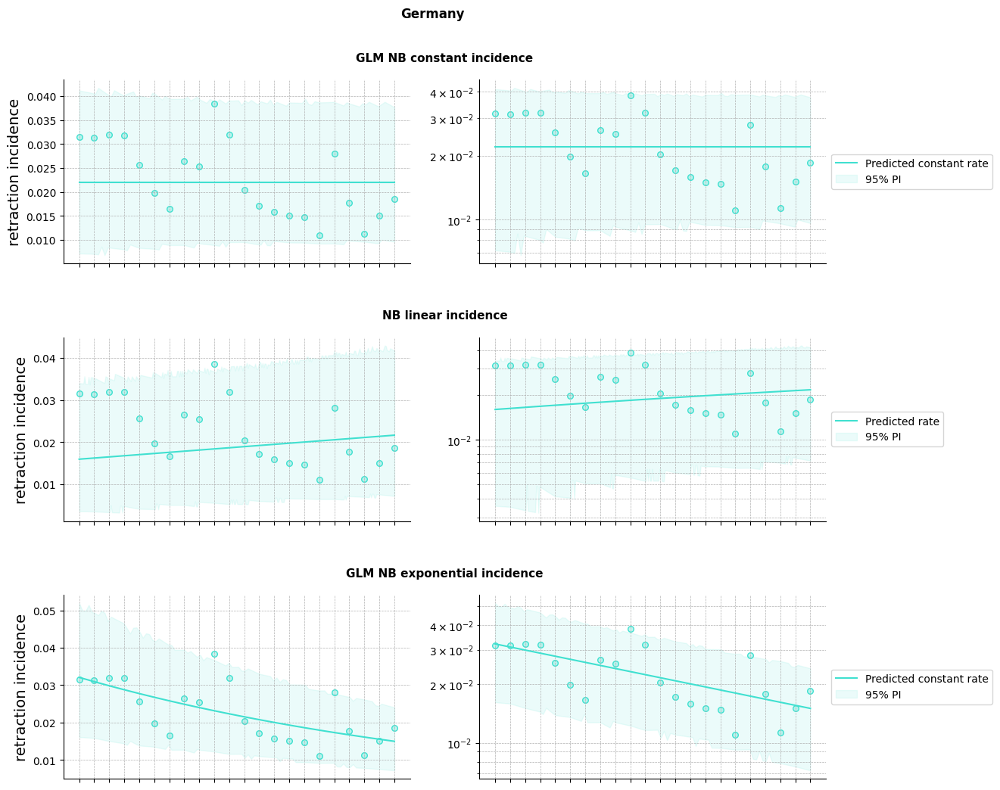

 38%|███▊      | 8/21 [00:07<00:12,  1.06it/s]

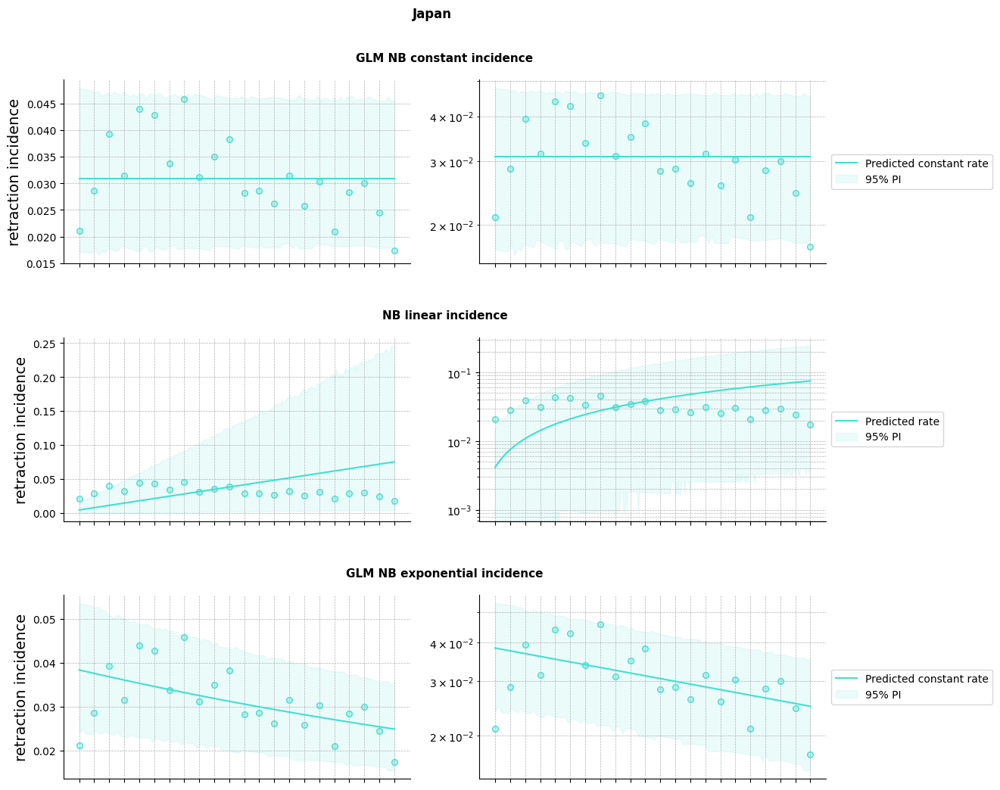

 43%|████▎     | 9/21 [00:08<00:11,  1.07it/s]

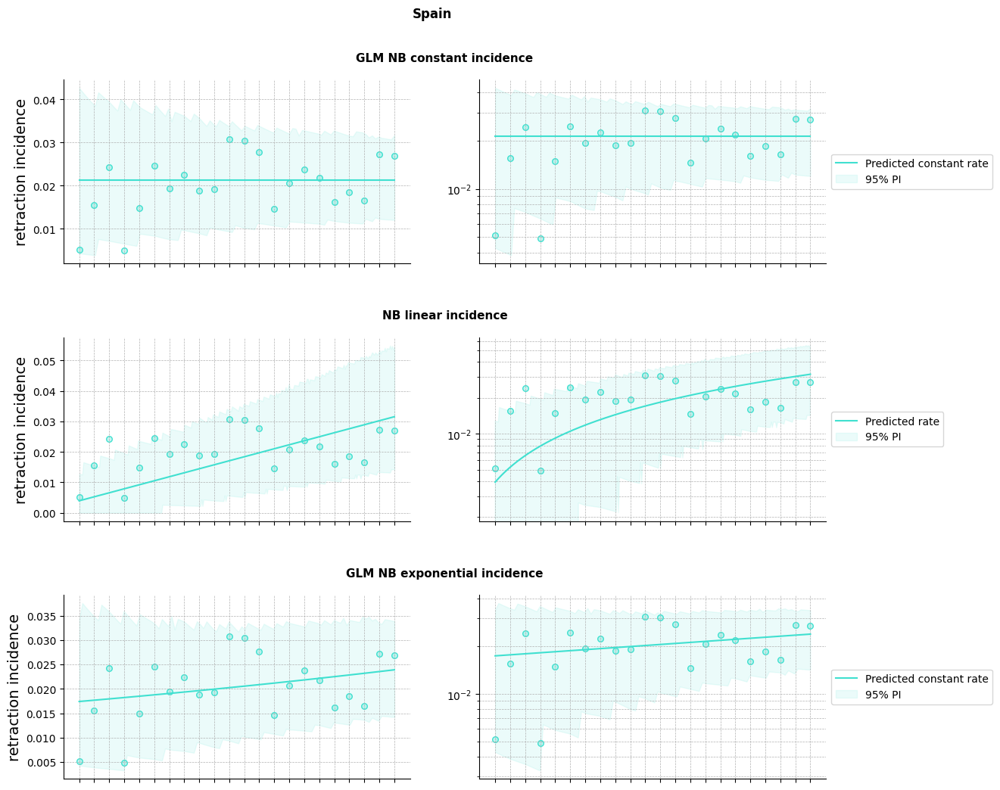

 48%|████▊     | 10/21 [00:09<00:10,  1.06it/s]

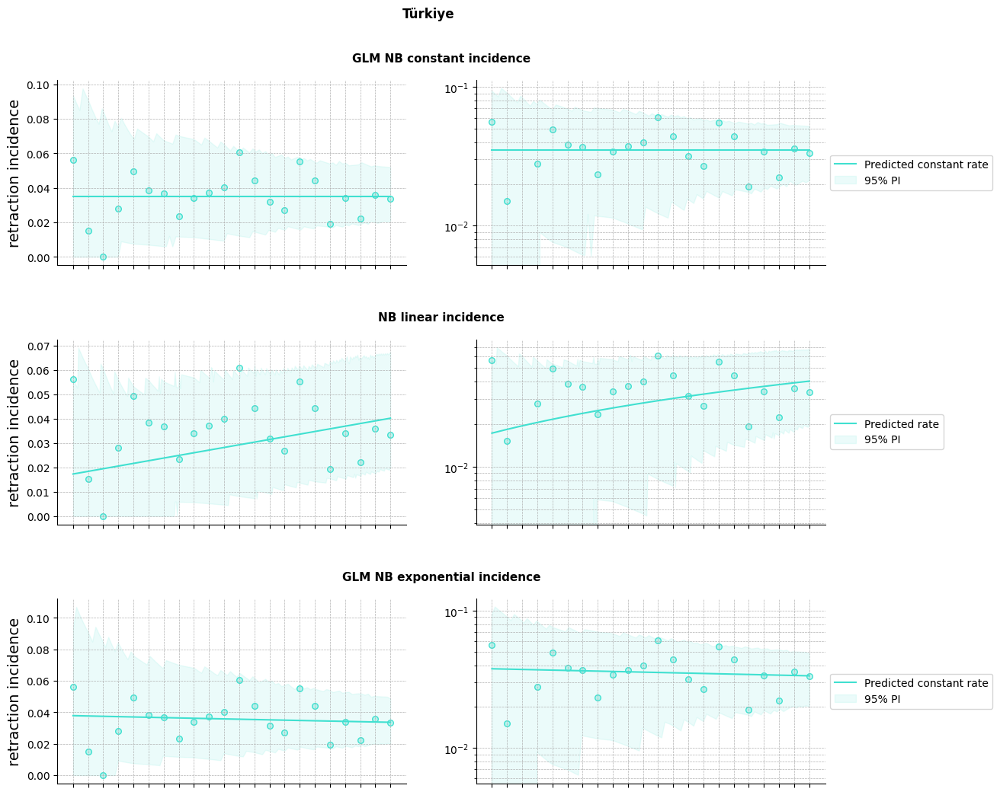

 52%|█████▏    | 11/21 [00:10<00:09,  1.07it/s]

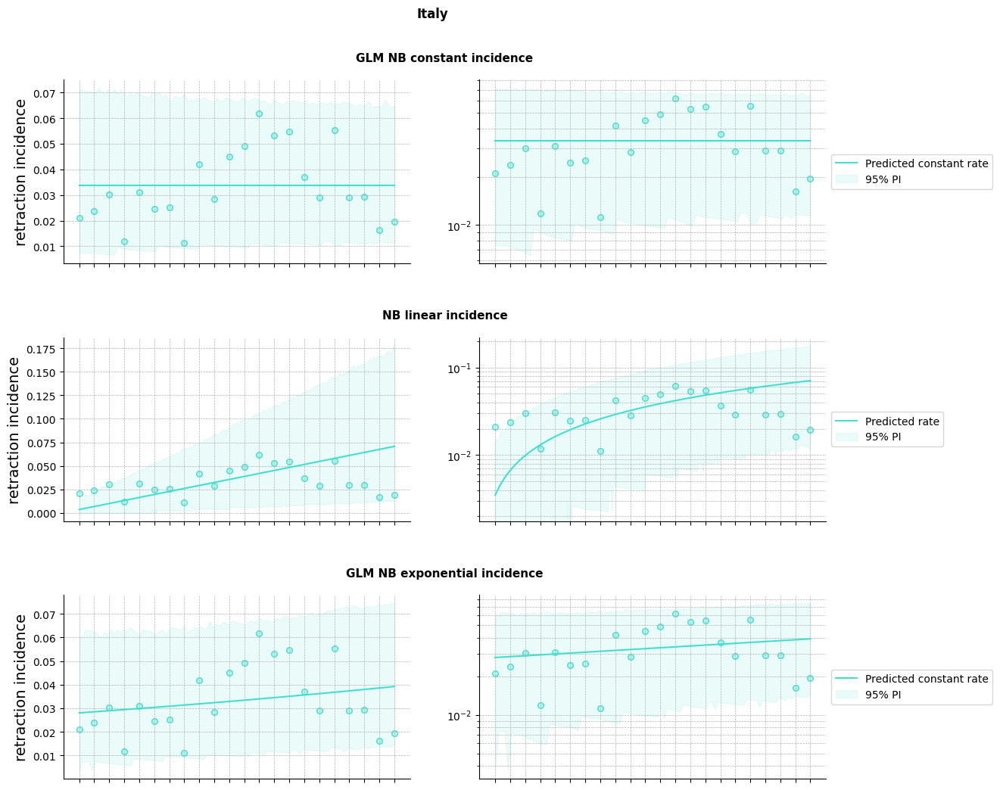

 57%|█████▋    | 12/21 [00:11<00:08,  1.07it/s]

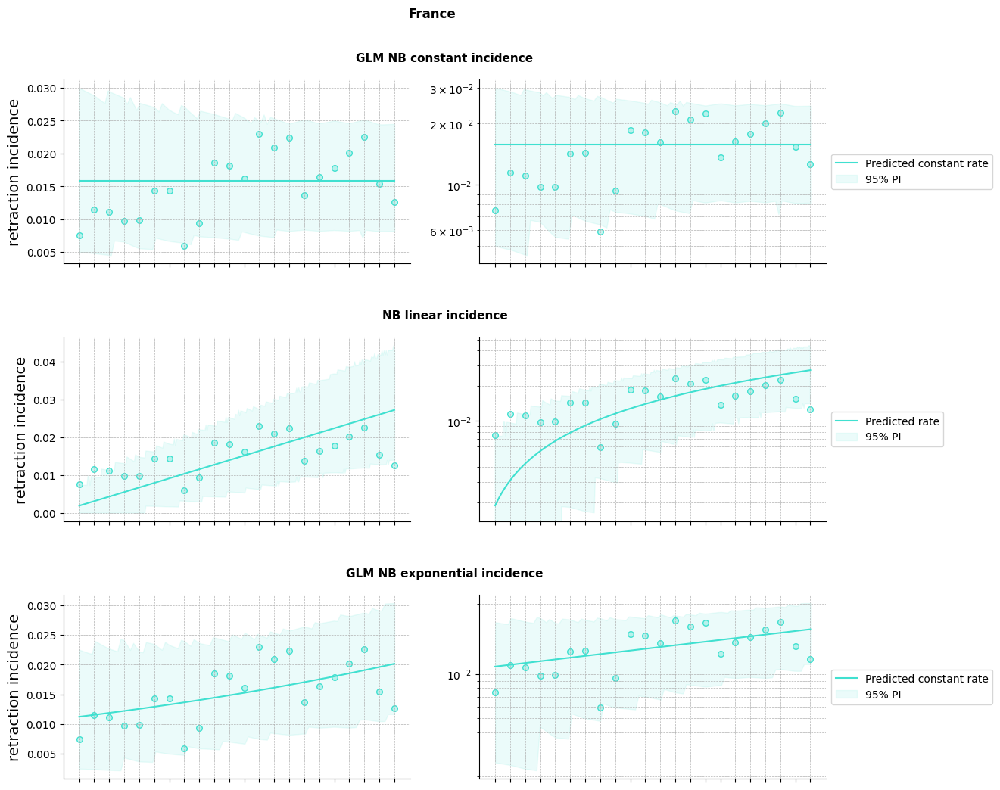

 62%|██████▏   | 13/21 [00:12<00:07,  1.05it/s]

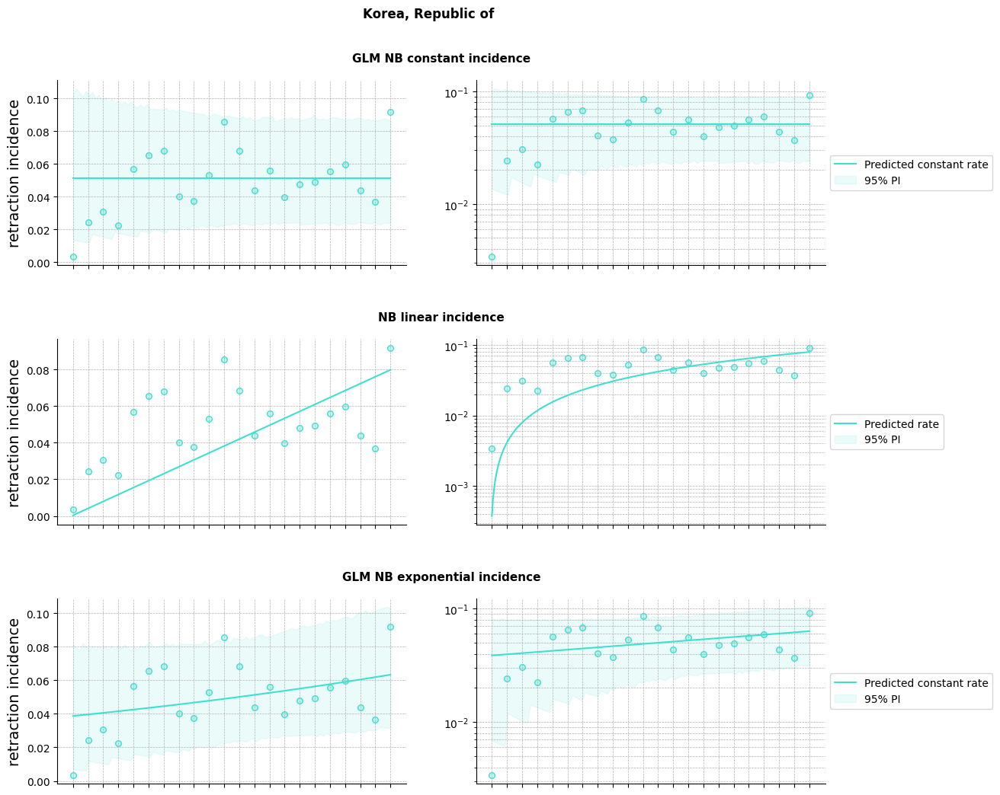

 67%|██████▋   | 14/21 [00:13<00:06,  1.09it/s]

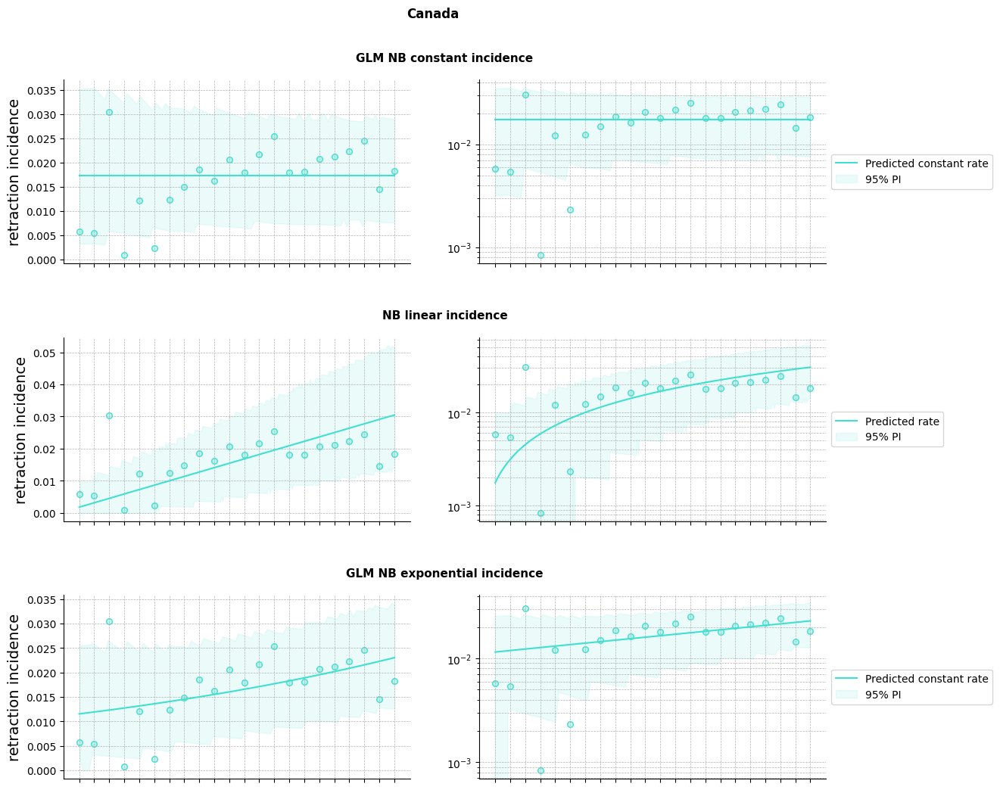

 71%|███████▏  | 15/21 [00:13<00:05,  1.08it/s]

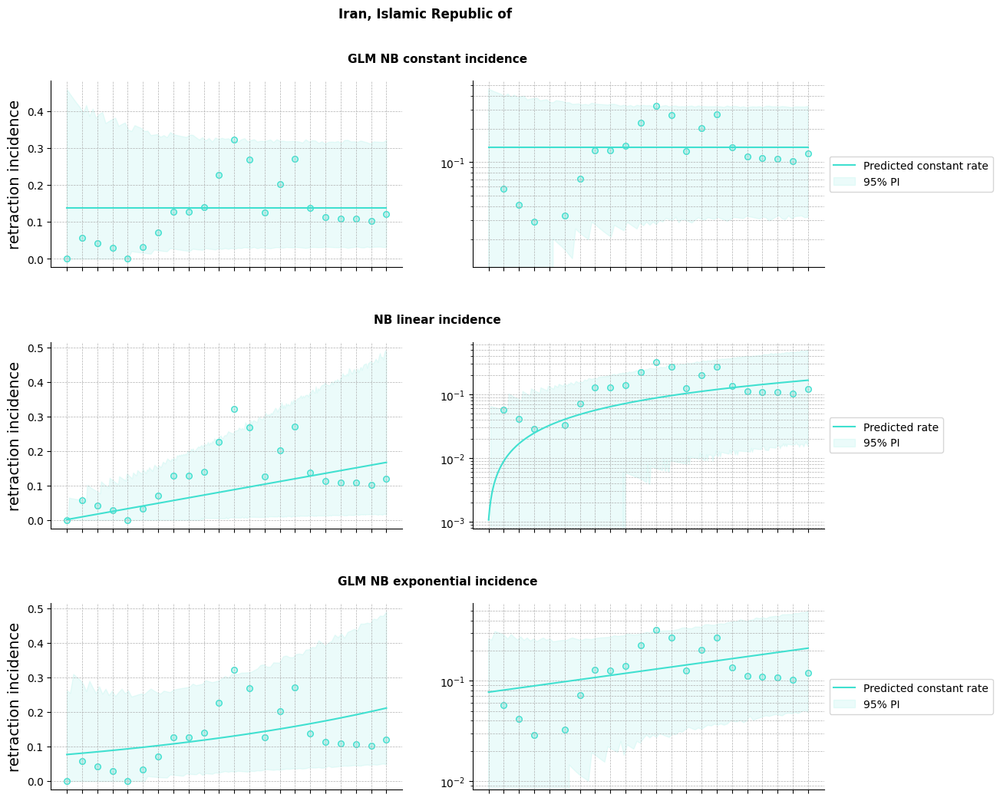

 76%|███████▌  | 16/21 [00:14<00:04,  1.07it/s]

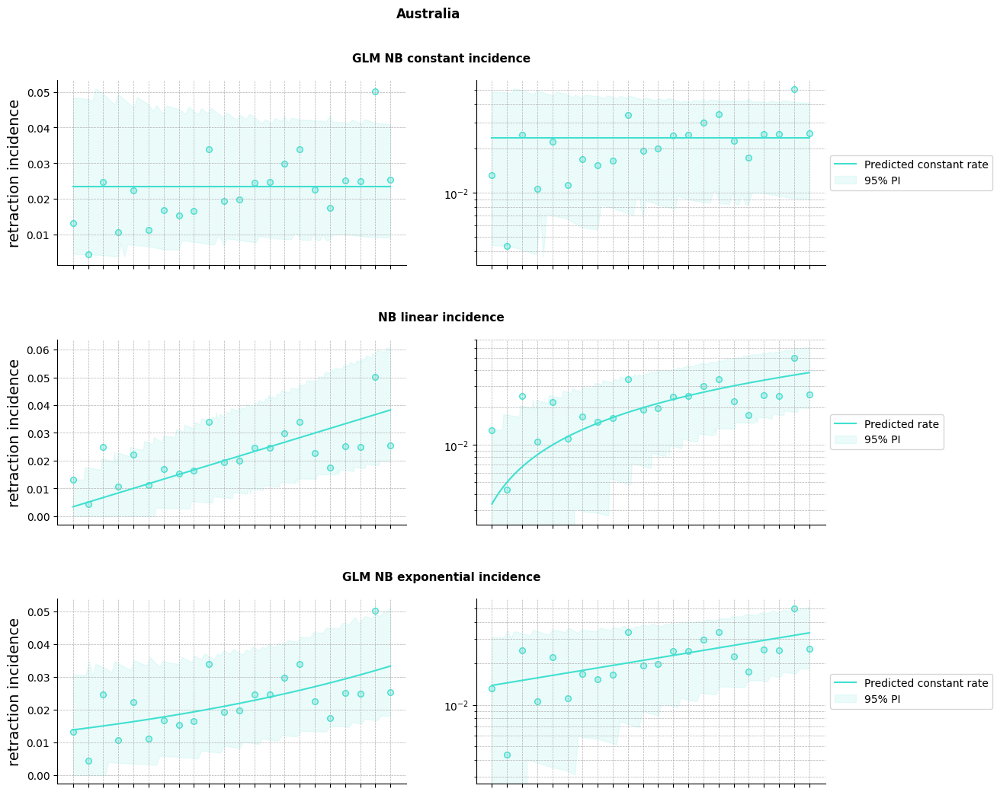

 81%|████████  | 17/21 [00:15<00:03,  1.08it/s]

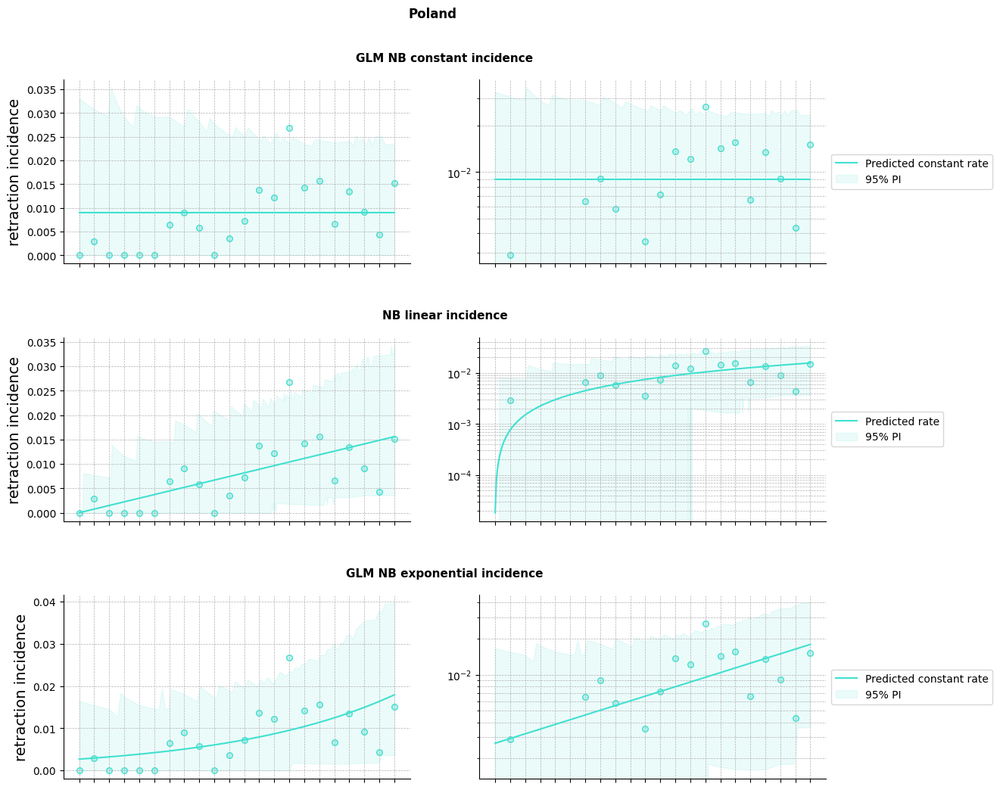

 86%|████████▌ | 18/21 [00:16<00:02,  1.06it/s]

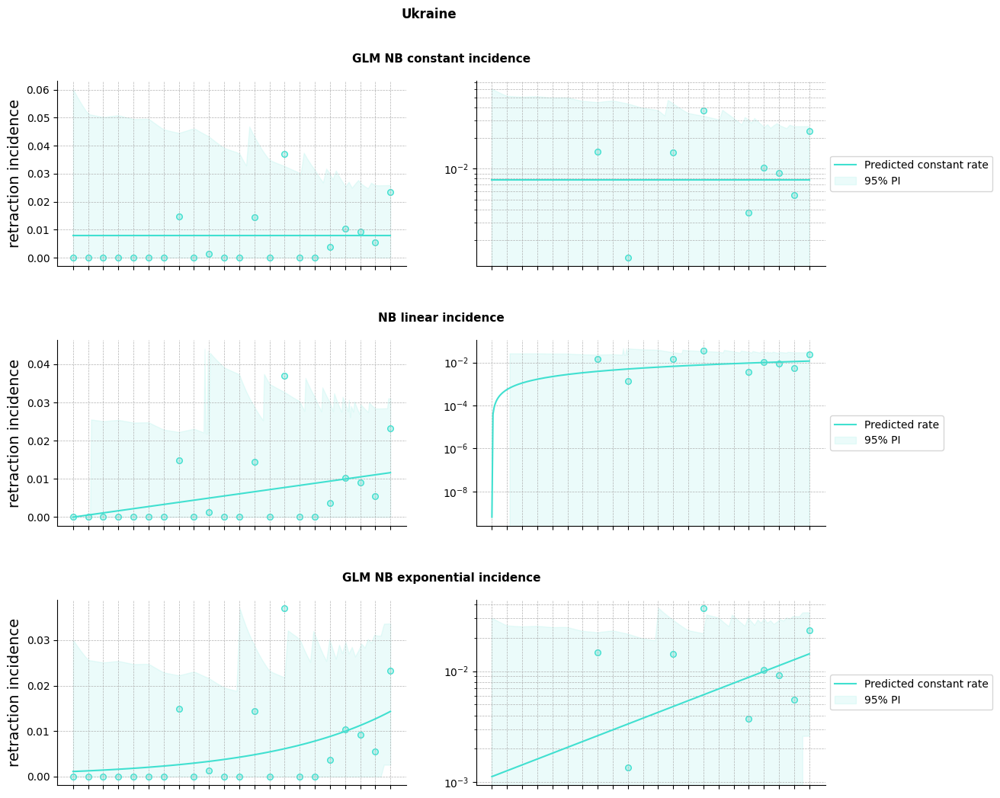

 90%|█████████ | 19/21 [00:17<00:01,  1.11it/s]

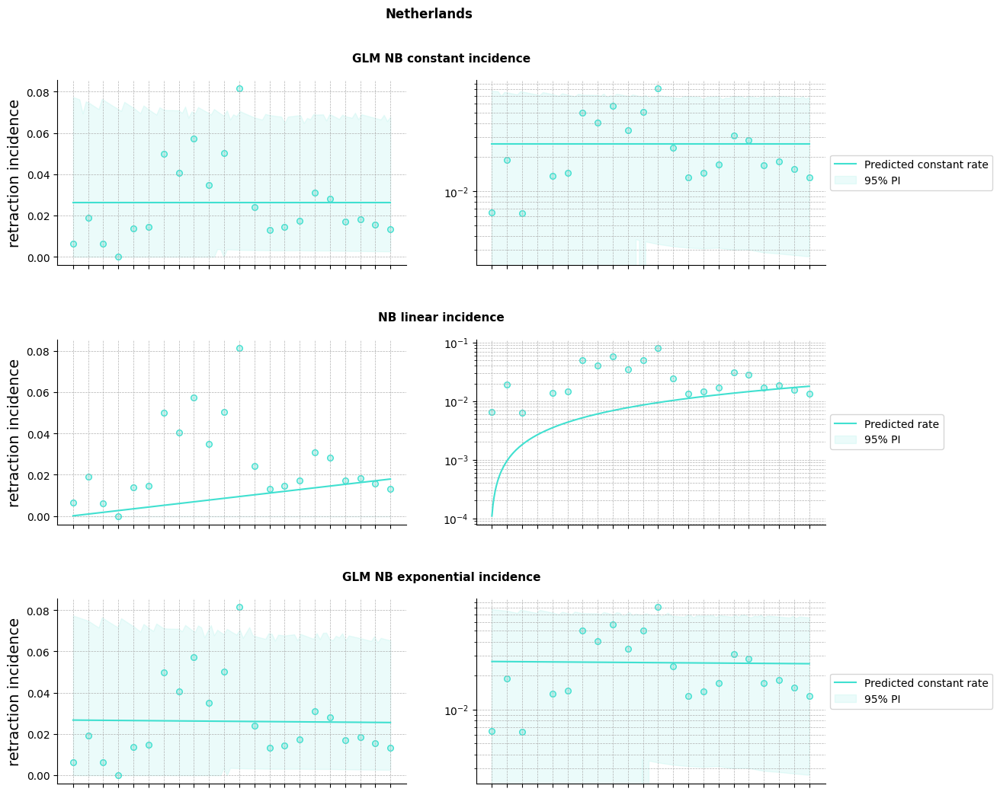

 95%|█████████▌| 20/21 [00:18<00:00,  1.13it/s]

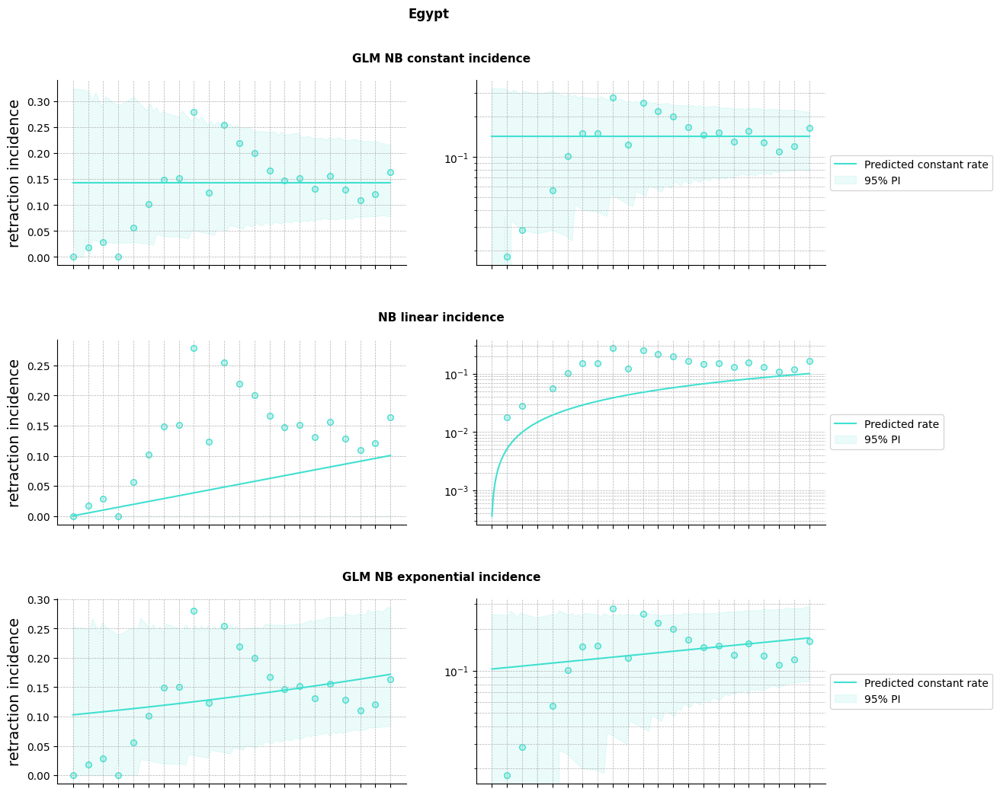

100%|██████████| 21/21 [00:19<00:00,  1.09it/s]


In [43]:
### robust analysis: different time period

SCALE = 1e2
df = works_retracted_count_bycountry.copy()
start_year=2000
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_country_df2 = pd.DataFrame()
for i in tqdm(country_selected_set):
    df_i = df[df.country_code==i]
    results_df = try_all_fit(SCALE,df_i,start_year,end_year,True,output_folder,title,country_code_name_dict,i)
    results_country_df2 = pd.concat([results_country_df2,results_df])
results_country_df2 = results_country_df2.rename(columns={'field_id_scaled':'country_code','field_name':'country_name'})

In [44]:
results_country_df2[results_country_df2.best_model==1]

,country_code,country_name,start year,end year,model,dof,parameters,BIC,a,b,alpha,p value a,p value b,doubling time,doubling time upper,doubling time lower,ΔBIC,best_model,ΔBIC_weighted
0,CN,China,2000,2021,GLM NB exponential incidence,19,3,251.174482,-9.517449,0.195213,1.406539e-01,0.000000e+00,1.466583e-38,3.550730,4.232974,3.057880,0.0,1,1.000000
0,US,United States,2000,2021,GLM NB constant incidence,20,2,227.509190,-8.148745,NaN,8.033369e-02,0.000000e+00,NaN,NaN,NaN,NaN,0.0,1,1.000000
0,ID,Indonesia,2000,2021,GLM NB constant incidence,20,2,76.327094,-9.434771,NaN,8.396260e-01,7.994171e-239,NaN,NaN,NaN,NaN,0.0,1,1.000000
0,IN,India,2000,2021,GLM NB exponential incidence,19,3,212.962771,-7.998966,0.099022,2.165241e-01,5.772239e-277,1.195736e-08,6.999920,11.061397,5.119986,0.0,1,0.910320
0,BR,Brazil,2000,2021,GLM NB constant incidence,20,2,120.914617,-9.101686,NaN,9.289124e-02,0.000000e+00,NaN,NaN,NaN,NaN,0.0,1,1.000000
0,RU,Russian Federation,2000,2021,GLM NB exponential incidence,19,3,108.211541,-11.018173,0.154600,2.054116e-01,1.024168e-116,7.282152e-07,4.483497,7.763883,3.151802,0.0,1,0.999940
0,GB,United Kingdom,2000,2021,NB linear incidence,19,3,150.721775,0.000138,0.000006,3.831322e-02,4.638146e-09,7.533165e-03,NaN,NaN,NaN,0.0,1,0.531065
0,DE,Germany,2000,2021,GLM NB exponential incidence,19,3,144.180496,-8.044563,-0.036204,2.542622e-02,0.000000e+00,1.286525e-04,-19.145841,-12.379144,-42.229197,0.0,1,0.985012
0,JP,Japan,2000,2021,GLM NB exponential incidence,19,3,155.084982,-7.866002,-0.020637,8.155476e-03,0.000000e+00,1.867813e-03,-33.587172,-20.077293,-102.679614,0.0,1,0.914451
0,ES,Spain,2000,2021,GLM NB constant incidence,20,2,120.141427,-8.457439,NaN,1.339472e-08,0.000000e+00,NaN,NaN,NaN,NaN,0.0,1,0.999979


In [45]:
## rolling window (5 years) average and std
df = works_retracted_count_bycountry.copy()
start_year=2000
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
SCALE = 1e2
df['retracted_incidence'] = (df['retracted'] / df['total'])*SCALE
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
window_size = 5
df_rolling = retracted_rolling_average(df,window_size,'country_code')
df_rolling

,country_code,year,mean,var
0,AU,2004,0.015045,0.000057
1,AU,2005,0.014649,0.000059
2,AU,2006,0.017148,0.000032
3,AU,2007,0.015261,0.000018
4,AU,2008,0.016435,0.000013
...,...,...,...,...
373,US,2017,0.029164,0.000018
374,US,2018,0.028574,0.000013
375,US,2019,0.028249,0.000011
376,US,2020,0.027981,0.000010


In [46]:
df = results_country_df
df = df[['start year','end year','country_code','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df1 = df.sort_values(by=['country_code', 'model_order'])

df = results_country_df2
df = df[['start year','end year','country_code','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df2 = df.sort_values(by=['country_code', 'model_order'])

df = pd.concat([df1,df2]).drop(columns='model_order')
df

,start year,end year,country_code,model,ΔBIC,ΔBIC_weighted
0,1992,2021,AU,constant,27.458689,1.089986e-06
0,1992,2021,AU,exponential,0.000000,9.999989e-01
0,1992,2021,BR,constant,0.000000,1.000000e+00
0,1992,2021,CA,constant,21.034640,2.250289e-05
0,1992,2021,CA,linear,0.000000,8.314811e-01
...,...,...,...,...,...,...
0,2000,2021,TR,constant,0.000000,9.972816e-01
0,2000,2021,TR,linear,11.809946,2.718446e-03
0,2000,2021,UA,constant,0.000000,1.000000e+00
0,2000,2021,US,constant,0.000000,1.000000e+00


In [ ]:
start_year = 1992
end_year = 2021
alpha = 1
model_func_name = {'GLM NB exponential incidence'}
country_set = set((results_country_df[results_country_df.model.isin(model_func_name)].query('best_model==1').country_name))
country_set = country_set - {'Germany'}
df0 = results_country_df[results_country_df.country_name.isin(country_set)]
sorted_countrys = list(df0['country_code'].unique())
sorted_countrys.sort()
df1 = df0[df0.best_model==1][['start year','end year', 'country_code','country_name','alpha','b','p value b','doubling time','doubling time lower','doubling time upper']]
df2 = pd.DataFrame()
for country in sorted_countrys:
    temp = pd.read_csv(os.path.join('./Retracted/Plots/plots_countries', f'observed_df_{country}_{start_year}_{end_year}_{'GLM NB exponential incidence'}.csv')).rename(columns={'field_id_scaled':'country_code','field_name':'country_name'})
    temp = temp[temp.year==29][['country_code','observed_rate']]
    df2 = pd.concat([df2,temp])
df3 = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(sorted_countrys)]
df3 = df3[df3.year == end_year]
df3 = df3[['country_code','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='country_code').merge(df3,on='country_code')
df = df.rename(columns={'b':'g','p value b':'p-value'})
#df = df[df.country_code.isin({'CN','IN','RU'})]
df = df[['start year','end year', 'country_code', 'country_name','alpha' , 'g','p-value', 'doubling time','doubling time lower','doubling time upper','observed_rate','retracted']]
df = df.sort_values(by=['country_name'],ascending=[False]).reset_index(drop=True).reset_index()
temp1 = df.rename(columns={'doubling time':'doubling_time'}).drop(columns=['index','observed_rate','retracted'])

start_year = 2000
end_year = 2021
alpha = 1
model_func_name = {'GLM NB exponential incidence'}
country_set = set((results_country_df2[results_country_df2.model.isin(model_func_name)].query('best_model==1').country_name))
df0 = results_country_df2[results_country_df2.country_name.isin(country_set)]
sorted_countrys = list(df0['country_code'].unique())
sorted_countrys.sort()
df1 = df0[df0.best_model==1][['start year','end year', 'country_code','country_name','alpha','b','p value b','doubling time','doubling time lower','doubling time upper']]
df2 = pd.DataFrame()
for country in sorted_countrys:
    temp = pd.read_csv(os.path.join('./Retracted/Plots/plots_countries', f'observed_df_{country}_{start_year}_{end_year}_{'GLM NB exponential incidence'}.csv')).drop(columns='field_name').rename(columns={'field_id_scaled':'country_code'})
    temp = temp[temp.year==21][['country_code','observed_rate']]
    df2 = pd.concat([df2,temp])
df3 = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(sorted_countrys)]
df3 = df3[df3.year == end_year]
df3 = df3[['country_code','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='country_code').merge(df3,on='country_code')
df = df.rename(columns={'b':'g','p value b':'p-value'})
#df = df[df.country_code.isin({'CN','IN','RU'})]
df = df[['start year','end year', 'country_code', 'country_name','alpha' , 'g','p-value', 'doubling time','doubling time lower','doubling time upper','observed_rate','retracted']]
df = df.sort_values(by=['country_code'],ascending=[False]).reset_index(drop=True).reset_index()
temp2 = df.rename(columns={'doubling time':'doubling_time'}).drop(columns=['index','observed_rate','retracted'])
df = pd.concat([temp1,temp2])
df

,start year,end year,country_code,country_name,alpha,g,p-value,doubling_time,doubling time lower,doubling time upper
0,1992,2021,GB,United Kingdom,1.922433e-01,0.081543,1.880566e-08,8.500348,6.227714,13.384745
1,1992,2021,UA,Ukraine,1.575017e-01,0.130068,3.326755e-02,5.329108,2.713636,147.318304
2,1992,2021,ES,Spain,2.880645e-02,0.044745,4.496080e-04,15.491062,9.775297,37.302267
3,1992,2021,RU,Russian Federation,2.092650e-01,0.160881,2.620073e-08,4.308438,3.147841,6.824668
4,1992,2021,PL,Poland,2.278008e-01,0.110893,1.021047e-03,6.250576,3.847289,16.653555
5,1992,2021,NL,Netherlands,4.795373e-01,0.048685,3.121862e-02,14.237452,7.292111,299.395401
6,1992,2021,KR,"Korea, Republic of",1.020926e-01,0.048784,2.113403e-04,14.208421,9.144355,31.842550
7,1992,2021,IT,Italy,2.461733e-01,0.068682,4.152598e-05,10.092157,6.725458,20.208177
8,1992,2021,IR,"Iran, Islamic Republic of",3.308862e-01,0.073921,8.377423e-03,9.376912,5.273113,42.285941
9,1992,2021,IN,India,2.612831e-01,0.129787,4.693761e-16,5.340655,4.263267,7.146738


## Publishers

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_retracted_count_bypublisher` AS

  WITH works_info_retracted_publisher AS (
    SELECT DISTINCT
      wir.work_id,
      wir.is_retracted,
      wir.publication_year,
      si.host_organization AS publisher_id,
      si.host_organization_name AS publisher_name
    FROM
      `project_name.dataset_name.works_info` wir
    JOIN
      `project_name.dataset_name.sources_info` si
    ON
      wir.journal_id = si.source_id
    WHERE 
      publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  )

  SELECT
    publication_year,
    publisher_id,
    publisher_name,
    COUNT(work_id) AS total_works,
    SUM(CAST(is_retracted AS INT64)) AS retracted_works
  FROM
    works_info_retracted_publisher
  GROUP BY
    publication_year, publisher_id, publisher_name
  ORDER BY
    publication_year, publisher_id;
"""
##output info
new_table_name = "works_retracted_count_bypublisher"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Retracted/Plots/plots_publishers'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

works_retracted_count_bypublisher = pd.read_csv(f'./Retracted/Data/works_retracted_count_bypublisher.csv.gz', compression='gzip').rename(columns={'publication_year':'year'}).dropna()
works_retracted_count_bypublisher['year'] = works_retracted_count_bypublisher['year'].str[:4].astype(int)
works_retracted_count_bypublisher['publisher_id'] = works_retracted_count_bypublisher['publisher_id'].str.extract(r'P(\d+)', expand=False).astype(int)
publisher_id_name_dict = works_retracted_count_bypublisher.drop_duplicates('publisher_id')[['publisher_id','publisher_name']].set_index('publisher_id').to_dict()['publisher_name']
publisher_name_id_dict = works_retracted_count_bypublisher.drop_duplicates('publisher_id')[['publisher_id','publisher_name']].set_index('publisher_name').to_dict()['publisher_id']
print(f'{len(set(works_retracted_count_bypublisher.publisher_id))} publishers')

9765 publishers


In [49]:
publisher_id_selected = set(works_retracted_count_bypublisher[works_retracted_count_bypublisher.year==2021].groupby(['publisher_id','publisher_name']).total_works.sum().to_frame().sort_values(by='total_works',ascending=False).reset_index().head(20).publisher_id)#.union({4310319869})
works_retracted_count_bypublisher = works_retracted_count_bypublisher[works_retracted_count_bypublisher.publisher_id.isin(publisher_id_selected)]
works_retracted_count_bypublisher = works_retracted_count_bypublisher.rename(columns={'total_works':'total','retracted_works':'retracted'})

with pd.option_context('display.max_colwidth', None):
    display(works_retracted_count_bypublisher[['publisher_id','publisher_name']].drop_duplicates().sort_values(by='publisher_id').reset_index(drop=True))

,publisher_id,publisher_name
0,4310310987,Multidisciplinary Digital Publishing Institute
1,4310311648,Oxford University Press
2,4310311721,Cambridge University Press
3,4310315671,Lippincott Williams & Wilkins
4,4310319748,EDP Sciences
5,4310319808,Institute of Electrical and Electronics Engineers
6,4310319869,Hindawi Publishing Corporation
7,4310319900,Springer Science+Business Media
8,4310319908,Nature Portfolio
9,4310319965,Springer Nature


In [313]:
len(publisher_id_selected)

20

In [50]:
#start_year publishers
start_year_dict = {
    4310310987 : 1996, 
    4310315671 : 1998, 
    4310319869 : 1997, 
    4310320256 : 2000, 
    4310320448 : 1997, 
    4310320527 : 2007
    }
start_year_keys = set(start_year_dict.keys())
temp = works_retracted_count_bypublisher[['publisher_id','publisher_name']].drop_duplicates().query('publisher_id.isin(@start_year_keys)')
temp['start_year'] = temp['publisher_id'].map(start_year_dict)
display(temp)
start_year_dict.update({key: 1992 for key in list(publisher_id_selected - start_year_keys)})

,publisher_id,publisher_name,start_year
2,4310310987,Multidisciplinary Digital Publishing Institute,1996
797,4310315671,Lippincott Williams & Wilkins,1998
1573,4310319869,Hindawi Publishing Corporation,1997
1697,4310320256,BioMed Central,2000
1774,4310320448,Medknow,1997
1796,4310320527,Frontiers Media,2007


  0%|          | 0/20 [00:00<?, ?it/s]

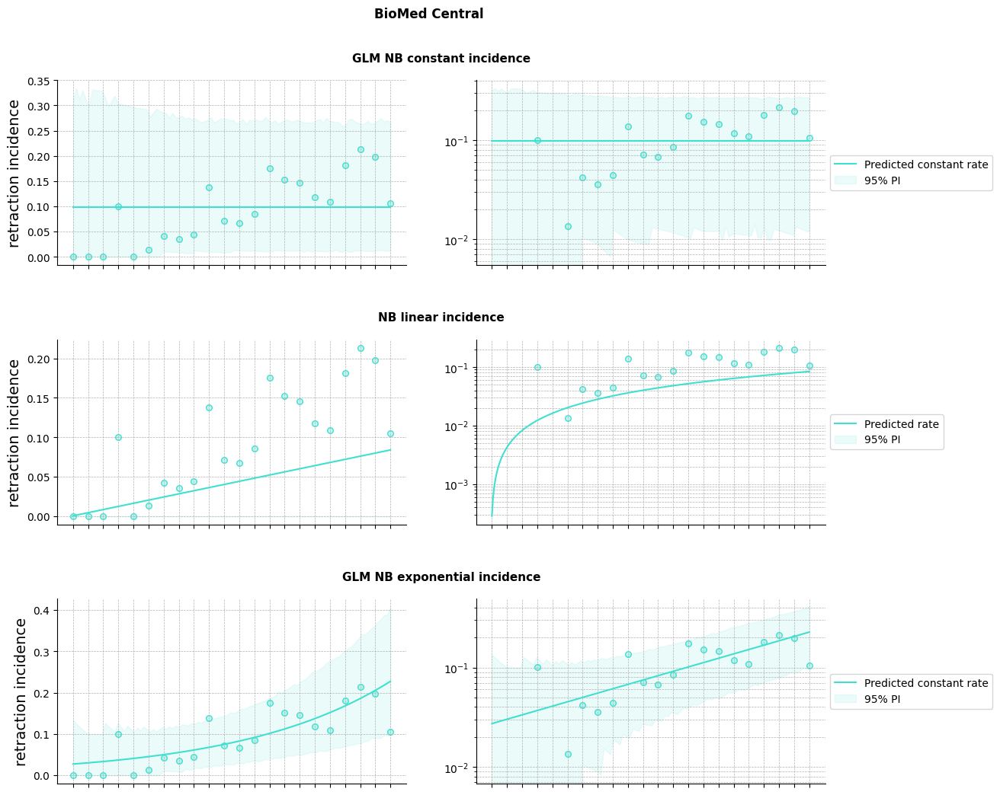

  5%|▌         | 1/20 [00:00<00:16,  1.13it/s]

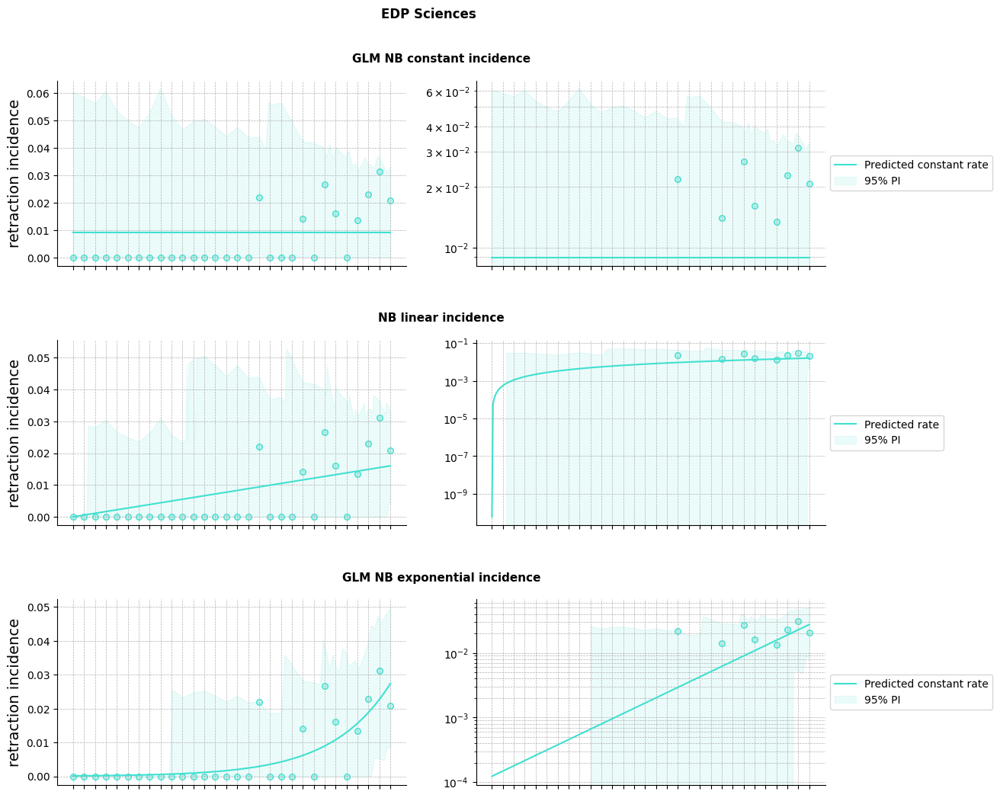

 10%|█         | 2/20 [00:01<00:15,  1.16it/s]

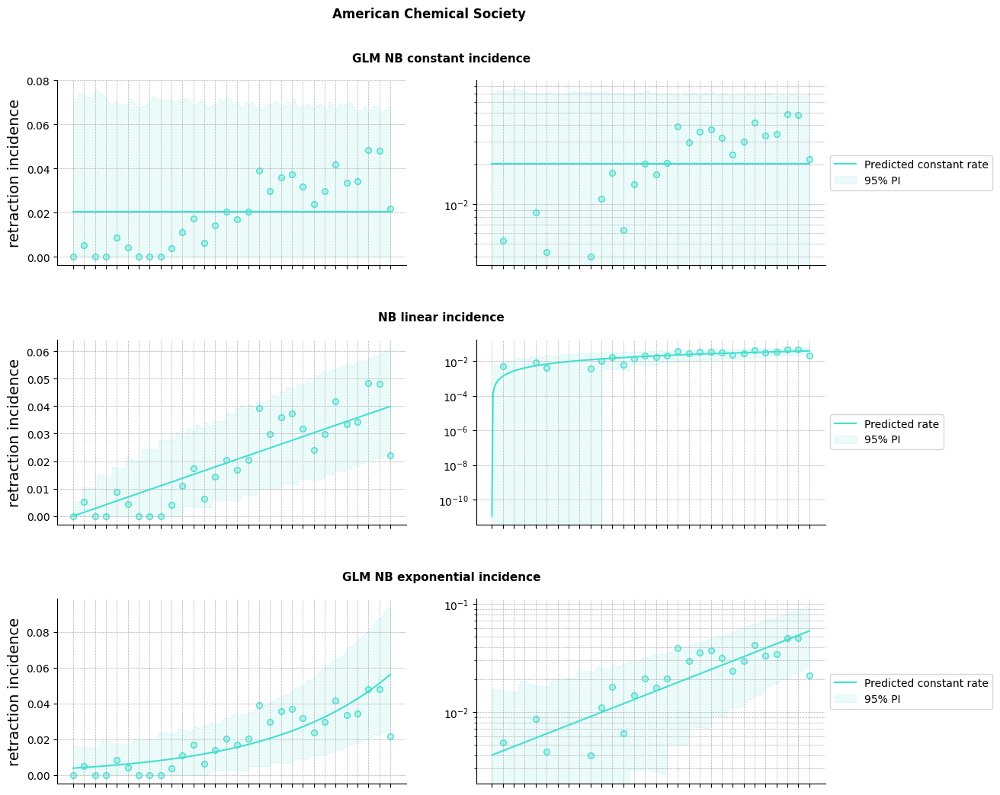

 15%|█▌        | 3/20 [00:02<00:15,  1.07it/s]

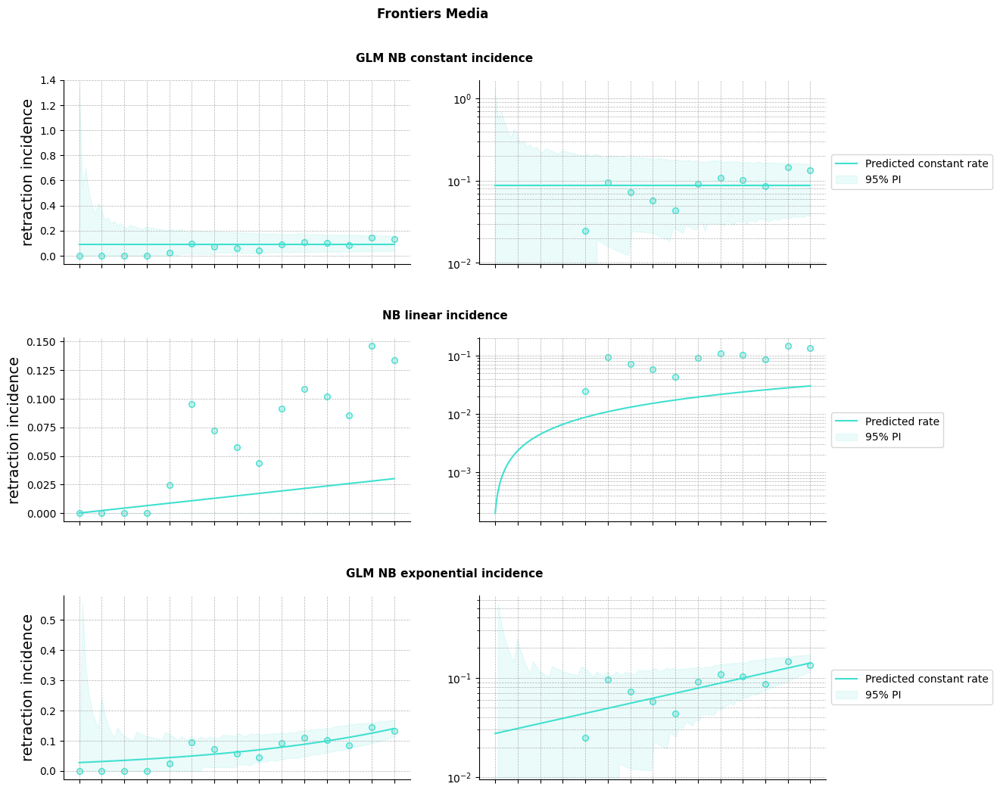

 20%|██        | 4/20 [00:03<00:13,  1.15it/s]

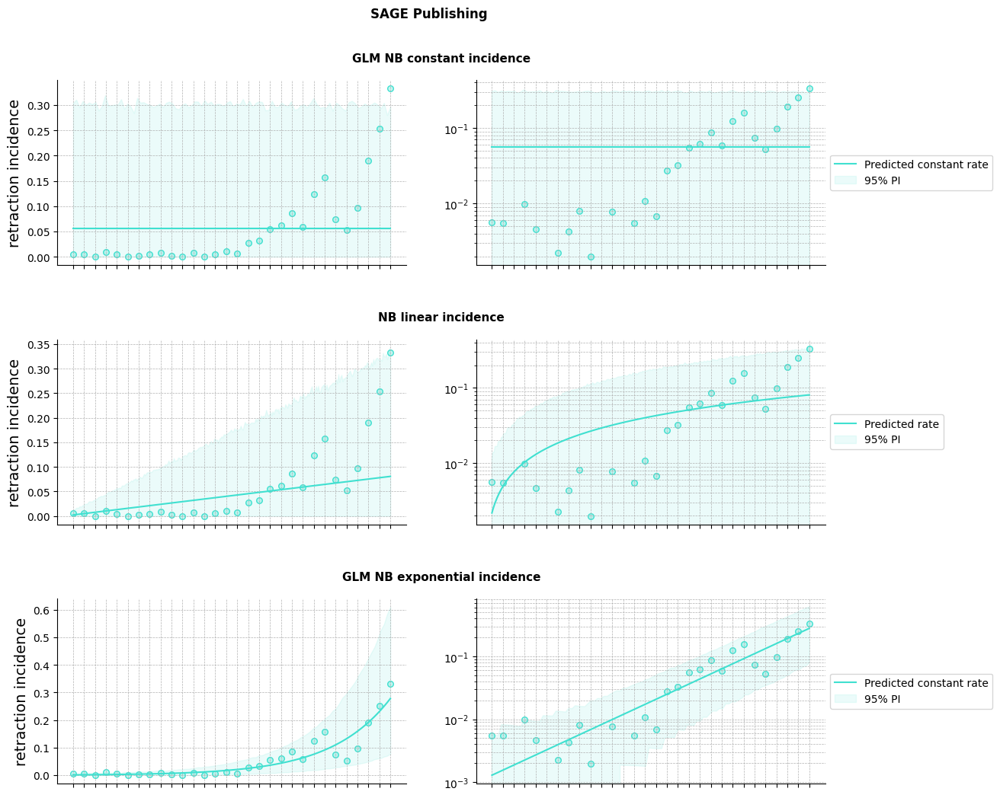

 25%|██▌       | 5/20 [00:04<00:14,  1.04it/s]

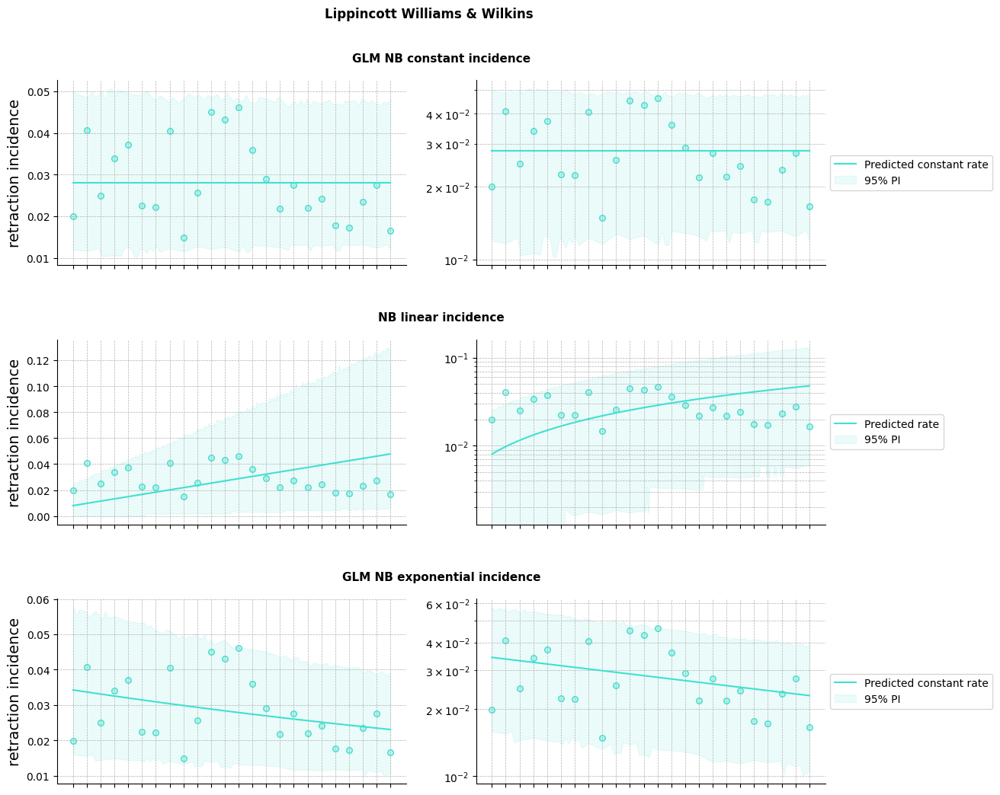

 30%|███       | 6/20 [00:05<00:13,  1.04it/s]

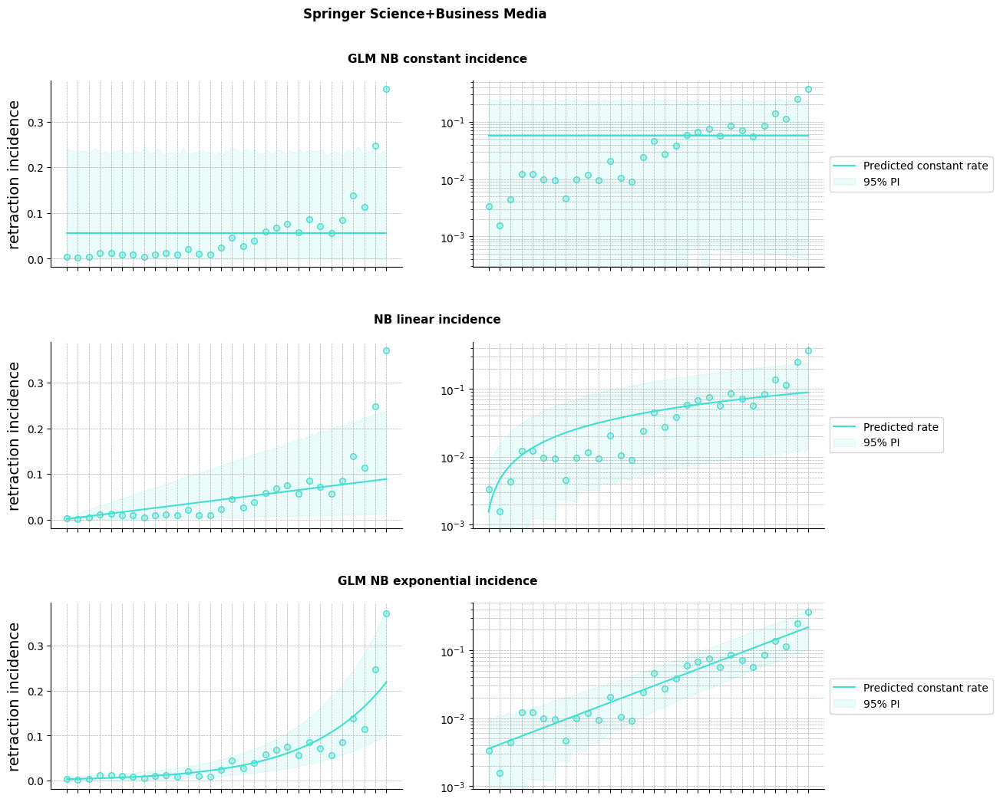

 35%|███▌      | 7/20 [00:06<00:12,  1.02it/s]

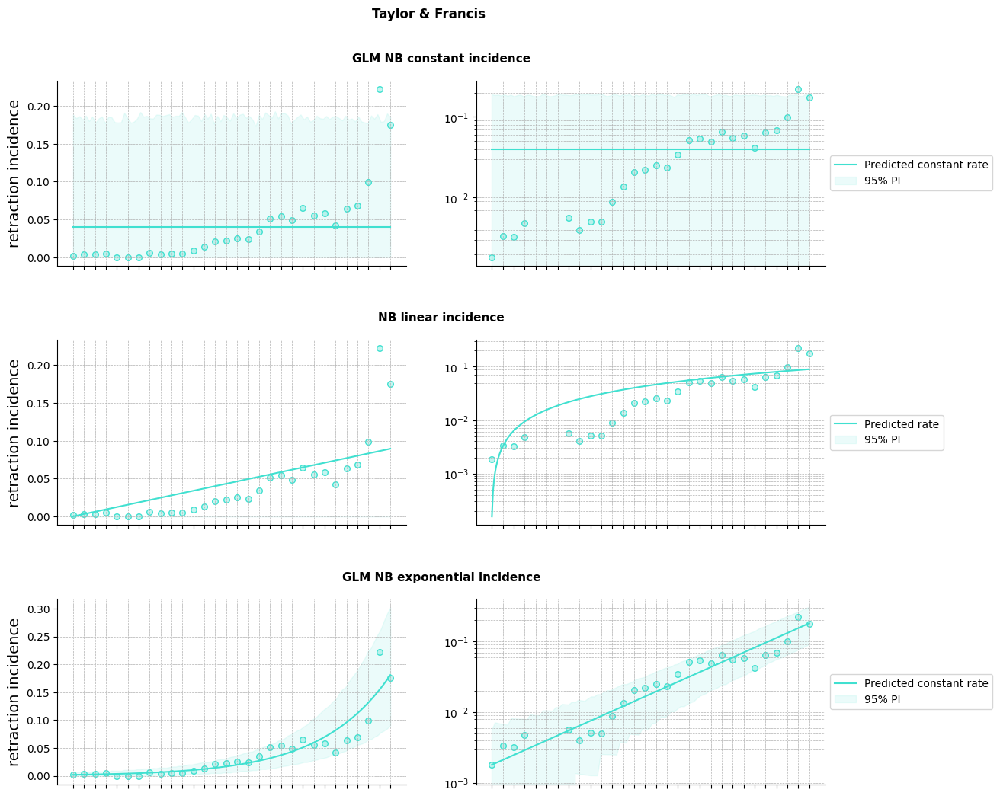

 40%|████      | 8/20 [00:07<00:11,  1.05it/s]

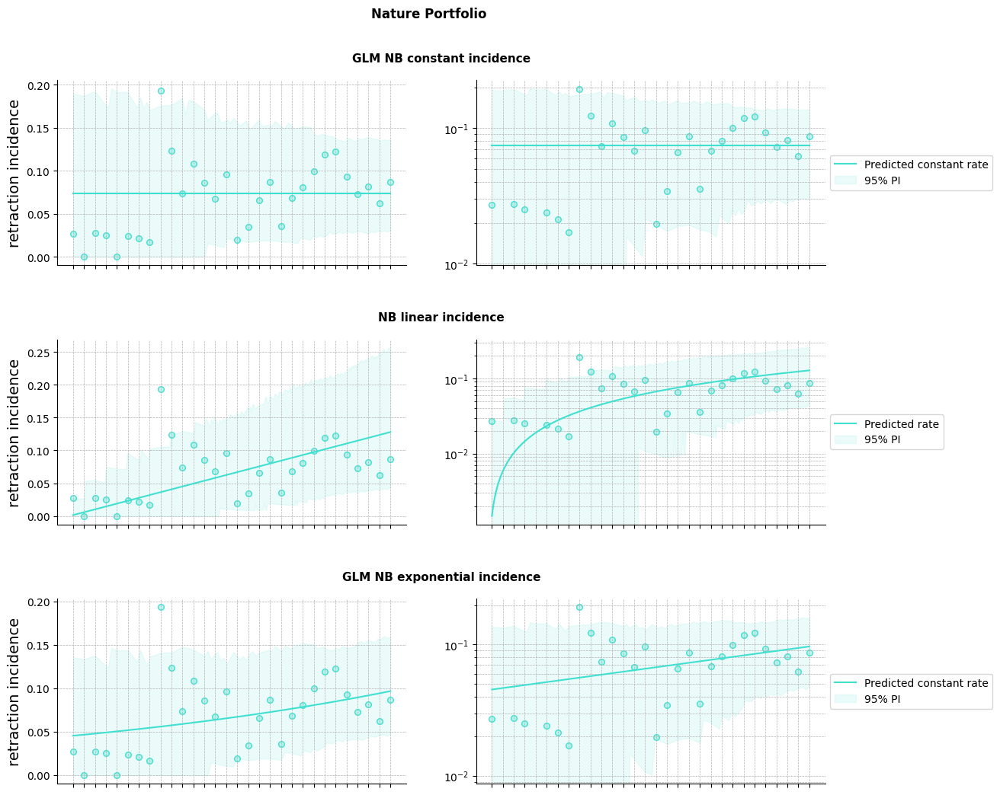

 45%|████▌     | 9/20 [00:08<00:10,  1.05it/s]

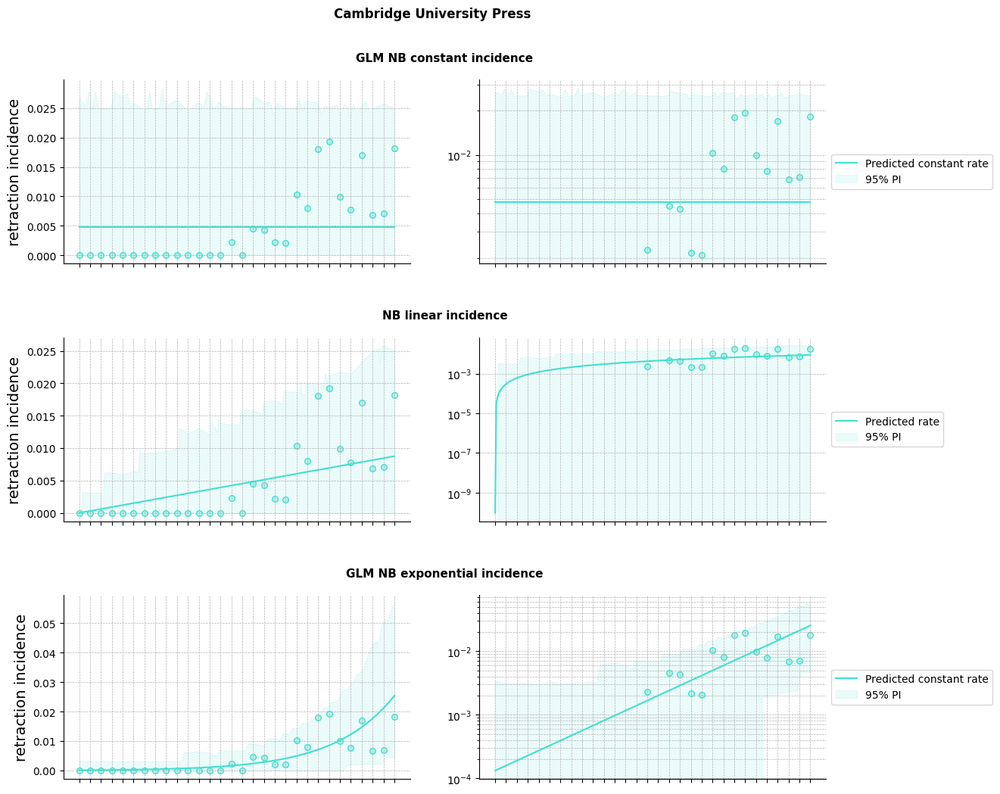

 50%|█████     | 10/20 [00:09<00:09,  1.04it/s]

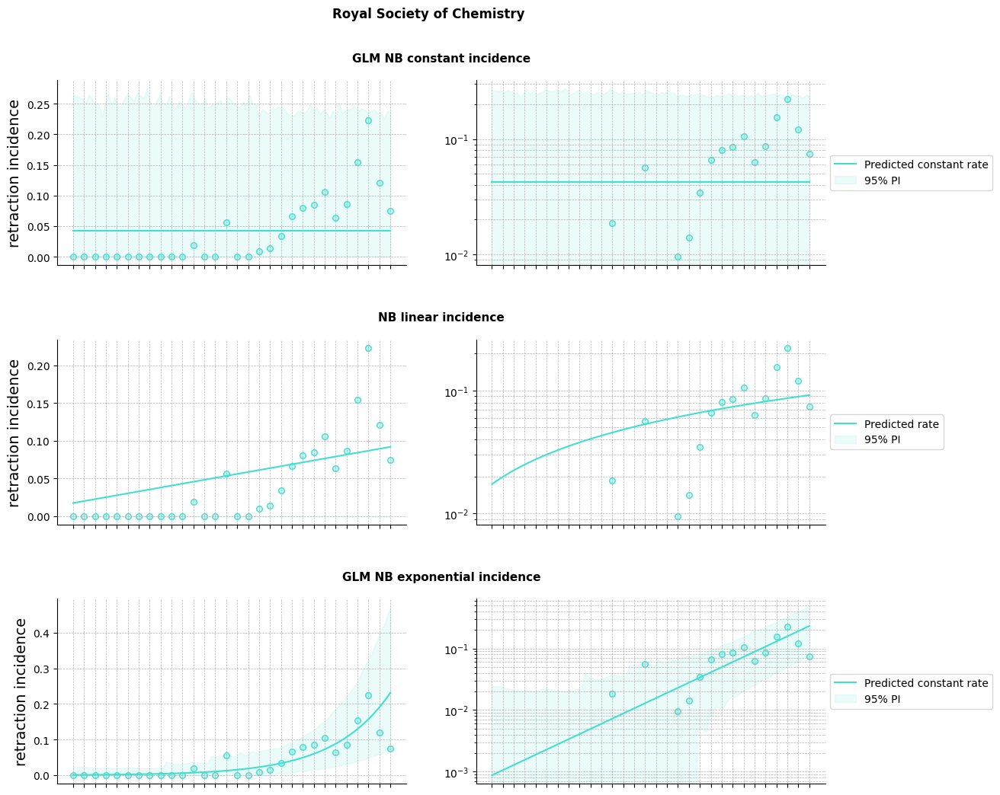

 55%|█████▌    | 11/20 [00:10<00:08,  1.10it/s]

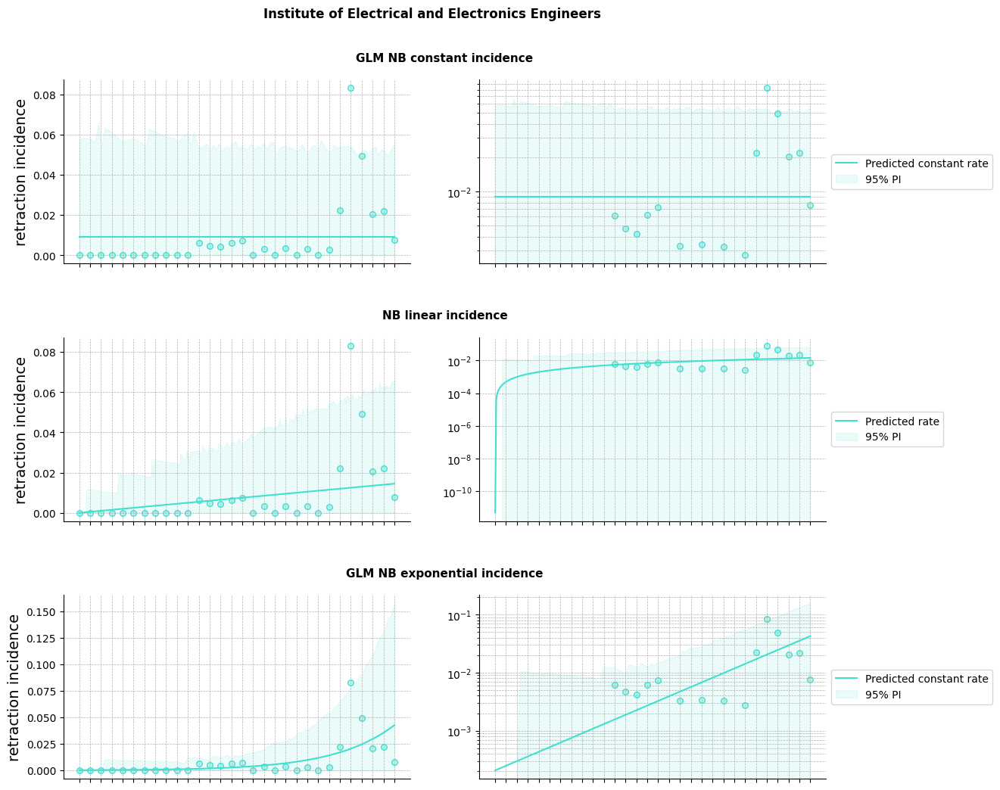

 60%|██████    | 12/20 [00:11<00:07,  1.06it/s]

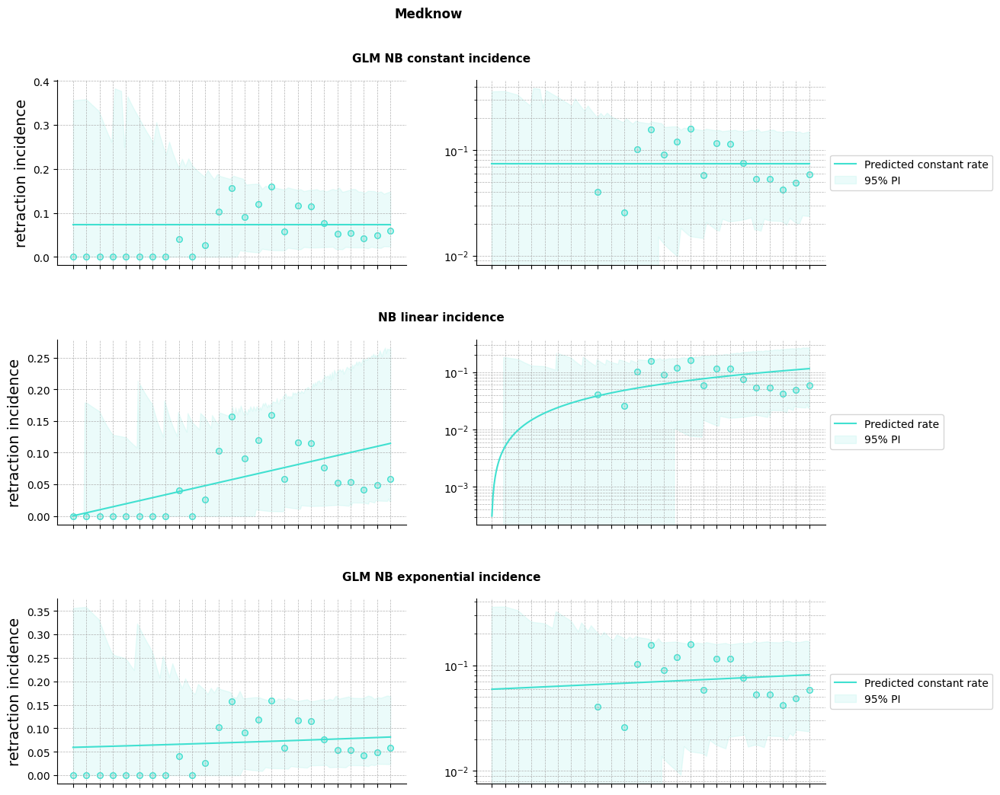

 65%|██████▌   | 13/20 [00:12<00:06,  1.07it/s]

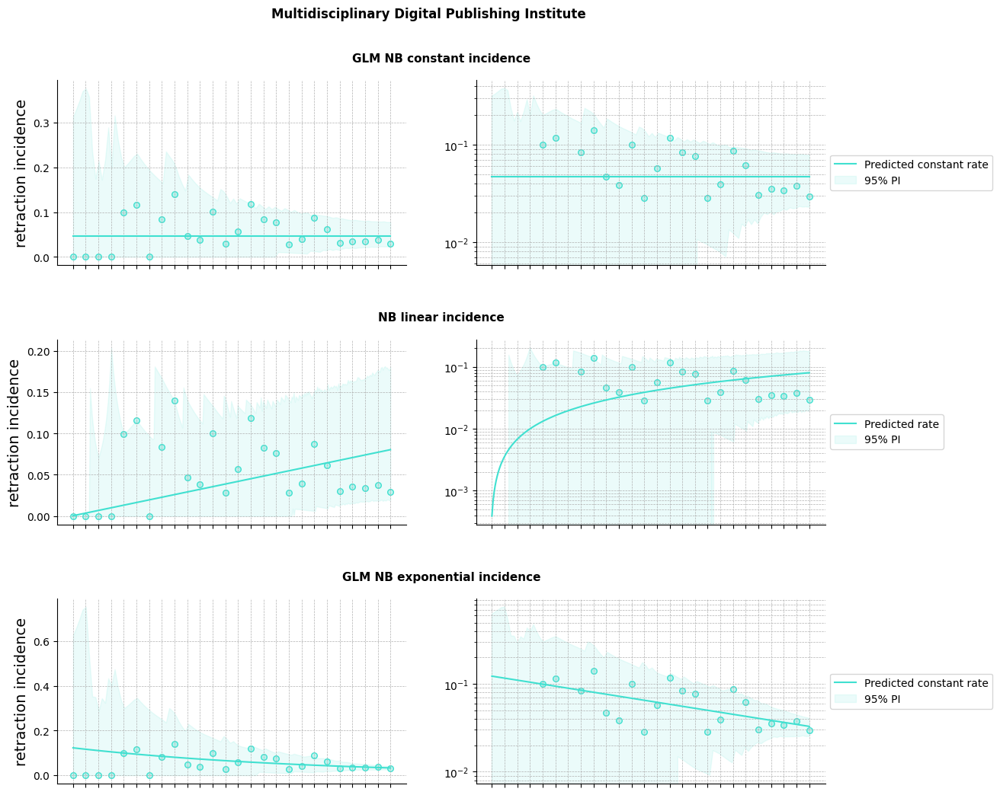

 70%|███████   | 14/20 [00:13<00:05,  1.06it/s]

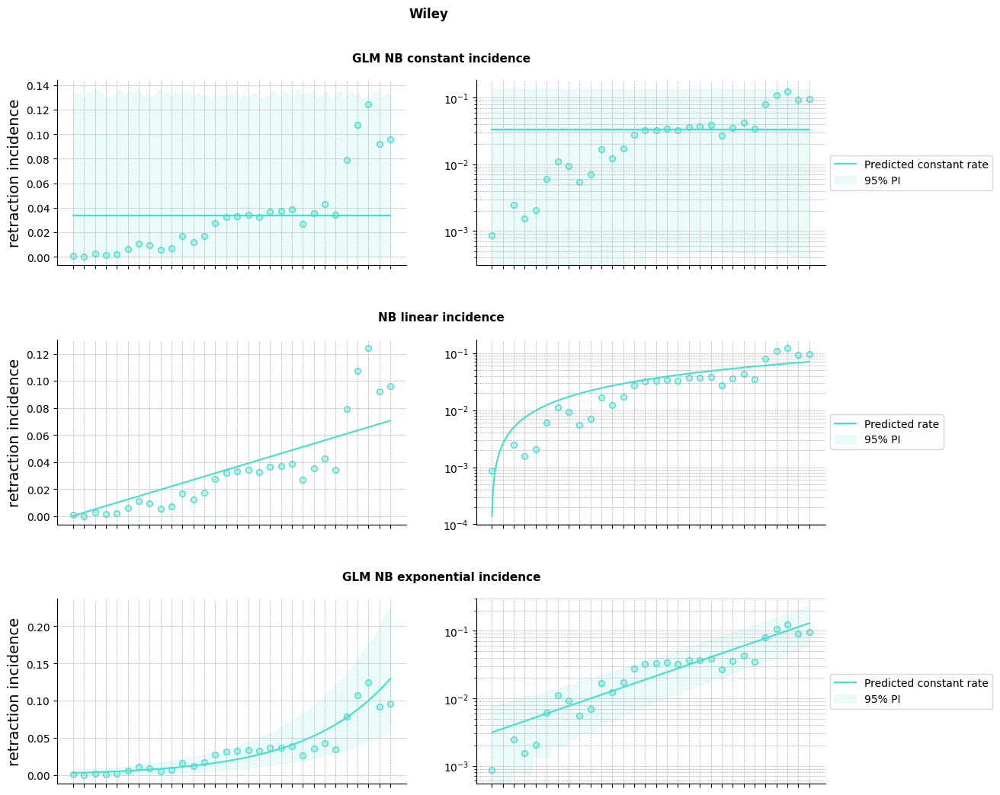

 75%|███████▌  | 15/20 [00:14<00:04,  1.07it/s]

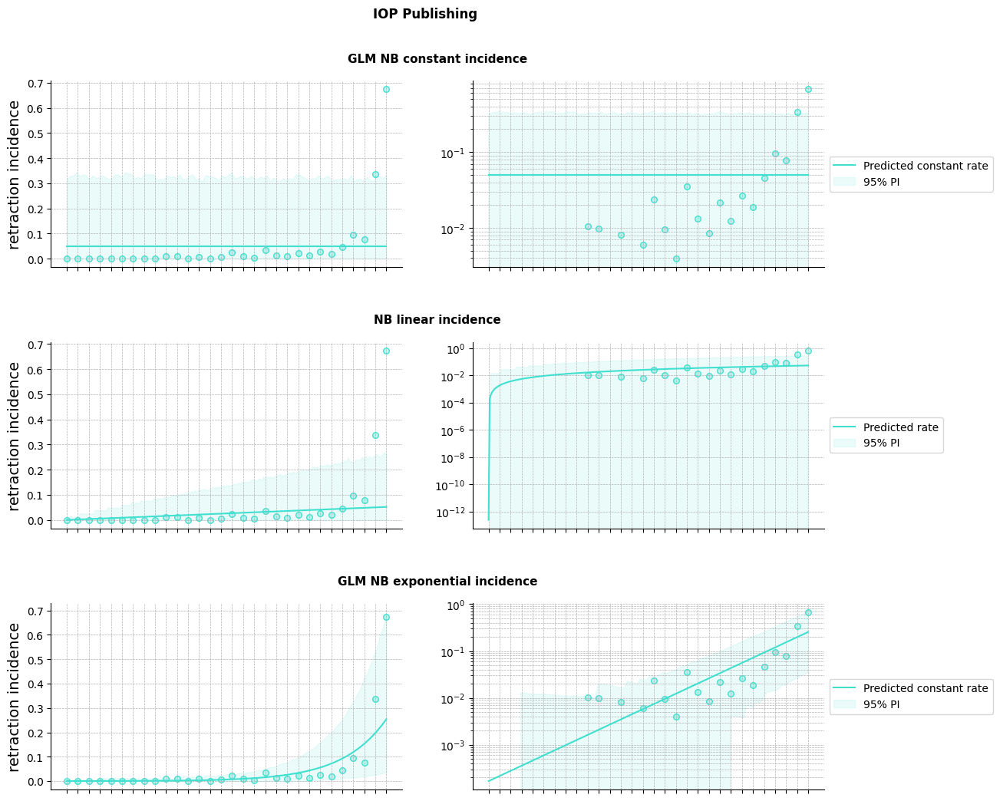

 80%|████████  | 16/20 [00:15<00:03,  1.04it/s]

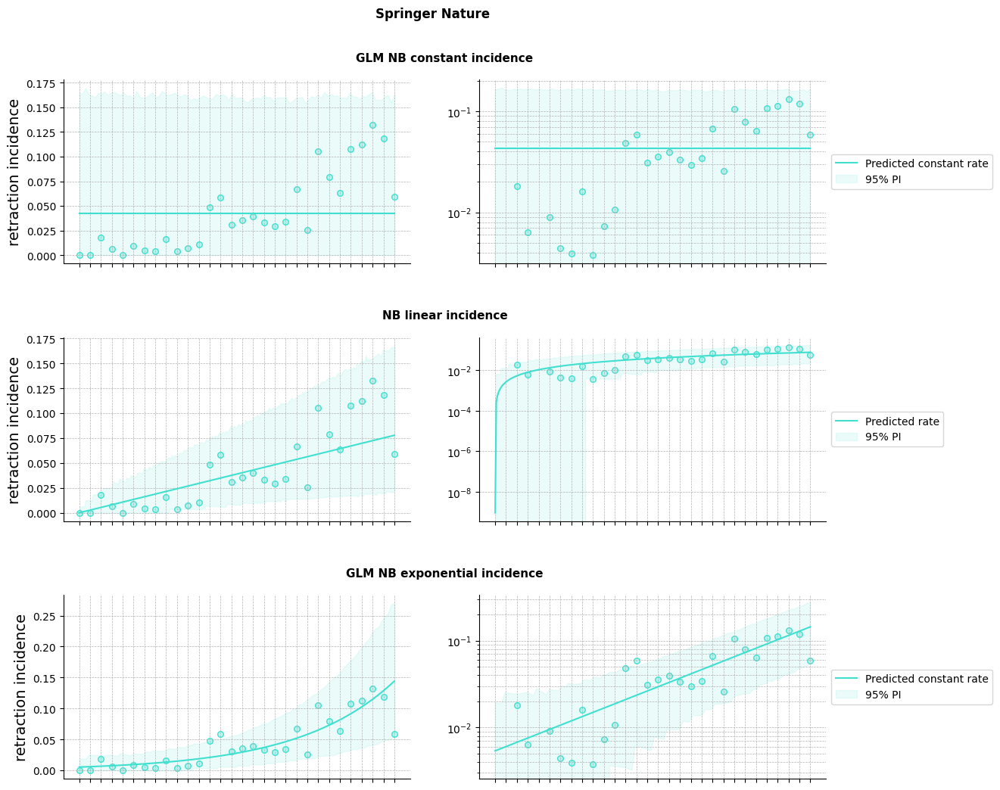

 85%|████████▌ | 17/20 [00:16<00:02,  1.02it/s]

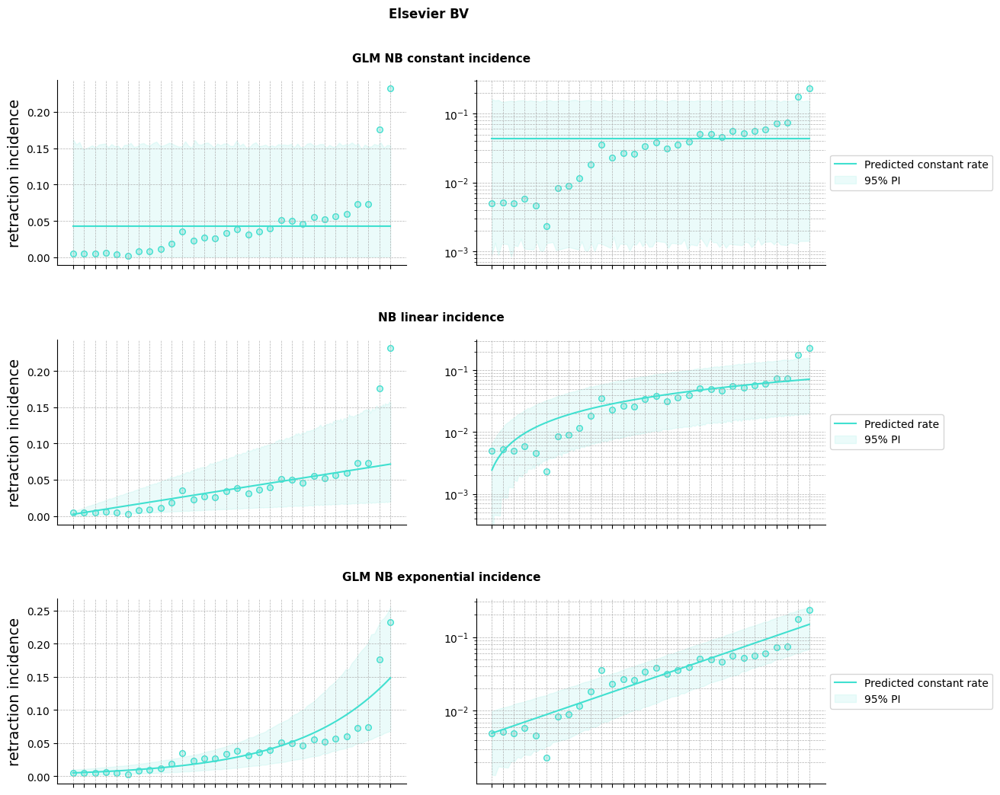

 90%|█████████ | 18/20 [00:17<00:01,  1.02it/s]

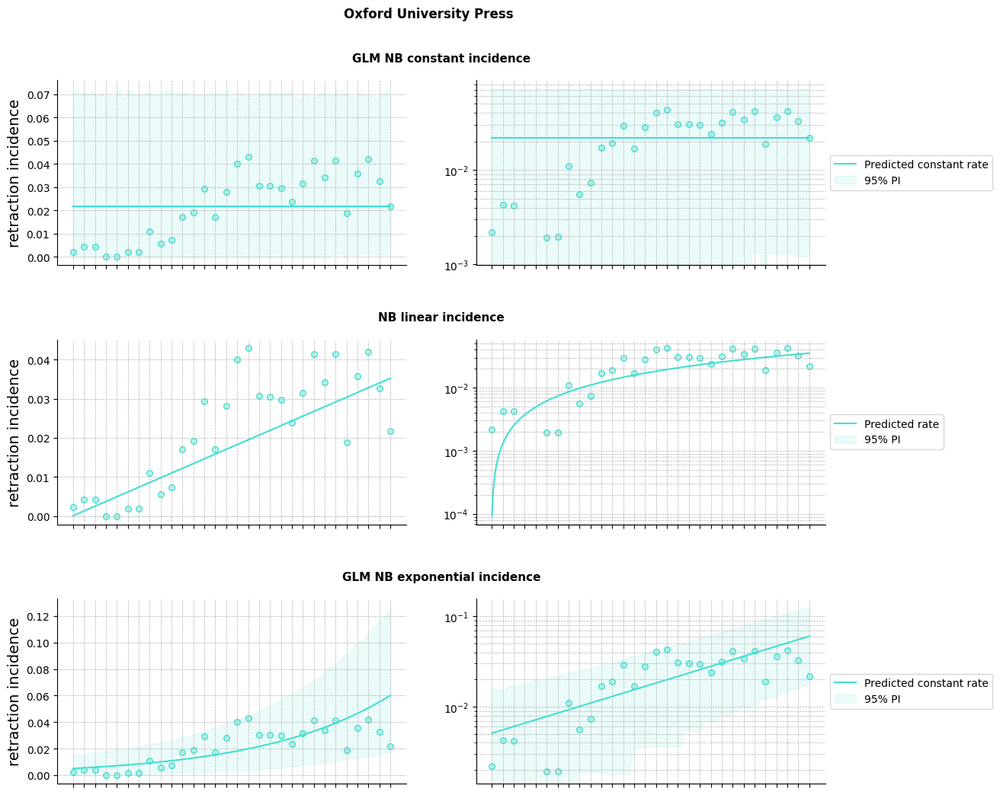

 95%|█████████▌| 19/20 [00:17<00:00,  1.06it/s]

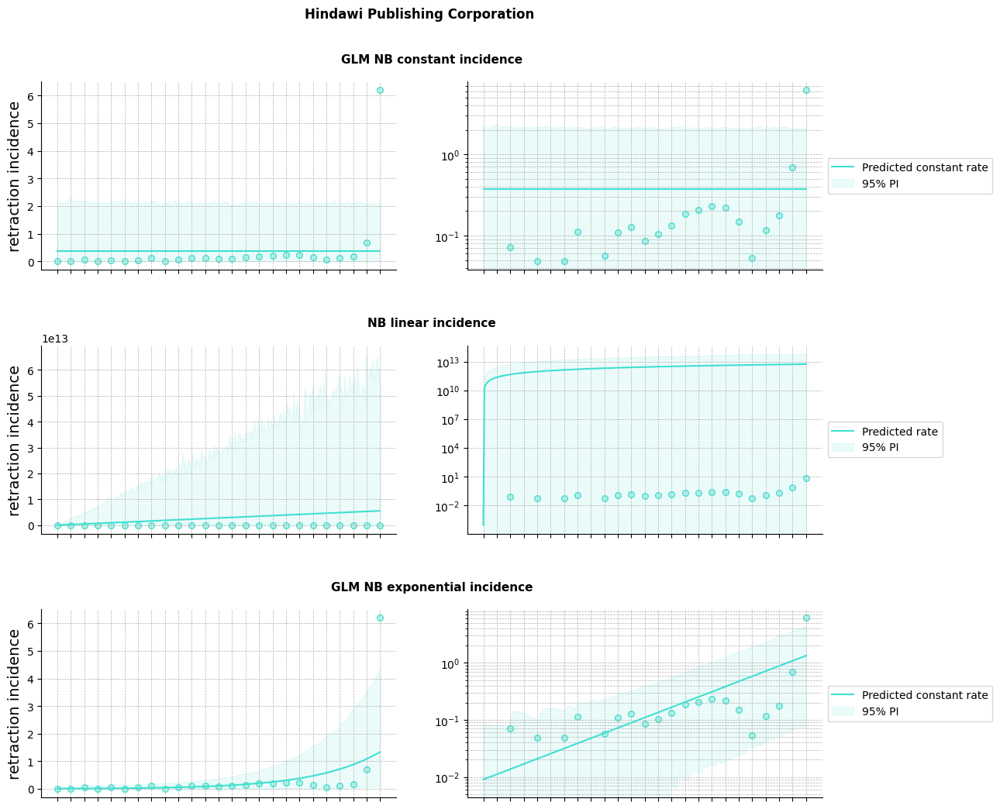

100%|██████████| 20/20 [00:18<00:00,  1.06it/s]


In [51]:
SCALE = 1e2
df = works_retracted_count_bypublisher
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
title = 'retraction incidence works'
results_publishers_df = pd.DataFrame()
for i in tqdm(list(publisher_id_selected)):
    df_i = df[df.publisher_id==i]
    df_i = df_i[df_i.year >= start_year_dict[i]]
    results_df = try_all_fit(SCALE,df_i,start_year,end_year,True,output_folder,title,publisher_id_name_dict,i)
    results_publishers_df = pd.concat([results_publishers_df,results_df])
results_publishers_df = results_publishers_df.rename(columns={'field_id_scaled':'publisher_id','field_name':'publisher_name'})

In [52]:
## rolling window (5 years) average and std
df = works_retracted_count_bypublisher.copy()
start_year=2000
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
SCALE = 1e2
df['retracted_incidence'] = (df['retracted'] / df['total'])*SCALE
start_year=1992
end_year=2021
df = df[(df.year >= start_year) & (df.year <= end_year)]
window_size = 5
df_rolling = retracted_rolling_average(df,window_size,'publisher_id')
df_rolling

,publisher_id,year,mean,var
0,4310310987,2004,0.087811,0.002276
1,4310310987,2005,0.077276,0.002476
2,4310310987,2006,0.061700,0.002227
3,4310310987,2007,0.081733,0.001360
4,4310310987,2008,0.070768,0.001803
...,...,...,...,...
354,4310320990,2017,0.054059,0.000021
355,4310320990,2018,0.059383,0.000052
356,4310320990,2019,0.063009,0.000076
357,4310320990,2020,0.087792,0.001995


In [53]:
df = results_publishers_df
df = df[['start year','end year','publisher_name','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['publisher_name', 'model_order']).drop(columns='model_order')
df.head()

,start year,end year,publisher_name,model,ΔBIC,ΔBIC_weighted
0,1992,2021,American Chemical Society,constant,34.506314,3.214024e-08
0,1992,2021,American Chemical Society,linear,NaN,NaN
0,1992,2021,American Chemical Society,exponential,0.000000,1.000000e+00
0,1992,2021,BioMed Central,constant,19.002398,7.475656e-05
0,1992,2021,BioMed Central,linear,NaN,NaN


In [ ]:
start_year = 1992
end_year = 2021
alpha = 1
model_func_name = {'GLM NB exponential incidence'}
publisher_set = set((results_publishers_df[results_publishers_df.model.isin(model_func_name)].query('best_model==1').publisher_name))
publisher_set = publisher_set - {'Lippincott Williams & Wilkins','Multidisciplinary Digital Publishing Institute','Nature Portfolio'}
df0 = results_publishers_df[results_publishers_df.publisher_name.isin(publisher_set)]
sorted_publishers = list(df0['publisher_id'].unique())
sorted_publishers.sort()
df1 = df0[df0.best_model==1][['publisher_id','publisher_name','alpha', 'b', 'p value b','doubling time','doubling time lower','doubling time upper']]
df1 = df1.rename(columns={'b':'g','p value b':'p-value'})
df2 = pd.DataFrame()
for publisher in sorted_publishers:
    temp = pd.read_csv(os.path.join('./Retracted/Plots/plots_publishers', f'observed_df_{publisher}_{start_year}_{end_year}_{'GLM NB exponential incidence'}.csv')).rename(columns={'field_id_scaled':'publisher_id','field_name':'publisher_name'})
    temp = temp.tail(1)[['publisher_id','observed_rate']]
    df2 = pd.concat([df2,temp])
df3 = works_retracted_count_bypublisher[works_retracted_count_bypublisher.publisher_id.isin(sorted_publishers)]
df3 = df3[df3.year == end_year]
df3 = df3[['publisher_id','retracted']].reset_index(drop=True)
df = df1.merge(df2,on=['publisher_id']).merge(df3,on=['publisher_id'])
df = df[['publisher_name','alpha','g','p-value','doubling time','doubling time lower','doubling time upper','observed_rate','retracted']]
df = df.sort_values(by=['publisher_name'],ascending=[True]).reset_index(drop=True).reset_index()
df = df.rename(columns={'doubling time':'doubling_time'}).drop(columns=['index','observed_rate','retracted'])
df

,publisher_name,alpha,g,p-value,doubling_time,doubling time lower,doubling time upper
0,American Chemical Society,7.140398e-02,0.091203,1.551388e-10,7.600049,5.755055,11.186196
1,BioMed Central,1.069572e-01,0.101043,5.442261e-07,6.859896,4.838521,11.782047
2,Cambridge University Press,2.043251e-01,0.181399,7.378775e-07,3.821127,2.701555,6.525343
3,EDP Sciences,1.404579e-08,0.186366,2.037615e-03,3.719287,2.233585,11.107819
4,Elsevier BV,1.049986e-01,0.117096,2.081290e-50,5.919455,5.204265,6.862530
5,Frontiers Media,6.562041e-10,0.116455,4.511736e-06,5.952061,4.035104,11.338771
6,Hindawi Publishing Corporation,7.202846e-01,0.208311,4.469926e-11,3.327463,2.530747,4.856297
7,IOP Publishing,4.630321e-01,0.252516,1.534439e-14,2.744965,2.166499,3.744859
8,Institute of Electrical and Electronics Engineers,9.660805e-01,0.183658,3.718450e-05,3.774114,2.520283,7.510623
9,Oxford University Press,1.985851e-01,0.085071,5.910754e-09,8.147869,6.023889,12.585386


In [349]:
df.sort_values(by='doubling_time')

,publisher_name,alpha,g,p-value,doubling_time,doubling time lower,doubling time upper
7,IOP Publishing,4.630321e-01,0.252516,1.534439e-14,2.744965,2.166499,3.744859
6,Hindawi Publishing Corporation,7.202846e-01,0.208311,4.469926e-11,3.327463,2.530747,4.856297
10,Royal Society of Chemistry,1.888005e-01,0.192557,2.522818e-10,3.599692,2.718040,5.327906
3,EDP Sciences,1.404579e-08,0.186366,2.037615e-03,3.719287,2.233585,11.107819
11,SAGE Publishing,2.506411e-01,0.185317,1.666017e-29,3.740337,3.164639,4.572069
8,Institute of Electrical and Electronics Engineers,9.660805e-01,0.183658,3.718450e-05,3.774114,2.520283,7.510623
2,Cambridge University Press,2.043251e-01,0.181399,7.378775e-07,3.821127,2.701555,6.525343
14,Taylor & Francis,8.887613e-02,0.158636,2.159264e-49,4.369418,3.836584,5.074124
13,Springer Science+Business Media,1.018826e-01,0.141963,2.043147e-56,4.882578,4.322222,5.609872
15,Wiley,1.063664e-01,0.128371,6.235743e-42,5.399578,4.690266,6.361654


## Jitter plot

In [55]:
rand = 0.1

In [56]:
works_retracted_count['observed_rate'] = (works_retracted_count['retracted']/works_retracted_count['total'])*SCALE
works_incidence_2021 = works_retracted_count[works_retracted_count.year==2021].observed_rate.item()

In [57]:
if  'field_name' not in set(works_retracted_count_byfield.columns):
    works_retracted_count_byfield = works_retracted_count_byfield.merge(df_topics[['field_id','field_name']],on='field_id')
works_retracted_count_byfield['observed_rate'] = (works_retracted_count_byfield['retracted']/works_retracted_count_byfield['total'])*SCALE
df1 = works_retracted_count_byfield[works_retracted_count_byfield.year==2021][['field_name','field_id_scaled','observed_rate']]
end_year = 2021
df2 = works_retracted_count_byfield
df2 = df2[df2.year == end_year]
df2 = df2[['field_id_scaled','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='field_id_scaled')
df['category'] = 'field'
df['observed_rate_norm'] = df['observed_rate']/works_incidence_2021
np.random.seed(42)
df['y_rand'] = np.random.uniform(1.5-rand, 1.5+rand, size=len(df)) #np.random.uniform(1.5, 1.5, size=len(df))
#Add horizontal jitter instead of vertical (since now observed_rate is on x-axis)
df['x'] = df['observed_rate_norm']
df['y'] = df['y_rand']
df['size'] = np.log10(df['retracted'])
df['label'] = df['field_name']
#df['size'] = df['retracted']
df = df.sort_values(by='field_name').reset_index(drop=True)
df_fields = df[['x','y','size','category','label']]

In [58]:
works_retracted_count_bycountry['observed_rate'] = (works_retracted_count_bycountry['retracted']/works_retracted_count_bycountry['total'])*SCALE
df1 = works_retracted_count_bycountry[works_retracted_count_bycountry.year==2021][['country_name','country_code','observed_rate']]

end_year = 2021
df2 = works_retracted_count_bycountry[works_retracted_count_bycountry.country_code.isin(country_selected_set)]
df2 = df2[df2.year == end_year]
df2 = df2[['country_code','retracted']].reset_index(drop=True)
df = df1.merge(df2,on='country_code')
df['category'] = 'country'
df['observed_rate_norm'] = df['observed_rate']/works_incidence_2021
np.random.seed(42)
df['y_rand'] = np.random.uniform(1.0-rand, 1.0+rand, size=len(df)) #np.random.uniform(0.5, 0.5, size=len(df)) #+0.025
#Add horizontal jitter instead of vertical (since now observed_rate is on x-axis)
df['x'] = df['observed_rate_norm']
df['y'] = df['y_rand']
df['size'] = np.log10(df['retracted']+1)
df['label'] = df['country_name']
#df['size'] = df['retracted']
df = df.sort_values(by='country_name').reset_index(drop=True)
df_countrys = df[['x','y','size','category','label']]

In [59]:
works_retracted_count_bypublisher['observed_rate'] = (works_retracted_count_bypublisher['retracted']/works_retracted_count_bypublisher['total'])*SCALE
df1 = works_retracted_count_bypublisher[works_retracted_count_bypublisher.year==2021][['publisher_name','publisher_id','observed_rate']]

end_year = 2021
df2 = works_retracted_count_bypublisher[works_retracted_count_bypublisher.publisher_id.isin(publisher_id_selected)]
df2 = df2[df2.year == end_year]
df2 = df2[['publisher_id','retracted']].reset_index(drop=True)

df = df1.merge(df2,on='publisher_id')
df['category'] = 'publisher'

df['observed_rate_norm'] = df['observed_rate']/works_incidence_2021
np.random.seed(42)
df['y_rand'] = np.random.uniform(0.5-rand, 0.5+rand, size=len(df)) #np.random.uniform(1, 1, size=len(df))

#Add horizontal jitter instead of vertical (since now observed_rate is on x-axis)
df['x'] = df['observed_rate_norm']
df['y'] = df['y_rand']
df['size'] = np.log10(df['retracted'])
df['label'] = df['publisher_name'].apply(lambda x:x.replace('&','\\&'))
#df['size'] = df['retracted']
df = df.sort_values(by='publisher_name').reset_index(drop=True)
df['publisher_name'] = df['publisher_name'].str.replace('&', '', regex=False)
df['publisher_name'] = df['publisher_name'].str.replace('+', '', regex=False)
df_publishers = df[['x','y','size','category','label']]

In [60]:
df_concat = pd.concat([df_fields,df_countrys])
df_concat = pd.concat([df_concat,df_publishers])
df_concat = df_concat.drop(columns='y')
df_concat = df_concat.rename(columns={'x':'observed_rate_norm','size':'retracted'})
display(df_concat.head())

,observed_rate_norm,retracted,category,label
0,0.612738,2.523313,field,Agricultural and Biological Sciences
1,0.612738,2.523313,field,Agricultural and Biological Sciences
2,0.612738,2.523313,field,Agricultural and Biological Sciences
3,0.612738,2.523313,field,Agricultural and Biological Sciences
4,0.612738,2.523313,field,Agricultural and Biological Sciences


## Authors

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_authorships_retracted_count` AS

  WITH works_authorships_retracted_distinct AS (
    SELECT DISTINCT
      publication_year,
      is_retracted,
      author_id
    FROM
      `project_name.dataset_name.works_authorships`
    WHERE
      publication_year BETWEEN '1992-01-01' AND '2021-01-01'
  )

  SELECT
    publication_year,
    COUNT(DISTINCT author_id) AS total_authors,
    SUM(CAST(is_retracted AS INT64)) AS retracted_authors
  FROM
    works_authorships_retracted_distinct
  GROUP BY
    publication_year
  ORDER BY
    publication_year;
"""
##output info
new_table_name = "works_authorships_retracted_count"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)


In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
output_folder = './Retracted/Plots/plots_authors'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

In [ ]:
works_authorships_retracted_count = pd.read_csv(f'./Retracted/Data/works_authorships_retracted_count.csv.gz', compression='gzip').rename(columns={'publication_year':'year'})
works_authorships_retracted_count['year'] = works_authorships_retracted_count['year'].str[:4].astype(int)
works_authorships_retracted_count = works_authorships_retracted_count.rename(columns={'total_authors':'total','retracted_authors':'retracted'})
works_authorships_retracted_count = works_authorships_retracted_count[(works_authorships_retracted_count.year>=1980) & (works_authorships_retracted_count.year<=2024)].reset_index(drop=True)

  0%|          | 0/4 [00:00<?, ?it/s]

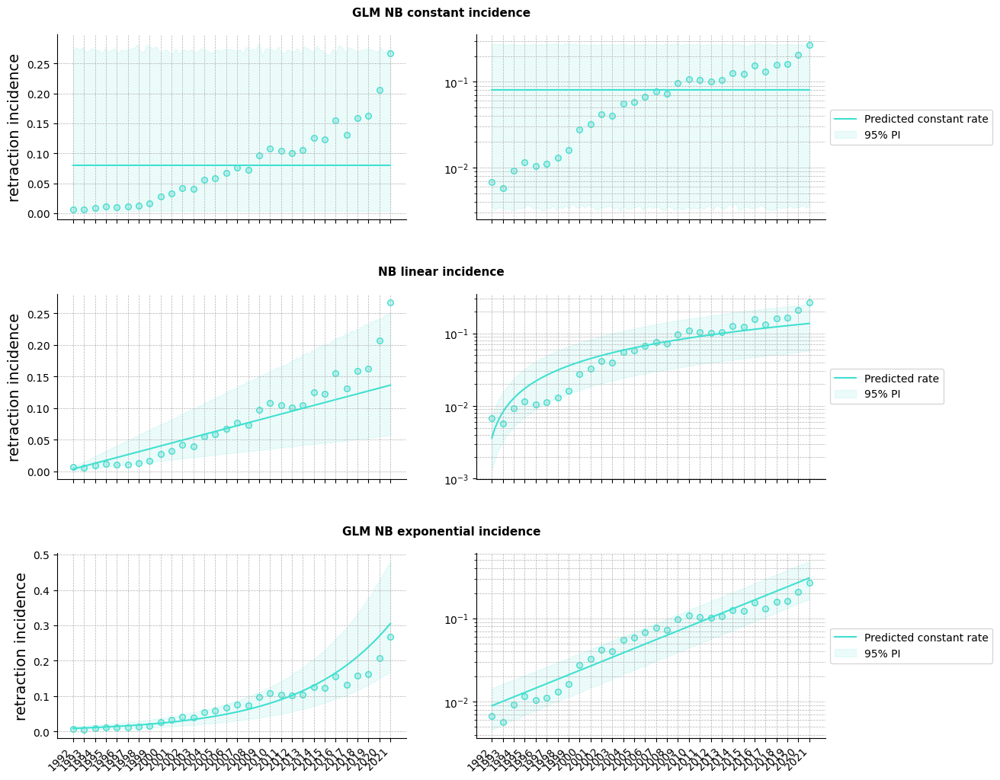

 25%|██▌       | 1/4 [00:00<00:02,  1.07it/s]

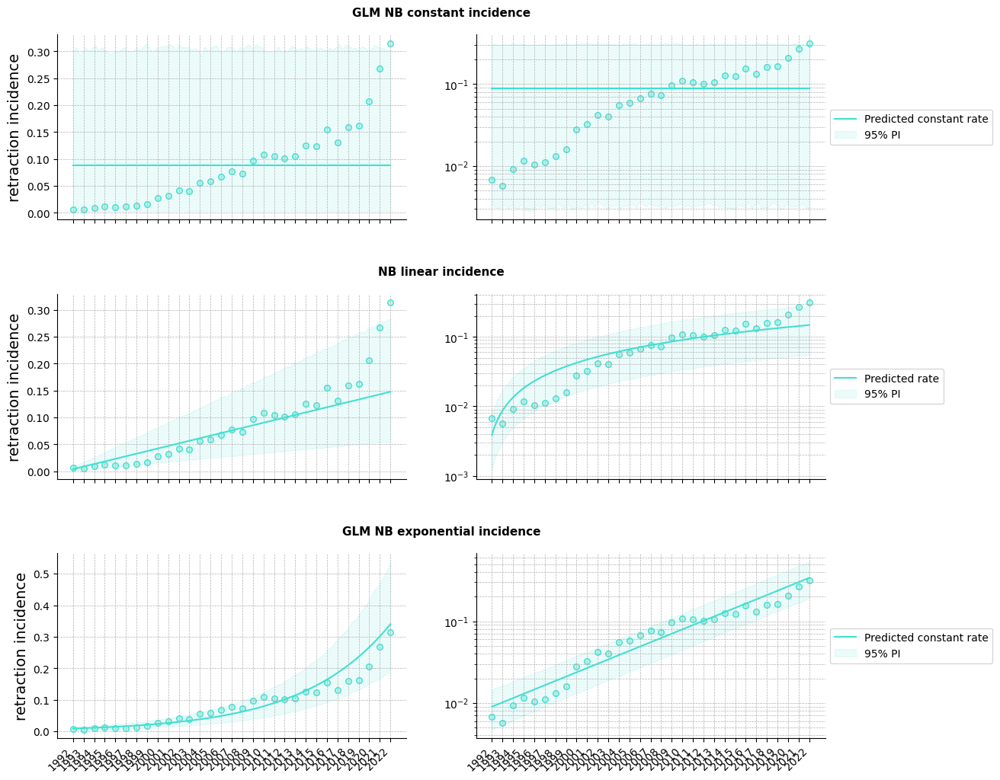

 50%|█████     | 2/4 [00:01<00:01,  1.08it/s]

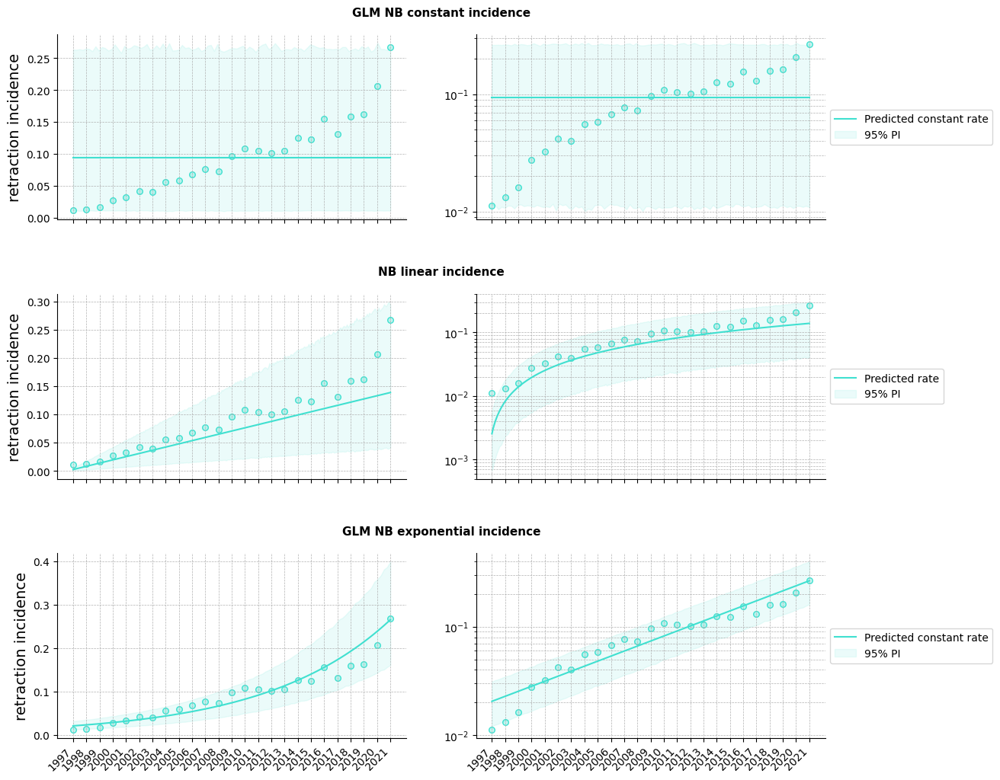

 75%|███████▌  | 3/4 [00:02<00:00,  1.10it/s]

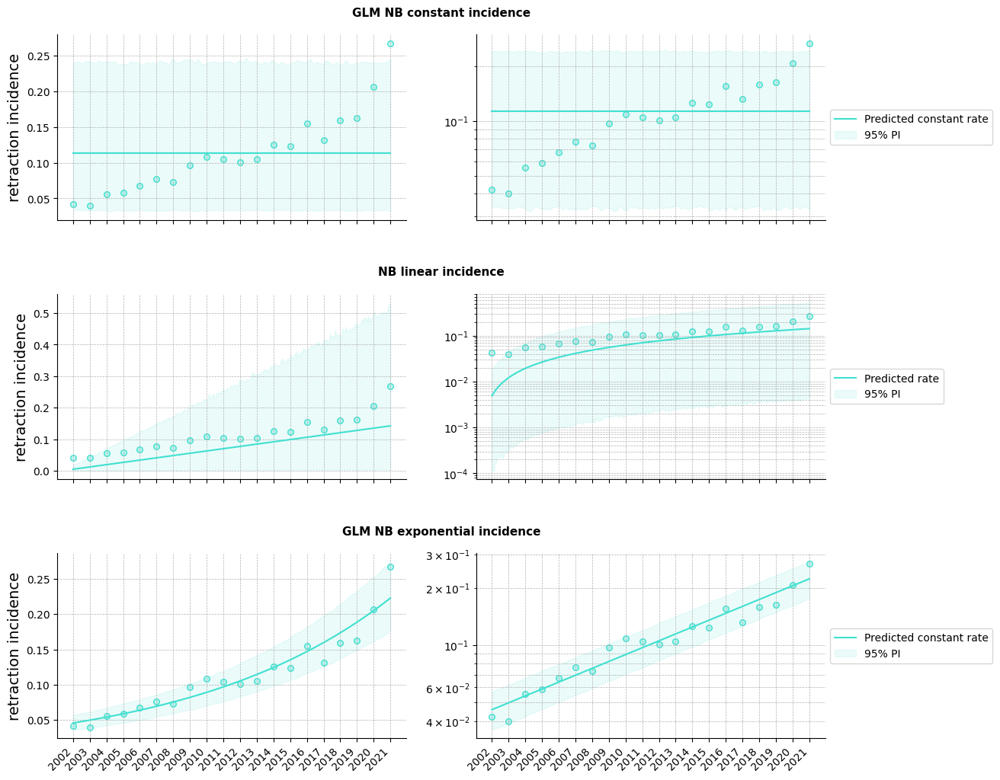

100%|██████████| 4/4 [00:03<00:00,  1.06it/s]


In [156]:
ranges_list = [(1992,2021),(1992,2022),(1997,2021),(2002,2021)]
SCALE = 1e2
title = 'retraction incidence authors'
results_authors_ranges_df = pd.DataFrame()
for (start_year,end_year) in tqdm(ranges_list):
    df = works_authorships_retracted_count
    df = df[(df.year >= start_year) & (df.year <= end_year)]
    results_df_ = try_all_fit(SCALE,df,start_year,end_year,True,output_folder,title)
    results_authors_ranges_df = pd.concat([results_authors_ranges_df,results_df_])
results_authors_ranges_df['range'] = results_authors_ranges_df.apply(lambda x : (x['start year'], x['end year']), axis=1)

In [157]:
df = results_authors_ranges_df
df = df[['range','model','ΔBIC','ΔBIC_weighted']].drop_duplicates()
df['model'] = df['model'].map(model_name_replace_dict)
df['model_order'] = df['model'].map(model_order)
df = df.sort_values(by=['range', 'model_order']).drop(columns='model_order')
df

,range,model,ΔBIC,ΔBIC_weighted
0,"(1992, 2021)",constant,77.475812,1.500835e-17
0,"(1992, 2021)",linear,21.733845,1.907863e-05
0,"(1992, 2021)",exponential,0.000000,9.999809e-01
0,"(1992, 2022)",constant,83.338646,8.002811e-19
0,"(1992, 2022)",linear,27.683980,9.738671e-07
0,"(1992, 2022)",exponential,0.000000,9.999990e-01
0,"(1997, 2021)",constant,56.231633,6.158231e-13
0,"(1997, 2021)",exponential,0.000000,1.000000e+00
0,"(2002, 2021)",constant,55.451318,9.097024e-13
0,"(2002, 2021)",linear,88.580559,5.820711e-20


In [158]:
df = results_authors_ranges_df[results_authors_ranges_df.best_model==1][['range','alpha','b','p value b','doubling time','doubling time lower','doubling time upper']]
df = df.rename(columns={'b':'g','p value b':'p-value'})
df

,range,alpha,g,p-value,doubling time,doubling time lower,doubling time upper
0,"(1992, 2021)",0.068476,0.121777,1.725046e-84,5.691953,5.149472,6.362191
0,"(1992, 2022)",0.066289,0.121079,2.307843e-96,5.724766,5.212205,6.349131
0,"(1997, 2021)",0.053068,0.106707,1.674816e-52,6.495781,5.718108,7.518279
0,"(2002, 2021)",0.012790,0.083148,6.321389e-76,8.336303,7.480411,9.413357


## Retraction lag

Download Retraction Watch Database from https://gitlab.com/crossref/retraction-watch-data 

In [ ]:
watch_data = pd.read_csv(f'./Retracted/Data/retraction_watch.csv')

watch_data = watch_data[['OriginalPaperDate', 'RetractionDate', 'OriginalPaperPubMedID','OriginalPaperDOI', 'RetractionNature']]
watch_data['OriginalPaperDate'] = pd.to_datetime(watch_data['OriginalPaperDate'], errors='coerce')
watch_data.replace('unavailable', np.nan, inplace=True)
watch_data['RetractionDate'] = pd.to_datetime(watch_data['RetractionDate'], errors='coerce')
watch_data.replace('unavailable', np.nan, inplace=True)

watch_data1 = watch_data[['OriginalPaperDate', 'RetractionDate','OriginalPaperDOI', 'RetractionNature']].dropna().rename(columns={'OriginalPaperDOI':'doi'})
watch_data1.replace('unavailable', np.nan, inplace=True)
watch_data1['doi'] = watch_data1['doi'].astype(str)
watch_data1['doi'] = 'https://doi.org/' + watch_data1['doi']
watch_data2 = watch_data[['OriginalPaperDate','OriginalPaperPubMedID', 'RetractionNature']].dropna().rename(columns={'OriginalPaperPubMedID':'doi'})
watch_data2.replace('unavailable', np.nan, inplace=True)
watch_data2 = watch_data2[watch_data2.doi!=0]
watch_data2['doi'] = watch_data2['doi'].astype(int).astype(str)
watch_data2['doi'] = 'https://pubmed.ncbi.nlm.nih.gov/' + watch_data2['doi'] + '/'
watch_data = pd.concat([watch_data1,watch_data2]).sort_values(by='OriginalPaperDate').reset_index(drop=True)
watch_data['doi'] = watch_data['doi'].str.lower()

In [ ]:
sql = """
  CREATE TABLE `project_name.dataset_name.works_info_retracted_true` AS
  SELECT
      work_id,
      doi,
      publication_year,
    FROM
      `project_name.dataset_name.works_info`
    WHERE 
      is_retracted = 1 AND
      publication_year BETWEEN '1992-01-01' AND '2025-01-01';
"""
##output info
new_table_name = "works_authorships_retracted_count"
target_table_id = "{proj}.{dtst}.{fname}".format(proj = project_name, dtst = dataset_name, fname=new_table_name)
ji = send_query_partition(dataset_name,new_table_name,sql,project_name,path_credential)

In [ ]:
destination_uri = "gs://{}/{}/{}".format(bucket_name,dataset_name,new_table_name+".csv.gz")
r = export_bq_table(destination_uri, project_name, new_table_name, dataset_name)

In [ ]:
works_info_retracted_true = pd.read_csv(f'./Retracted/Data/works_info_retracted_true.csv.gz', compression='gzip').rename(columns={'publication_year':'year'})
works_info_retracted_true['year'] = works_info_retracted_true['year'].str[:4].astype(int)
works_info_retracted_true = works_info_retracted_true[['work_id','doi','year']]
works_info_retracted_true['doi'] = works_info_retracted_true['doi'].str.lower()
works_info_retracted_true_full = works_info_retracted_true.copy()
works_info_retracted_true = works_info_retracted_true[(works_info_retracted_true.year>=1992) & (works_info_retracted_true.year<=2021)]

df_merge = works_info_retracted_true.merge(watch_data[['doi','OriginalPaperDate', 'RetractionDate','RetractionNature']],on='doi')

print(f'{(len(df_merge) / len(works_info_retracted_true)) * 100:.2f}% retracted works matched')

93.40% retracted works matched


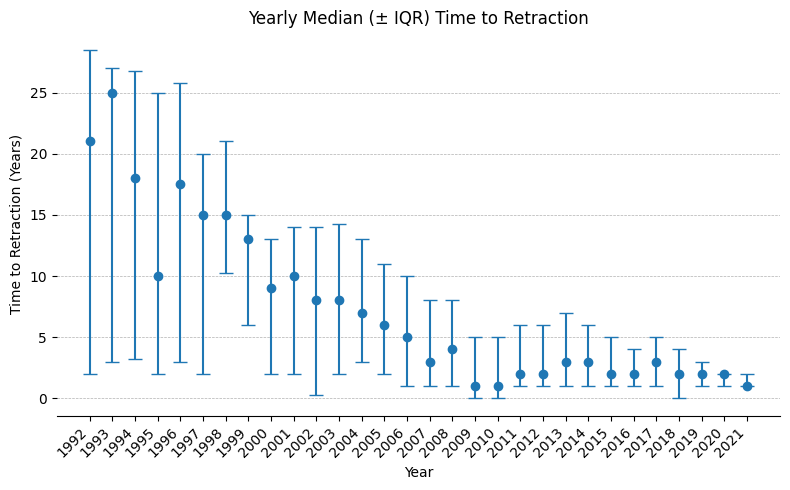

In [70]:
#time to retraction

df_time = df_merge[['year','RetractionDate']].dropna()
df_time['year_retraction'] = df_time['RetractionDate'].astype(str).str[:4].astype(int)
df_time = df_time.drop(columns='RetractionDate')
df_time['year_diff'] = df_time['year_retraction'] - df_time['year'] 

df_time_stats = df_time.groupby('year').year_diff.agg([('median', 'median'),('q25', lambda x: x.quantile(0.25)),('q75', lambda x: x.quantile(0.75))]).reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

lower_err = df_time_stats['median'] - df_time_stats['q25']
upper_err = df_time_stats['q75'] - df_time_stats['median']
yerr = [lower_err, upper_err]

ax.errorbar(
    df_time_stats['year'],           # x-axis
    df_time_stats['median'],         # y-axis
    yerr=yerr,                       # asymmetric error bars
    fmt='o',                         # marker style
    capsize=5,                       # cap length for error bars
    label='Median ± IQR'
)

ax.set_xticks(df_time_stats['year'].values)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_xlabel('Year')
ax.set_ylabel('Time to Retraction (Years)')
ax.set_title('Yearly Median (± IQR) Time to Retraction')

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, which="both", linestyle='--', linewidth=0.5)
ax.xaxis.grid(False)

plt.tight_layout()
plt.show()

91.73% retracted works matched


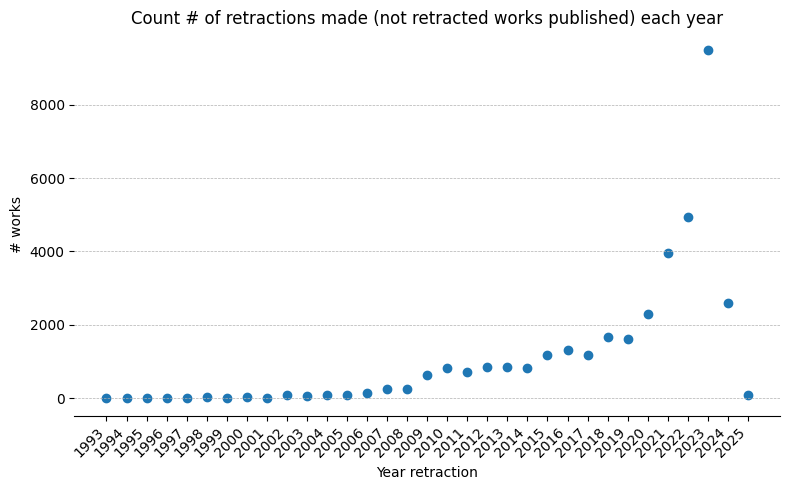

In [71]:
# number of retractions made (not retracted works published) each year

df_merge_full = works_info_retracted_true_full.merge(watch_data[['doi','OriginalPaperDate', 'RetractionDate','RetractionNature']],on='doi')
print(f'{(len(df_merge_full) / len(works_info_retracted_true_full)) * 100:.2f}% retracted works matched')
df_time_full = df_merge_full[['year','RetractionDate']].dropna()
df_time_full['year_retraction'] = df_time_full['RetractionDate'].astype(str).str[:4].astype(int)
df_time_full = df_time_full.drop(columns='RetractionDate')
df_time_full
df_count_full = df_time_full[(df_time_full.year_retraction>=1992) & (df_time_full.year_retraction<=2025)].groupby('year_retraction').year.count().to_frame().reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df_count_full['year_retraction'].values, df_count_full['year'].values)

ax.set_xticks(df_count_full['year_retraction'].values)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_xlabel('Year retraction')
ax.set_ylabel('# works')
ax.set_title('Count # of retractions made (not retracted works published) each year')

ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, which="both", linestyle='--', linewidth=0.5)
ax.xaxis.grid(False)

plt.tight_layout()
plt.show()